# **Analisis Log Jaringan NusaMesh (BLE ↔ LoRa Mesh)**

Notebook ini mengolah log aplikasi NusaMesh dari data mentah sampai menjadi analisis performa jaringan dan dataset siap *machine learning*.

**Alur pengerjaan:**
1. Import Library
2. Parameter yang Digunakan
3. Memuat Dataset
4. Exploratory Data Analysis (EDA) Awal
5. Pembersihan Data (*Data Cleaning*)
6. Pra Pemrosesan Data (*Preprocessing*)
7. Analisis dan Visualisasi
8. Analisis Quality of Service (QoS)
9. Analisis Parameter Uji TA (Dokumen CD-2)
10. Evaluasi Kualitas Log dan Saran Peningkatan Logging
11. Kesimpulan
12. Mengekspor Data

# **INFORMASI DATASET**

Dataset berasal dari log aplikasi Android NusaMesh yang terhubung lewat **BLE** ke node LoRa. Node-node LoRa saling bertukar pesan membentuk jaringan **mesh**. Setiap baris log = **satu kejadian (event)** yang dicatat aplikasi.

Data sesi ini terdiri dari **satu file**:
- `NusaMesh-log-2026-11-12T06-12-26.csv`: log lengkap satu sesi uji tanggal **12 November 2026**, pukul **13:12–13:40 WIB** (3.872 baris).

Kode tetap bisa membaca lebih dari satu file. Jika ada file potongan (mis. `nusamesh-transmission-log-...csv`) yang isinya tumpang tindih, duplikatnya otomatis dibuang.

## Kolom Dataset

| Kolom | Arti | Contoh |
|---|---|---|
| **`sequence`** | Nomor urut event dari aplikasi. Unik dalam satu sesi, dipakai untuk mendeteksi duplikat. | `4046` |
| **`session_id`** | ID sesi aplikasi (satu kali pengujian). | `1794386127183-7e332` |
| **`time_ms`** | Waktu kejadian dalam *epoch* milidetik (UTC). Nanti diubah ke WIB. | `1794387770595` |
| **`layer`** | Bagian sistem yang mencatat event (lihat tabel *Layer*). | `BLE`, `LORA` |
| **`event`** | Nama kejadian (lihat tabel *Event*). | `TX_ACCEPTED` |
| **`level`** | Tingkat keparahan: `INFO` = normal, `WARN` = tidak ideal tapi masih jalan, `ERROR` = operasi gagal. | `WARN` |
| **`device_id`** | Perangkat yang terlibat. Bisa MAC BLE (`F0:24:…`), ID node LoRa (`4e55534e0000000X`), atau ID node lain di mesh. | `4e55534e00000002` |
| **`message_id`** | ID pesan pengguna (UUID) atau file. Hanya terisi untuk event yang berhubungan dengan pesan. | `be0e74bd-…` |
| **`bytes`** | Ukuran data dalam byte. | `256` |
| **`duration_ms`** | Durasi dalam milidetik. Artinya tergantung event: lama tulis BLE (`TX_ACCEPTED`), lama antre (`QUEUE_DEQUEUED`), waktu sampai ACK (`ACK_MATCHED`), lama handover (`MOBILITY_SUCCESS`). | `87` |
| **`rssi_dbm`** | *Received Signal Strength Indicator*: kekuatan sinyal yang diterima (dBm). Selalu negatif, **makin mendekati 0 makin kuat**. | `-96` |
| **`snr_db`** | *Signal-to-Noise Ratio*: seberapa jelas sinyal dibanding noise (dB). **Makin besar makin bersih.** LoRa masih bisa membaca sinyal sampai SNR negatif. | `7.8` |
| **`sf`** | *Spreading Factor* LoRa (7–12). SF7 = paling cepat tapi jangkauan paling pendek. | `7` |
| **`detail`** | Info tambahan berformat `kunci=nilai`, dipisah `;`. Isinya berbeda per event (lihat tabel *Isi Detail*). | `frames=2; total=298` |

## Layer

| Layer | Fungsi |
|---|---|
| **`BLE`** | Koneksi Bluetooth Low Energy antara HP dan node: connect, kirim/terima byte, scan sinyal. |
| **`LORA`** | Laporan radio LoRa di node: frame terkirim/diterima, CRC error, kesehatan node. |
| **`MESH`** | Routing paket antar node: paket masuk, diteruskan (*relay*), duplikat, perpindahan HP antar node (*mobility*). |
| **`QUEUE`** | Antrean kirim di aplikasi dan izin masuk (*admission*) ke antrean node. |
| **`MESSAGE`** | Pesan pengguna: dikirim, diterima, dan konfirmasi (ACK). |
| **`SYSTEM`** | Status layanan mesh di aplikasi: `MESH_STARTED` / `MESH_STOPPED` (layanan dinyalakan / dimatikan). |

## Event Penting

| Layer | Event | Arti |
|---|---|---|
| BLE | `CONNECT_ATTEMPT` / `CONNECTED` / `CONNECT_FAILED` / `DISCONNECTED` | Mencoba connect / berhasil / gagal / putus |
| BLE | `GATT_ERROR` | Error saat menulis data BLE (mis. timeout 2,5 detik, status 133) |
| BLE | `TX_START` / `TX_ACCEPTED` / `TX_FAILED` | Mulai tulis data ke node / berhasil / gagal |
| BLE | `RX_BYTES` | HP menerima data dari node |
| BLE | `RSSI_SCAN` | Hasil scan kekuatan sinyal BLE perangkat di sekitar |
| LORA | `NODE_HEALTH` | Laporan berkala kesehatan node (lihat isi detail) |
| LORA | `NODE_TX_FRAMES` / `NODE_RX_FRAMES` | Node mengirim / menerima frame LoRa |
| LORA | `NODE_RX_CRC_ERROR` | Frame LoRa diterima tapi **rusak** (gagal cek CRC) |
| LORA | `NODE_TX_DROPPED` | Frame **dibuang** karena antrean node penuh |
| LORA | `NODE_RADIO_NOT_READY` / `NODE_RADIO_READY` | Radio LoRa node berhenti siap / siap kembali |
| LORA | `RX_META_MATCHED` | Info sinyal (RSSI/SNR) dari frame terakhir yang melengkapi sebuah paket |
| MESH | `RX_PACKET` | Paket mesh diterima |
| MESH | `RELAYED` | Paket diteruskan ke node lain |
| MESH | `RX_DUPLICATE` | Paket yang sama diterima lagi (diabaikan) |
| MESH | `RX_GUARD_DROP` | Paket milik sendiri kembali lagi (diabaikan) |
| MESH | `MOBILITY_*` | Proses HP pindah dari satu node ke node lain (*handover*) |
| QUEUE | `QUEUE_ACCEPTED` / `QUEUE_DEQUEUED` | Pesan masuk / keluar antrean aplikasi |
| QUEUE | `NODE_ADMISSION_ACCEPTED` / `_BUSY` / `_UNKNOWN` | Node menerima / menolak karena penuh / status tidak diketahui |
| QUEUE | `BATCH_COMPLETE` / `BATCH_FAILED` | Satu batch kiriman berhasil / gagal |
| QUEUE | `NO_PATH` | Aplikasi belum tahu rute ke tujuan |
| MESSAGE | `MESSAGE_SUBMITTED` | Pengguna mengirim pesan |
| MESSAGE | `MESSAGE_LOCAL_ACCEPTED` / `_FAILED` | Pesan berhasil / gagal masuk ke node |
| MESSAGE | `MESSAGE_RECEIVED` | Pesan dari node lain diterima |
| MESSAGE | `ACK_MATCHED` | Konfirmasi (ACK) dari penerima sampai |

## Isi Kolom `detail` yang Dipakai

| Event | Kunci | Arti |
|---|---|---|
| `NODE_HEALTH` | `radio_ready` | Radio LoRa node siap (`true`) atau belum (`false`) |
| `NODE_HEALTH` | `neighbors` | Jumlah node lain yang terdengar |
| `NODE_HEALTH` | `tx`, `rx` | Total frame terkirim / diterima sejak node menyala (kumulatif) |
| `NODE_HEALTH` | `crc`, `dropped` | Total frame rusak / dibuang (kumulatif) |
| `NODE_HEALTH` | `queue` | Jumlah frame yang sedang mengantre di node |
| `NODE_HEALTH` | `budget_ms` | Sisa jatah waktu kirim radio (ms). Dibatasi aturan *duty cycle*; kalau habis, node harus berhenti mengirim sementara. |
| `RX_PACKET`, `RELAYED` | `type` | Jenis paket. Type `24` = beacon, yaitu paket otomatis yang dipancarkan tiap node ±2 detik sekali agar node lain tahu ia aktif* |
| `RX_PACKET`, `RELAYED` | `ttl` | *Time-to-live*: sisa berapa kali paket boleh diteruskan |
| `RX_PACKET` | `sender` | ID node pengirim |
| `NODE_ADMISSION_*` | `free` | Sisa slot kosong di antrean node |
| `BATCH_*` | `pending` | Jumlah pesan yang masih menunggu di antrean aplikasi |
| `QUEUE_ACCEPTED` | `modeled_airtime_ms` | Perkiraan lama pesan "mengudara" di LoRa |
| `MOBILITY_*` | `from`, `to` | Node asal dan tujuan handover |

\* Ditebak dari pola data: type 24 selalu ber-TTL 1, berukuran 62 byte, dan muncul rutin dari setiap node. Beacon ditujukan ke node lain lewat LoRa; HP ikut menerimanya karena node yang terhubung meneruskan semua paket ke HP lewat BLE.

# **1. Import Library**
Semua library yang dibutuhkan diimpor di cell ini.

**Yang dilakukan cell berikut:**
- `sns.set_theme`: tema grafik bergaris tipis

In [1]:
import os, glob, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from scipy.stats import mannwhitneyu
from sklearn.preprocessing import StandardScaler

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 50)

# **2. Parameter yang Digunakan**

Semua angka yang memengaruhi hasil dikumpulkan di satu cell supaya mudah diubah. Penjelasannya:

| Parameter | Nilai | Artinya | Kalau diubah |
|---|---|---|---|
| `DATA_DIR` | `/content/nusamesh` | Folder tempat file CSV log disimpan. | Ganti ke folder Google Drive kalau datanya di sana. |
| `ZONA_WAKTU` | `Asia/Jakarta` | `time_ms` tercatat dalam UTC, diubah ke WIB supaya jamnya cocok dengan waktu pengujian. | – |
| `BATAS_WAJAR` | lihat cell | Rentang nilai yang **mungkin secara fisik**. RSSI tidak mungkin positif dan tidak mungkin di bawah −140 dBm. SNR LoRa praktis −30 s.d. 30 dB. SF LoRa hanya 7–12. Nilai di luar ini dianggap salah catat. | Hanya diubah kalau hardware-nya beda. |
| `IQR_K` | `1.5` | Pengali untuk menentukan **outlier** dengan metode IQR (standar Tukey). Nilai di luar Q1 − 1,5×IQR atau Q3 + 1,5×IQR dianggap outlier. | `3` = hanya nilai sangat ekstrem yang ditandai. |
| `SENSITIVITAS_SF7` | `-124` dBm | RSSI terlemah yang masih bisa diterima radio LoRa pada SF7, bandwidth 125 kHz (nilai tipikal datasheet Semtech). Dipakai sebagai **garis batas** di grafik RSSI. | Sesuaikan dengan datasheet radio dan SF yang dipakai. |
| `SNR_MIN_SF7` | `-7.5` dB | SNR terendah yang masih bisa didemodulasi LoRa pada SF7. Di bawah ini paket hampir pasti gagal dibaca. | SF8 = −10, SF9 = −12,5, SF10 = −15, SF11 = −17,5, SF12 = −20. |
| `JEDA_MIN_HEALTH` | `1` detik | Laporan `NODE_HEALTH` yang datang beruntun (jaraknya < 1 detik) **tidak dipakai** untuk menghitung laju kirim. Alasannya, laju = jumlah frame ÷ waktu, dan pembagi yang sangat kecil (mis. 0,003 detik) menghasilkan lonjakan palsu sampai ratusan frame/detik. | Makin besar, makin banyak laporan yang diabaikan. |
| `UKURAN_WINDOW` | `10s` | Untuk dataset ML, log dipotong per 10 detik, lalu tiap potongan (*window*) dijadikan satu baris fitur. | Lebih kecil = lebih detail tapi banyak window kosong. Lebih besar = data lebih halus tapi barisnya sedikit. |
| `PORSI_TEST` | `0.2` | 20% data **paling akhir** dipakai sebagai data test, 80% awal untuk training. | – |

**Yang dilakukan cell berikut:**
- Lokasi file
- Zona waktu pengujian
- Batas wajar secara fisik: (minimum, maksimum). None = tidak dibatasi
- Pengali IQR untuk menandai outlier
- Batas kemampuan radio LoRa pada SF7 / BW 125 kHz
- `SENSITIVITAS_SF7`: dBm
- `SNR_MIN_SF7`: dB
- Jeda minimum antar laporan NODE_HEALTH untuk menghitung laju kirim
- `JEDA_MIN_HEALTH`: detik
- Dataset machine learning
- Warna tetap untuk tiap node supaya konsisten di semua grafik

In [2]:
DATA_DIR = '/content/nusamesh'
OUT_DIR  = os.path.join(DATA_DIR, 'output')
os.makedirs(OUT_DIR, exist_ok=True)

ZONA_WAKTU = 'Asia/Jakarta'

BATAS_WAJAR = {
    'rssi_dbm':    (-140, 0),
    'snr_db':      (-30, 30),
    'bytes':       (0, None),
    'duration_ms': (0, None),
    'sf':          (7, 12),
}

IQR_K = 1.5

SENSITIVITAS_SF7 = -124.0
SNR_MIN_SF7      = -7.5

JEDA_MIN_HEALTH = 1.0

UKURAN_WINDOW = '10s'
PORSI_TEST    = 0.2

WARNA_NODE = {'NUSN-1': '#2a78d6', 'NUSN-2': '#eb6834', 'NUSN-3': '#1baf7a'}
FORMAT_JAM = mdates.DateFormatter('%H:%M', tz=ZONA_WAKTU)

# **3. Memuat Dataset**
Pada tahap ini kedua file log dimuat dan digabung, lalu dicek strukturnya dengan `head()`, `info()`, dan `describe()`.

> **Penting:** upload **file log mentah** dari aplikasi (`NusaMesh-log-....csv` dan `nusamesh-transmission-log-....csv`), **bukan** file hasil olahan seperti `nusamesh_events_clean.csv`. File yang kolomnya tidak cocok akan otomatis dilewati.

In [3]:
if not glob.glob(os.path.join(DATA_DIR, '*.csv')):
    from google.colab import files
    uploaded = files.upload()
    for nama, isi in uploaded.items():
        with open(os.path.join(DATA_DIR, nama), 'wb') as f:
            f.write(isi)

daftar_file = sorted(glob.glob(os.path.join(DATA_DIR, '*.csv')))
daftar_file

Saving NusaMesh-log-2026-11-12T06-12-26.csv to NusaMesh-log-2026-11-12T06-12-26.csv


['/content/nusamesh/NusaMesh-log-2026-11-12T06-12-26.csv']

**Yang dilakukan cell berikut:**
- Kolom yang WAJIB ada di file log mentah NusaMesh
- Baca setiap file lalu gabungkan menjadi satu DataFrame
- `dtype=str` -> semua kolom dibaca sebagai teks dulu, konversi tipe dilakukan di tahap cleaning
- `encoding` -> 'utf-8-sig' membuang karakter BOM di awal file
- `keep_default_na=False` -> sel kosong dibaca sebagai '' (bukan NaN) supaya bisa diseragamkan nanti
- Lewati file yang kolomnya tidak persis sama dengan log mentah (mis. file hasil olahan / output notebook lain)
- `data['source_file']`: catat asal file setiap baris
- Hentikan dengan pesan jelas kalau tidak ada satu pun log mentah

In [4]:
KOLOM_LOG = ['sequence', 'session_id', 'time_ms', 'layer', 'event', 'level', 'device_id', 'message_id',
             'bytes', 'duration_ms', 'rssi_dbm', 'snr_db', 'sf', 'detail']

list_df = []
for path in daftar_file:
    data = pd.read_csv(path, dtype=str, encoding='utf-8-sig', keep_default_na=False)

    # Log versi baru punya kolom tambahan (mis. local_time). Yang wajib hanya 14 kolom KOLOM_LOG.
    data.columns = data.columns.str.strip()
    if not set(KOLOM_LOG).issubset(data.columns):
        print(f'DILEWATI  {os.path.basename(path)}  (bukan file log mentah NusaMesh)')
        continue

    data['source_file'] = os.path.basename(path)
    print(f'DIPAKAI   {os.path.basename(path)}: {data.shape[0]} baris, {data.shape[1]} kolom')
    list_df.append(data)

if not list_df:
    raise ValueError('Tidak ada file log mentah. Upload file NusaMesh-log-....csv / nusamesh-transmission-log-....csv '
                     '(bukan file hasil olahan seperti nusamesh_events_clean.csv).')

df = pd.concat(list_df, ignore_index=True)
print('Total setelah digabung:', df.shape)

DIPAKAI   NusaMesh-log-2026-11-12T06-12-26.csv: 3872 baris, 15 kolom
Total setelah digabung: (3872, 15)


In [5]:
df.head()

,sequence,session_id,time_ms,layer,event,level,device_id,message_id,bytes,duration_ms,rssi_dbm,snr_db,sf,detail,source_file
0,11917,1794462927496-d72e2,1794463946769,BLE,DISCOVERED,INFO,7B:CF:6F:20:38:BB,,,,-84.0,,,,NusaMesh-log-2026-11-12T06-12-26.csv
1,11918,1794462927496-d72e2,1794463946770,BLE,RSSI_SCAN,INFO,7B:CF:6F:20:38:BB,,,,-84.0,,,,NusaMesh-log-2026-11-12T06-12-26.csv
2,11919,1794462927496-d72e2,1794463948103,BLE,RX_BYTES,INFO,14:2B:2F:93:76:92,,62,,,,,,NusaMesh-log-2026-11-12T06-12-26.csv
3,11920,1794462927496-d72e2,1794463948105,MESH,RX_PACKET,INFO,14:2B:2F:93:76:92,,62,,,,,type=24; sender=4e55534e00000003; ttl=1,NusaMesh-log-2026-11-12T06-12-26.csv
4,11921,1794462927496-d72e2,1794463948106,LORA,NODE_TX_FRAMES,INFO,4e55534e00000003,,,,,,,frames=1; total=272; queue=22; budget_ms=27,NusaMesh-log-2026-11-12T06-12-26.csv


**Yang dilakukan cell berikut:**
- Tinjau jumlah baris, kolom, dan tipe data

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3872 entries, 0 to 3871
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   sequence     3872 non-null   str  
 1   session_id   3872 non-null   str  
 2   time_ms      3872 non-null   str  
 3   layer        3872 non-null   str  
 4   event        3872 non-null   str  
 5   level        3872 non-null   str  
 6   device_id    3872 non-null   str  
 7   message_id   3872 non-null   str  
 8   bytes        3872 non-null   str  
 9   duration_ms  3872 non-null   str  
 10  rssi_dbm     3872 non-null   str  
 11  snr_db       3872 non-null   str  
 12  sf           3872 non-null   str  
 13  detail       3872 non-null   str  
 14  source_file  3872 non-null   str  
dtypes: str(15)
memory usage: 453.9 KB


In [7]:
df.describe()

,sequence,session_id,time_ms,layer,event,level,device_id,message_id,bytes,duration_ms,rssi_dbm,snr_db,sf,detail,source_file
count,3872,3872,3872,3872,3872,3872,3872,3872,3872,3872,3872,3872,3872,3872,3872
unique,3872,1,3067,6,57,3,16,91,67,206,52,42,2,697,1
top,11917,1794462927496-d72e2,1794464064919,BLE,RX_BYTES,INFO,14:2B:2F:93:76:92,,,,,,,,NusaMesh-log-2026-11-12T06-12-26.csv
freq,1,3872,8,1592,880,3462,1357,3336,1820,3541,3367,3598,3733,1612,3872


Dataset berisi **3.872 baris** dan 15 kolom (14 kolom log + `source_file`). Semua kolom masih bertipe teks karena sengaja dibaca sebagai string. Dari `describe()` terlihat:
- `session_id` hanya punya **1 nilai unik**, jadi seluruh data berasal dari satu sesi uji.
- `sequence` punya **3.872 nilai unik** dari 3.872 baris. Artinya **tidak ada baris duplikat**, karena hanya satu file yang dipakai.
- Ada **6 layer**. Selain 5 layer utama, muncul layer `SYSTEM` (event `MESH_STARTED`/`MESH_STOPPED`).
- Layer paling sering adalah **BLE** (1.592 baris) dan event paling sering adalah **RX_BYTES** (880 baris).

# **4. Exploratory Data Analysis (EDA) Awal**
Melihat komposisi data sebelum dibersihkan: berapa banyak event per layer, per level, dan event apa saja yang paling sering muncul.

**Yang dilakukan cell berikut:**
- Jumlah event per layer
- Jumlah event per level, warna menyesuaikan tingkat keparahan
- `axes[1].bar_label`: tulis angka di atas batang

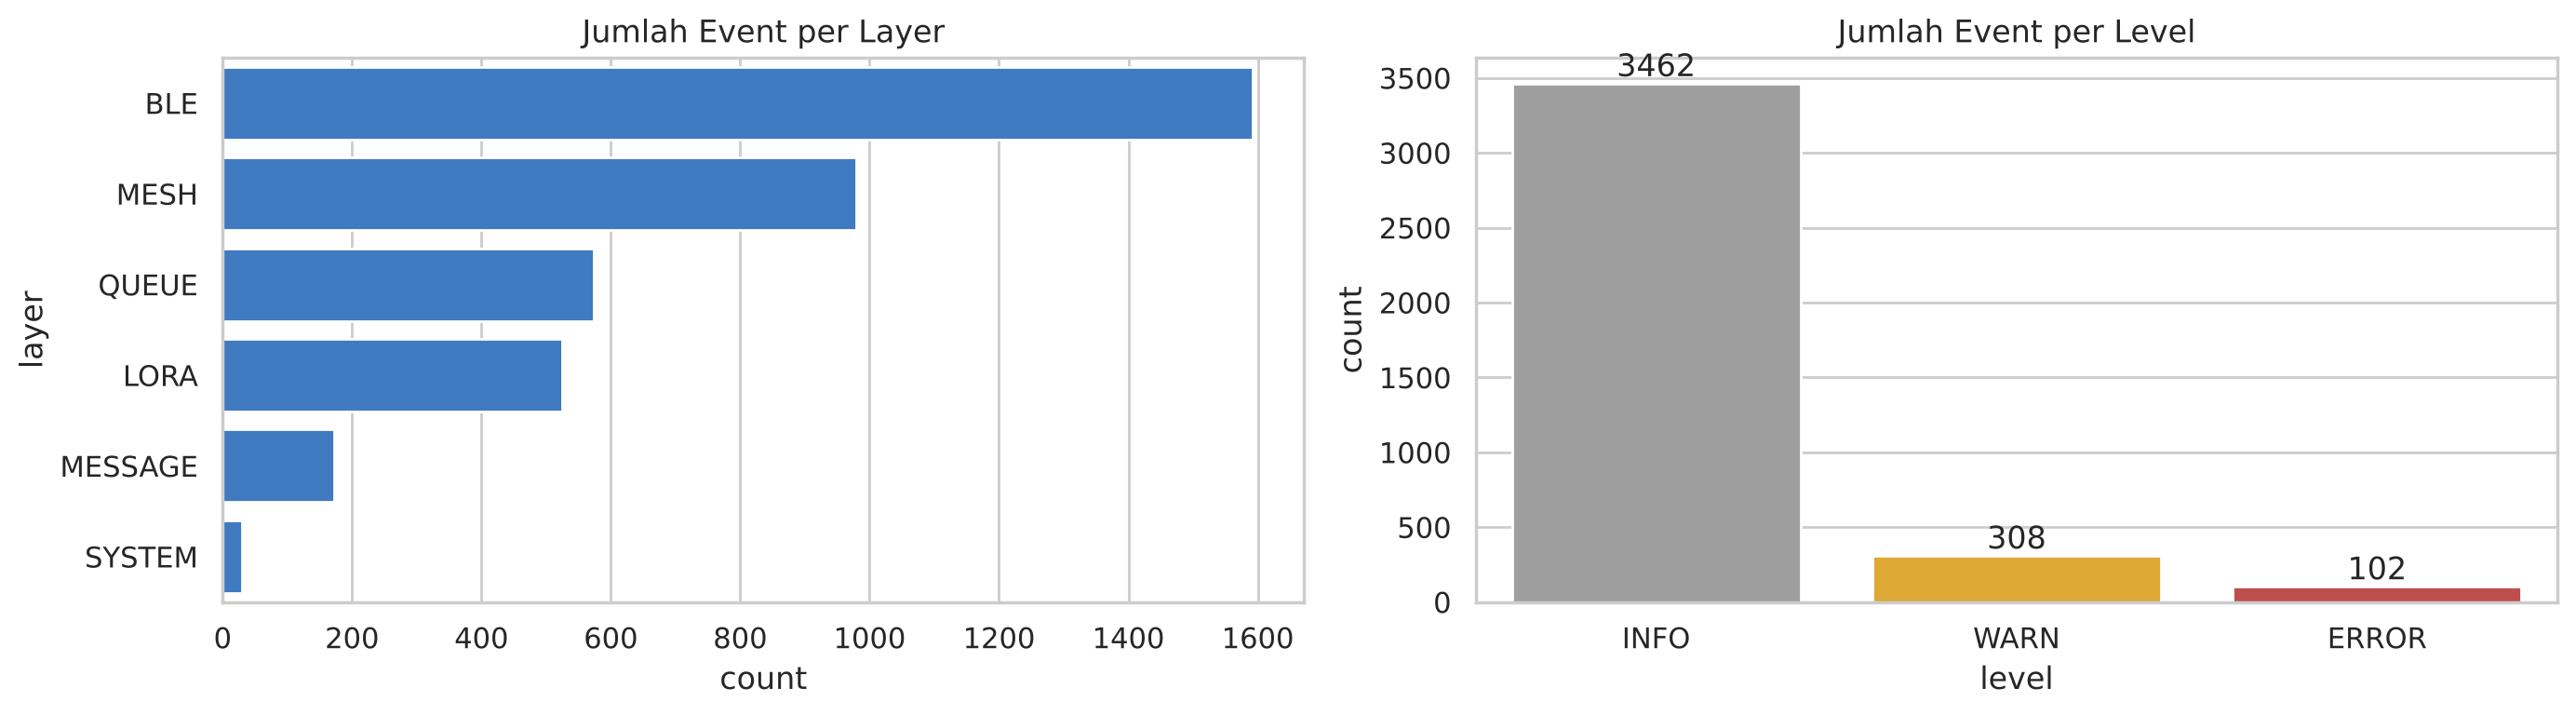

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.countplot(data=df, y='layer', order=df['layer'].value_counts().index, ax=axes[0], color='#2a78d6')
axes[0].set_title('Jumlah Event per Layer')

sns.countplot(data=df, x='level', order=['INFO', 'WARN', 'ERROR'], ax=axes[1],
              hue='level', palette={'INFO': '#9e9e9e', 'WARN': '#fab219', 'ERROR': '#d03b3b'}, legend=False)
axes[1].set_title('Jumlah Event per Level')
axes[1].bar_label(axes[1].containers[0]); axes[1].bar_label(axes[1].containers[1]); axes[1].bar_label(axes[1].containers[2])

plt.tight_layout()
plt.show()

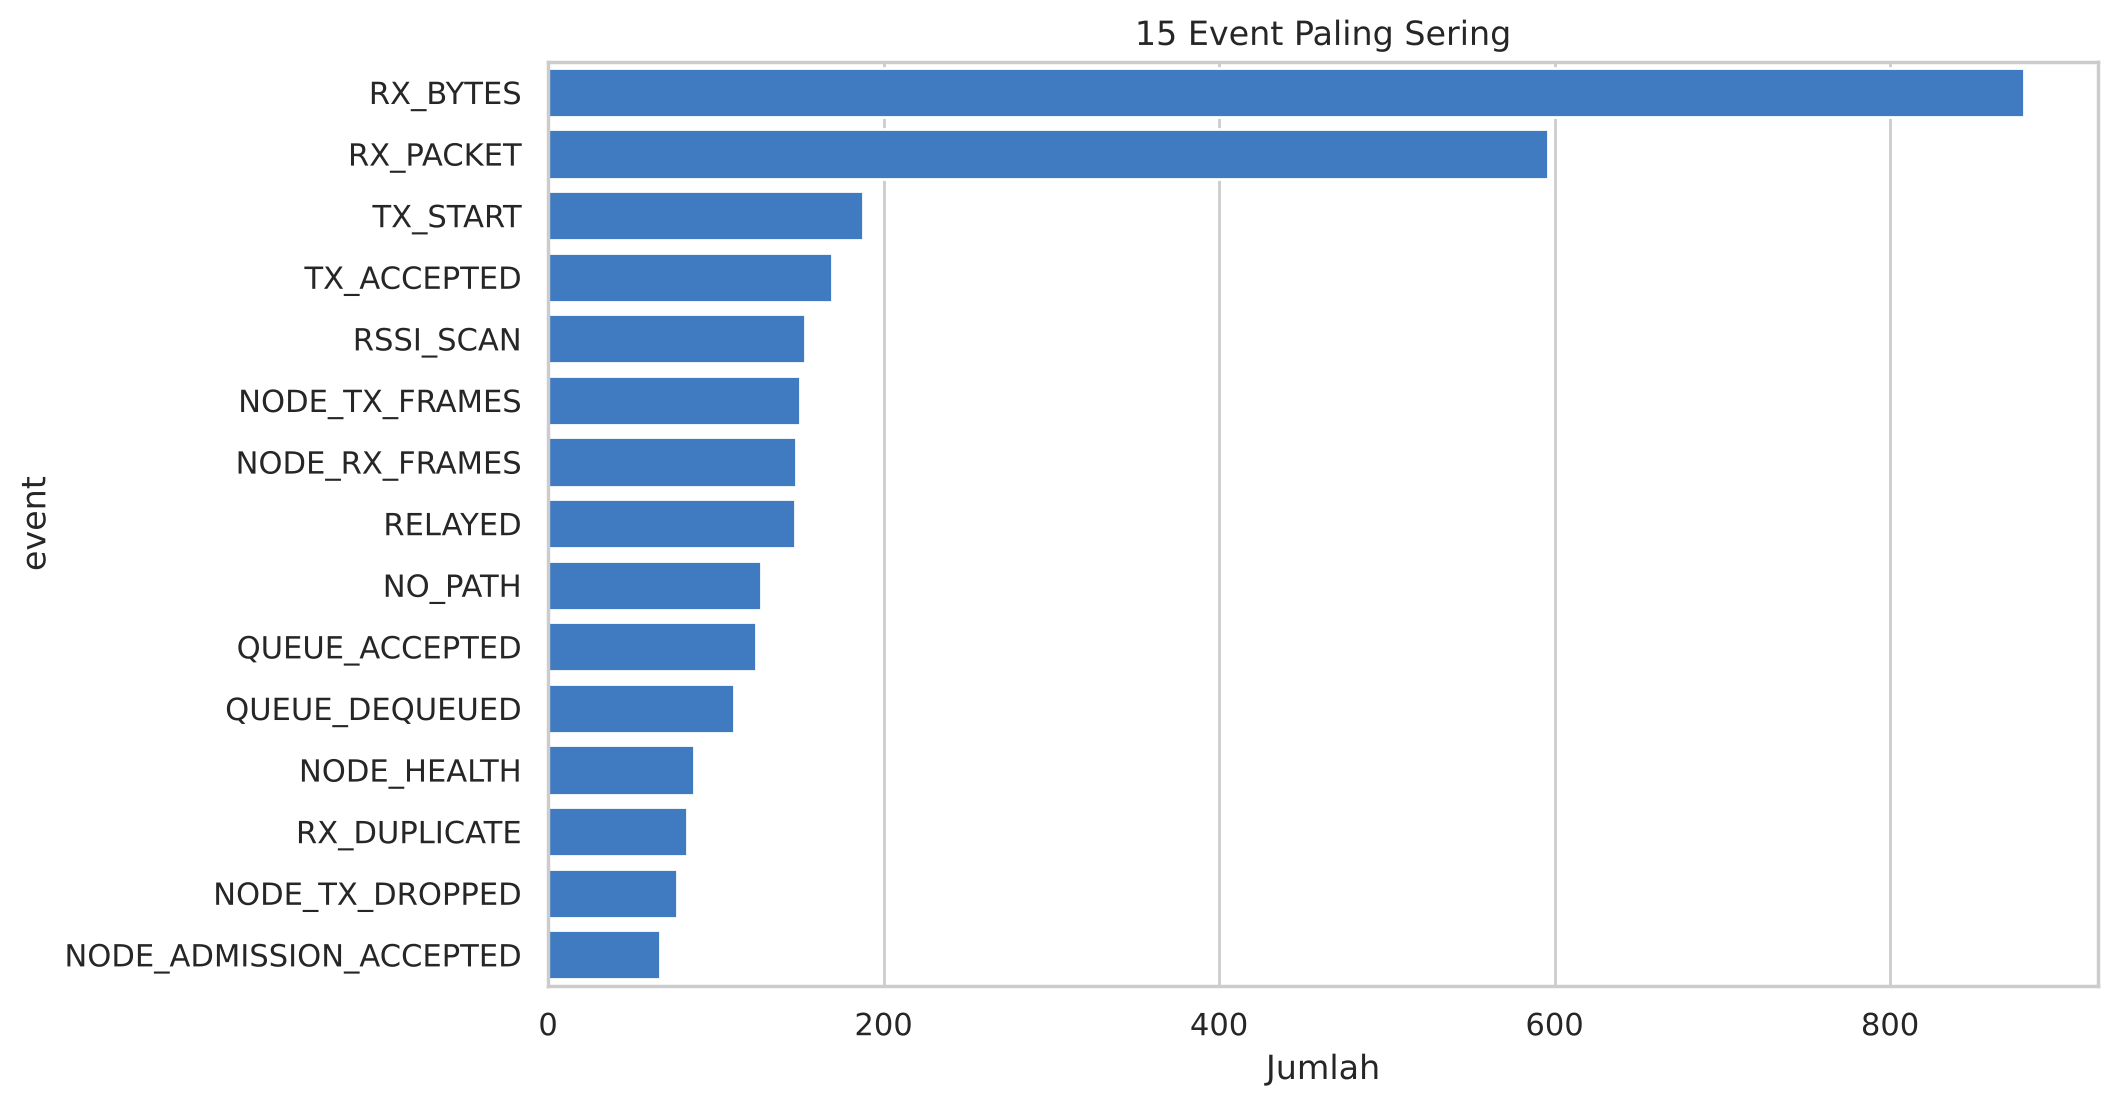

In [9]:
top_event = df['event'].value_counts().head(15)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_event.values, y=top_event.index, color='#2a78d6')
plt.title('15 Event Paling Sering')
plt.xlabel('Jumlah')
plt.show()

- **BLE** adalah layer paling ramai (1.592 event) karena setiap byte yang lewat antara HP dan node dicatat (`RX_BYTES`, `TX_START`, `TX_ACCEPTED`), ditambah scan sinyal rutin (`RSSI_SCAN`).
- Sebagian besar event berlevel **INFO** (3.462 atau 89,4%). Sisanya **308 WARN** dan **102 ERROR**. Jumlah ini cukup banyak, dan akan dibahas di analisis.
- `RX_PACKET` (paket mesh masuk, 596) dan `RELAYED` (147) termasuk event terbanyak, tanda jaringan mesh aktif bertukar data.
- `NO_PATH` (127) dan `NODE_TX_DROPPED` (77) masuk 15 besar. Artinya cukup sering aplikasi belum tahu rute tujuan, dan node membuang frame karena antreannya penuh.

# **5. Pembersihan Data (Data Cleaning)**

Langkah yang dilakukan:
1. Menyeragamkan sel kosong lalu mengecek dengan `isnull().sum()`.
2. Mengecek dan menghapus duplikat dengan `duplicated().sum()`.
3. Mengubah tipe data (teks → angka).
4. Mengubah `time_ms` menjadi waktu WIB dan mengecek urutan.
5. Memvalidasi nilai yang tidak masuk akal secara fisik.
6. Menandai outlier dengan metode IQR.

## 5.1 Mengecek Data Kosong

In [10]:
kolom_log = KOLOM_LOG
for kolom in kolom_log:
    df[kolom] = df[kolom].str.strip()

df[kolom_log] = df[kolom_log].replace(['', 'null', 'NULL', 'NaN', 'None'], np.nan)

df.isnull().sum()

sequence          0
session_id        0
time_ms           0
layer             0
event             0
level             0
device_id       318
message_id     3336
bytes          1820
duration_ms    3541
rssi_dbm       3367
snr_db         3598
sf             3733
detail         1612
source_file       0
dtype: int64

Banyak kolom yang kosong (misalnya `snr_db`, `sf`, `duration_ms`), tapi ini **bukan data rusak**. Kolom-kolom tersebut memang hanya diisi oleh event tertentu. Contohnya, `snr_db` hanya ada pada event penerimaan LoRa, dan `message_id` hanya ada pada event yang berhubungan dengan pesan. Karena itu, **baris dengan data kosong tidak dihapus** (kalau `dropna()` dipakai, hampir semua data akan hilang). Kolom wajib (`sequence`, `time_ms`, `layer`, `event`, `level`) terisi semua.

## 5.2 Mengecek dan Menghapus Data Duplikat

**Yang dilakukan cell berikut:**
- Satu event unik ditentukan oleh pasangan (session_id, sequence)

In [11]:
df.duplicated(subset=['session_id', 'sequence']).sum()

np.int64(0)

In [12]:
asal_file = df.groupby(['session_id', 'sequence'])['source_file'].agg(lambda x: ' | '.join(sorted(set(x))))

df = df.drop_duplicates(subset=['session_id', 'sequence'], keep='first').drop(columns='source_file')
df = df.merge(asal_file.rename('source_files'), on=['session_id', 'sequence'])

df.duplicated(subset=['session_id', 'sequence']).sum()

np.int64(0)

**Tidak ada baris duplikat** (hasilnya 0), karena sesi ini hanya punya satu file log. Seluruh **3.872 event** dipakai. Kolom `source_files` tetap dibuat untuk mencatat file asal tiap event.

## 5.3 Mengubah Tipe Data

In [13]:
for kolom in ['rssi_dbm', 'snr_db']:
    df[kolom] = pd.to_numeric(df[kolom], errors='coerce').round(2)

for kolom in ['sequence', 'time_ms', 'bytes', 'duration_ms', 'sf']:
    df[kolom] = pd.to_numeric(df[kolom], errors='coerce').astype('Int64')

df.dtypes

sequence          Int64
session_id          str
time_ms           Int64
layer               str
event               str
level               str
device_id           str
message_id          str
bytes             Int64
duration_ms       Int64
rssi_dbm        float64
snr_db          float64
sf                Int64
detail              str
source_files        str
dtype: object

Kolom angka sekarang bertipe numerik. Angka desimal panjang dari firmware (contoh `7.800000190734863`) sudah dibulatkan ke 2 desimal. `errors='coerce'` akan mengubah teks yang bukan angka menjadi NaN, tapi pada data ini tidak ada nilai yang terbuang.

## 5.4 Mengubah Waktu dan Mengecek Urutan

**Yang dilakukan cell berikut:**
- `time_ms` (milidetik sejak 1970, UTC) -> waktu WIB
- Urutkan berdasarkan waktu
- Detik sejak awal sesi (berguna untuk sumbu x yang sederhana)
- Cek apakah ada nomor sequence yang hilang

In [14]:
df['waktu'] = pd.to_datetime(df['time_ms'].astype('int64'), unit='ms', utc=True).dt.tz_convert(ZONA_WAKTU)

df = df.sort_values(['time_ms', 'sequence']).reset_index(drop=True)

df['detik_ke'] = (df['time_ms'] - df['time_ms'].min()) / 1000

jumlah_seharusnya = df['sequence'].max() - df['sequence'].min() + 1
print('Waktu mulai   :', df['waktu'].min())
print('Waktu selesai :', df['waktu'].max())
print('Sequence hilang:', jumlah_seharusnya - df['sequence'].nunique())

Waktu mulai   : 2026-11-12 13:12:26.769000+07:00
Waktu selesai : 2026-11-12 13:39:59.124000+07:00
Sequence hilang: 0


## 5.5 Validasi Nilai Tidak Wajar

**Yang dilakukan cell berikut:**
- Nilai di luar BATAS_WAJAR diganti NaN

In [15]:
for kolom, (batas_bawah, batas_atas) in BATAS_WAJAR.items():
    tidak_wajar = pd.Series(False, index=df.index)
    if batas_bawah is not None:
        tidak_wajar |= df[kolom] < batas_bawah
    if batas_atas is not None:
        tidak_wajar |= df[kolom] > batas_atas
    tidak_wajar = tidak_wajar.fillna(False)

    df.loc[tidak_wajar, kolom] = np.nan
    print(f'{kolom:12s}: {int(tidak_wajar.sum())} nilai tidak wajar')

rssi_dbm    : 0 nilai tidak wajar
snr_db      : 0 nilai tidak wajar
bytes       : 0 nilai tidak wajar
duration_ms : 0 nilai tidak wajar
sf          : 0 nilai tidak wajar


## 5.6 Menandai Outlier (Metode IQR)

**Yang dilakukan cell berikut:**
- Outlier dihitung PER EVENT karena tiap event punya skala berbeda
- `(contoh:` durasi tulis BLE ~60 ms, sedangkan latency ACK ~5.000 ms)
- `nilai`: pastikan bertipe float supaya bisa dibandingkan
- Hanya DITANDAI di kolom baru, tidak dihapus

In [16]:
for kolom in ['rssi_dbm', 'snr_db', 'duration_ms']:
    nilai = df[kolom].astype(float)
    Q1 = nilai.groupby(df['event']).transform(lambda x: x.quantile(0.25))
    Q3 = nilai.groupby(df['event']).transform(lambda x: x.quantile(0.75))
    IQR = Q3 - Q1

    batas_bawah = Q1 - IQR_K * IQR
    batas_atas  = Q3 + IQR_K * IQR

    df[f'outlier_{kolom}'] = ((nilai < batas_bawah) | (nilai > batas_atas)).fillna(False)
    print(f'{kolom:12s}: {int(df[f"outlier_{kolom}"].sum())} outlier')

rssi_dbm    : 47 outlier
snr_db      : 43 outlier
duration_ms : 34 outlier


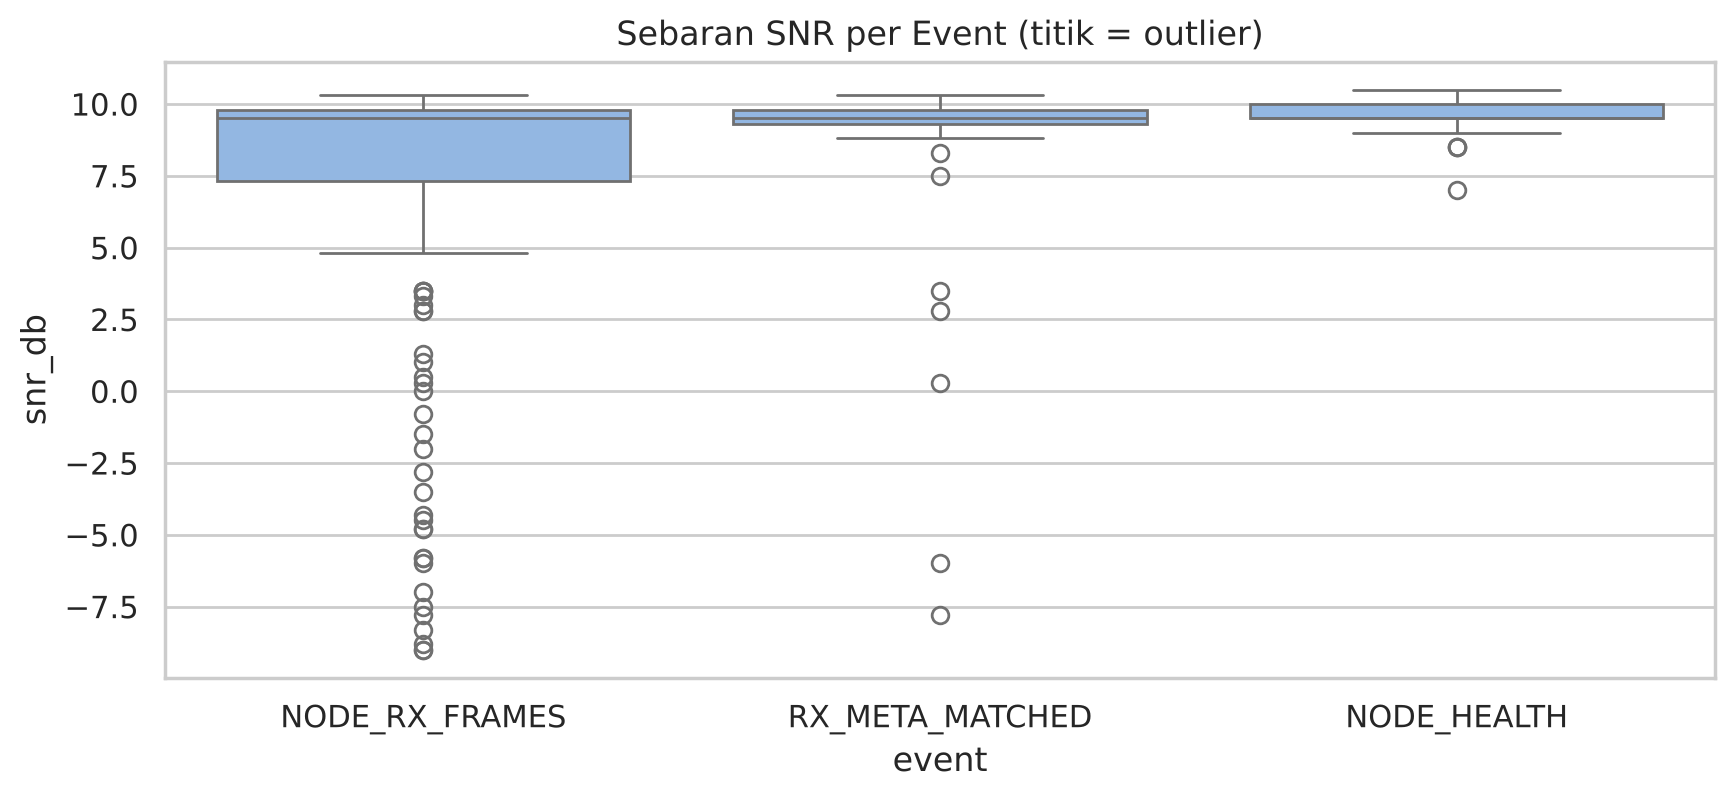

In [17]:
plt.figure(figsize=(10, 4))
sns.boxplot(data=df.dropna(subset=['snr_db']), x='event', y='snr_db', color='#86b6ef')
plt.title('Sebaran SNR per Event (titik = outlier)')
plt.show()

Outlier **hanya ditandai, tidak dihapus** (RSSI: 47, SNR: 43, durasi: 34). Ini berbeda dari dataset transaksi biasa: di data jaringan, nilai ekstrem seperti SNR sangat rendah atau antrean sangat lama justru **kejadian penting** yang ingin dianalisis. Kalau dihapus, masalah jaringan malah tidak kelihatan. Terlihat SNR mayoritas sekitar **9–10 dB**, dengan sebagian frame `NODE_RX_FRAMES` turun sampai **−9 dB** (titik-titik di bawah).

# **6. Pra Pemrosesan Data (Preprocessing)**

Langkah yang dilakukan:
1. Memecah kolom `detail` menjadi kolom-kolom terpisah.
2. Mengenali jenis perangkat dari `device_id`.
3. Membentuk tabel turunan untuk analisis: kesehatan node, sinyal LoRa, dan pesan.
4. Membentuk dataset machine learning (fitur per window, encoding, scaling, split).

## 6.1 Memecah Kolom `detail`

**Yang dilakukan cell berikut:**
- Contoh isi kolom detail sebelum dipecah

In [18]:
df.loc[df['detail'].notna(), ['event', 'detail']].drop_duplicates('event').head(8)

,event,detail
3,RX_PACKET,type=24; sender=4e55534e00000003; ttl=1
4,NODE_TX_FRAMES,frames=1; total=272; queue=22; budget_ms=27
5,QUEUE_ACCEPTED,fragments=1; pending=19; modeled_airtime_ms=87
8,TX_ACCEPTED,Stack BLE only; type=1; node=false
11,RX_DUPLICATE,Duplicate; type=4; ttl=7
14,NODE_RX_FRAMES,frames=1; total=256; last_frame_signal
22,RELAYED,type=1; ttl=3
27,ACK_MATCHED,First receiver ACK since first submission; inc...


**Yang dilakukan cell berikut:**
- Ubah teks 'a=1; b=2; catatan' menjadi dictionary {'a': '1', 'b': '2'}
- Terapkan ke setiap baris, hasilnya jadi DataFrame baru
- Ubah 'true'/'false' menjadi True/False, dan teks angka menjadi angka
- Kunci detail yang namanya sama dengan kolom yang sudah ada (mis. 'sf') TIDAK dibuang:
- Nilainya dipakai untuk mengisi kolom asli pada baris yang kolom aslinya kosong
- Kunci 'node' di detail (true/false pada TX_ACCEPTED/TX_FAILED) diganti nama,
- Karena nama 'node' nanti dipakai untuk label node (bagian 6.2)

In [19]:
def pecah_detail(teks):
    hasil = {}
    for bagian in str(teks).split(';'):
        if '=' in bagian:
            kunci, nilai = bagian.split('=', 1)
            kunci = kunci.strip().replace(' ', '_')
            hasil[kunci] = nilai.strip()
    return hasil

detail_df = pd.DataFrame(df['detail'].apply(pecah_detail).tolist(), index=df.index)

for kolom in detail_df.columns:
    isi = detail_df[kolom].dropna()
    if isi.isin(['true', 'false']).all() and len(isi) > 0:
        detail_df[kolom] = detail_df[kolom].map({'true': True, 'false': False})
    elif pd.to_numeric(isi, errors='coerce').notna().all() and len(isi) > 0:
        detail_df[kolom] = pd.to_numeric(detail_df[kolom], errors='coerce')

kunci_sama = [k for k in detail_df.columns if k in df.columns]
for k in kunci_sama:
    terisi = df[k].isna() & detail_df[k].notna()
    df[k] = df[k].astype(float).fillna(pd.to_numeric(detail_df[k], errors='coerce')).astype(df[k].dtype)
    print(f"Kolom '{k}': {terisi.sum()} nilai kosong diisi dari detail")
detail_df = detail_df.drop(columns=kunci_sama)

detail_df = detail_df.rename(columns={'node': 'detail_node'})

df = pd.concat([df, detail_df], axis=1)
print('Kolom baru dari detail:', len(detail_df.columns), detail_df.columns.tolist())

Kolom 'sf': 107 nilai kosong diisi dari detail
Kolom baru dari detail: 37 ['type', 'sender', 'ttl', 'frames', 'total', 'queue', 'budget_ms', 'fragments', 'pending', 'modeled_airtime_ms', 'detail_node', 'bw_khz', 'hop_left', 'neighbors', 'source', 'test_mode', 'radio_ready', 'dual_radio', 'tx', 'rx', 'dropped', 'crc', 'confirmed', 'free', 'from', 'to', 'serving_rssi', 'users', 'write_timeout_ms', 'set', 'requested', 'resending', 'mtu', 'central', 'write_callback_status', 'missing', 'kandidat']


**Yang dilakukan cell berikut:**
- Cek hasilnya pada event NODE_HEALTH

In [20]:
df.loc[df['event'] == 'NODE_HEALTH', ['device_id', 'radio_ready', 'neighbors', 'tx', 'rx', 'crc', 'dropped', 'queue', 'budget_ms']].head()

,device_id,radio_ready,neighbors,tx,rx,crc,dropped,queue,budget_ms
48,4e55534e00000003,True,1.0,272.0,258.0,0.0,226.0,23.0,327.0
135,4e55534e00000003,True,1.0,274.0,260.0,0.0,231.0,23.0,161.0
165,4e55534e00000003,True,1.0,275.0,262.0,0.0,231.0,23.0,261.0
226,4e55534e00000003,True,1.0,277.0,265.0,0.0,236.0,23.0,161.0
299,4e55534e00000003,True,1.0,279.0,272.0,0.0,242.0,21.0,131.0


**Yang dilakukan cell berikut:**
- `Audit:` pastikan tidak ada informasi dari kolom detail yang hilang saat dipecah

In [21]:
punya = df['detail'].apply(pecah_detail)
audit = []
for k in sorted(set().union(*punya)):
    kolom = 'detail_node' if k == 'node' else k
    baris = punya.apply(lambda d: k in d and d[k] not in ('', 'null'))
    audit.append({'kunci_detail': k, 'kolom_hasil': kolom,
                  'baris_berisi_di_detail': int(baris.sum()),
                  'baris_terisi_di_kolom': int(df.loc[baris, kolom].notna().sum())})
audit = pd.DataFrame(audit)
audit['selisih'] = audit['baris_berisi_di_detail'] - audit['baris_terisi_di_kolom']
print('Jumlah kunci detail :', len(audit))
print('Total nilai hilang  :', int(audit['selisih'].sum()))
audit

Jumlah kunci detail : 38
Total nilai hilang  : 0


,kunci_detail,kolom_hasil,baris_berisi_di_detail,baris_terisi_di_kolom,selisih
0,budget_ms,budget_ms,237,237,0
1,bw_khz,bw_khz,52,52,0
2,central,central,19,19,0
3,confirmed,confirmed,107,107,0
4,crc,crc,87,87,0
5,dropped,dropped,87,87,0
6,dual_radio,dual_radio,89,89,0
7,fragments,fragments,229,229,0
8,frames,frames,383,383,0
9,free,free,100,100,0


Kolom `detail` berisi **38 kunci**: 37 menjadi kolom baru dan 1 (`sf`) digabung ke kolom asli, misalnya `radio_ready`, `neighbors`, `tx`, `rx`, `crc`, `budget_ms`, `type`, dan `ttl`. Ada satu kunci baru dibanding format sebelumnya, yaitu `kandidat` (jumlah kandidat node saat `MOBILITY_ELECTED`). Nilai `true`/`false` sudah menjadi boolean dan angka sudah numerik, jadi bisa langsung dihitung.

**Tidak ada kolom yang dibuang.**
- Kunci `sf` di detail dipakai untuk mengisi **107 nilai** kolom `sf` yang kosong (event `NODE_ADMISSION_*`).
- Kunci `node` (nilai true/false pada `TX_ACCEPTED`/`TX_FAILED`, artinya belum terdokumentasi) disimpan sebagai `detail_node`.
- Tabel audit membuktikan semua nilai di `detail` sudah pindah ke kolomnya masing-masing (total selisih 0).

## 6.2 Mengenali Jenis Perangkat

**Yang dilakukan cell berikut:**
- ID node LoRa berawalan '4e55534e' (= 'NUSN' dalam kode ASCII), 8 digit terakhir = nomor node
- Nama node yang mudah dibaca: 4e55534e00000002 -> NUSN-2

In [22]:
pola_node = r'^4e55534e[0-9a-f]{8}$'
pola_mac  = r'^[0-9A-Fa-f]{2}(:[0-9A-Fa-f]{2}){5}$'

id_teks = df['device_id'].fillna('')
df['jenis_perangkat'] = np.select(
    [id_teks == '', id_teks.str.match(pola_mac), id_teks.str.match(pola_node)],
    ['aplikasi (tanpa ID)', 'BLE (node/perangkat lain)', 'node LoRa'],
    default='node mesh lain',
)

def nama_node(x):
    x = str(x)
    return f'NUSN-{int(x[-8:], 16)}' if re.match(pola_node, x) else np.nan

df['node'] = df['device_id'].apply(nama_node)

df.groupby(['jenis_perangkat', 'device_id'], dropna=False).size().sort_values(ascending=False).head(12)

jenis_perangkat            device_id        
BLE (node/perangkat lain)  14:2B:2F:93:76:92    1357
                           64:B7:08:AD:2E:DA    1042
                           55:07:37:C1:3B:5B     340
node LoRa                  4e55534e00000003      327
aplikasi (tanpa ID)        NaN                   318
node LoRa                  4e55534e00000001      237
BLE (node/perangkat lain)  41:DC:35:23:21:2E     100
                           4C:38:3D:57:96:F5      51
                           5F:64:2C:DC:E3:AA      49
                           46:D8:F4:0E:2A:B4      18
node mesh lain             9effb8dc2debb2fb        9
BLE (node/perangkat lain)  55:9C:A3:EF:8E:46       9
dtype: int64

Ada **2 node LoRa** yang aktif di sesi ini: **NUSN-1** dan **NUSN-3** (NUSN-2 tidak muncul sama sekali). Selain itu ada **10 alamat BLE** (2 di antaranya alamat BLE milik node itu sendiri, lihat 7.6) dan **3 ID mesh lain** yang hanya muncul sebagai pengirim paket (kemungkinan ID pengguna/ponsel lain, ditulis HP-xxxx di bagian 9.3). Event tanpa `device_id` adalah event internal aplikasi (contoh: `MESSAGE_SUBMITTED`, `NO_PATH`, `MESH_STARTED`).

## 6.3 Tabel Kesehatan Node

Diambil dari event `NODE_HEALTH`. Kolom `tx`, `rx`, `crc`, `dropped` bersifat **kumulatif** (terus bertambah sejak node menyala), jadi diubah menjadi **selisih** antar laporan untuk tahu berapa kejadian di setiap interval.

$$
\text{CRC error rate} = \frac{\Delta \text{crc}}{\Delta \text{rx} + \Delta \text{crc}} \qquad
\text{Drop rate} = \frac{\Delta \text{dropped}}{\Delta \text{tx} + \Delta \text{dropped}}
$$

**Yang dilakukan cell berikut:**
- Selisih counter kumulatif per node (diff = nilai sekarang - nilai sebelumnya)
- Jarak waktu antar laporan (detik)
- Laju kirim per detik, hanya untuk laporan yang jedanya >= JEDA_MIN_HEALTH
- Laporan pertama tiap node tidak punya pembanding, jadi dibuang

In [23]:
kolom_health = ['waktu', 'time_ms', 'node', 'rssi_dbm', 'snr_db', 'radio_ready', 'neighbors',
                'tx', 'rx', 'crc', 'dropped', 'queue', 'budget_ms']
health = df.loc[df['event'] == 'NODE_HEALTH', kolom_health].sort_values(['node', 'time_ms']).copy()

for kolom in ['tx', 'rx', 'crc', 'dropped']:
    health[f'tambah_{kolom}'] = health.groupby('node')[kolom].diff().clip(lower=0)

health['jeda_detik'] = health.groupby('node')['time_ms'].diff().astype(float) / 1000

health['tx_per_detik'] = np.where(health['jeda_detik'] >= JEDA_MIN_HEALTH,
                                  health['tambah_tx'] / health['jeda_detik'], np.nan)

health = health.dropna(subset=['jeda_detik']).reset_index(drop=True)
health.head()

,waktu,time_ms,node,rssi_dbm,snr_db,radio_ready,neighbors,tx,rx,crc,dropped,queue,budget_ms,tambah_tx,tambah_rx,tambah_crc,tambah_dropped,jeda_detik,tx_per_detik
0,2026-11-12 13:19:28.249000+07:00,1794464368249,NUSN-1,-92.0,9.0,True,1.0,226.0,157.0,0.0,1.0,18.0,308.0,61.0,62.0,0.0,1.0,191.919,0.317842
1,2026-11-12 13:19:40.452000+07:00,1794464380452,NUSN-1,-92.0,9.0,True,1.0,229.0,159.0,0.0,7.0,18.0,16.0,3.0,2.0,0.0,6.0,12.203,0.245841
2,2026-11-12 13:19:52.323000+07:00,1794464392323,NUSN-1,-92.0,9.0,True,1.0,230.0,161.0,0.0,11.0,18.0,217.0,1.0,2.0,0.0,4.0,11.871,0.084239
3,2026-11-12 13:20:02.538000+07:00,1794464402538,NUSN-1,-92.0,9.0,True,1.0,232.0,163.0,0.0,18.0,18.0,225.0,2.0,2.0,0.0,7.0,10.215,0.195791
4,2026-11-12 13:20:13.204000+07:00,1794464413204,NUSN-1,-92.0,9.0,True,1.0,234.0,164.0,0.0,18.0,18.0,148.0,2.0,1.0,0.0,0.0,10.666,0.187512


## 6.4 Tabel Sinyal LoRa

**Yang dilakukan cell berikut:**
- Ambil frame LoRa yang diterima dan punya nilai RSSI
- Node penerima (RX_META_MATCHED tercatat atas MAC BLE, jadi diambil yang dari NODE_RX_FRAMES saja untuk per-node)
- `Margin` = jarak sinyal ke batas minimum. Positif = aman, negatif = di bawah batas
- Kelas kualitas link berdasarkan SNR

In [24]:
sinyal = df[df['event'].isin(['NODE_RX_FRAMES', 'RX_META_MATCHED']) & df['rssi_dbm'].notna()].copy()

sinyal = sinyal[sinyal['node'].notna()]

sinyal['margin_rssi'] = sinyal['rssi_dbm'] - SENSITIVITAS_SF7
sinyal['margin_snr']  = sinyal['snr_db'] - SNR_MIN_SF7

sinyal['kualitas'] = pd.cut(sinyal['snr_db'],
                            bins=[-np.inf, SNR_MIN_SF7, 0, 5, np.inf],
                            labels=['Di bawah batas', 'Lemah', 'Cukup', 'Baik'], right=False)
sinyal[['waktu', 'node', 'rssi_dbm', 'snr_db', 'margin_rssi', 'margin_snr', 'kualitas']].head()

,waktu,node,rssi_dbm,snr_db,margin_rssi,margin_snr,kualitas
14,2026-11-12 13:12:30.085000+07:00,NUSN-3,-87.0,9.8,37.0,17.3,Baik
30,2026-11-12 13:12:32.067000+07:00,NUSN-3,-90.0,9.5,34.0,17.0,Baik
46,2026-11-12 13:12:34.065000+07:00,NUSN-3,-91.0,9.3,33.0,16.8,Baik
92,2026-11-12 13:12:38.100000+07:00,NUSN-3,-92.0,9.5,32.0,17.0,Baik
114,2026-11-12 13:12:42.062000+07:00,NUSN-3,-93.0,9.5,31.0,17.0,Baik


## 6.5 Tabel Pesan
Setiap pesan punya beberapa event (dikirim → masuk antrean → ditulis ke node → ACK). Event-event itu diringkas menjadi **satu baris per pesan** dengan `pd.crosstab`.

**Yang dilakukan cell berikut:**
- Hitung jumlah tiap event per message_id (baris = pesan, kolom = event)
- Tambah informasi penting
- Arah pesan
- Status akhir (dicek berurutan dari atas)

In [25]:
event_pesan = df[df['message_id'].notna()]

pesan = pd.crosstab(event_pesan['message_id'], event_pesan['event'])

pesan['waktu_mulai']    = event_pesan.groupby('message_id')['waktu'].min()
pesan['jumlah_kirim']   = pesan['TX_START']
pesan['lama_antre_ms']  = event_pesan[event_pesan['event'] == 'QUEUE_DEQUEUED'].groupby('message_id')['duration_ms'].max()
pesan['latency_ack_ms'] = event_pesan[event_pesan['event'] == 'ACK_MATCHED'].groupby('message_id')['duration_ms'].min()

keluar = (pesan.get('MESSAGE_SUBMITTED', 0) + pesan.get('FILE_SUBMITTED', 0)) > 0
masuk  = (pesan.get('MESSAGE_RECEIVED', 0) + pesan.get('FILE_RECEIVED', 0)) > 0
pesan['arah'] = np.where(keluar, 'keluar', np.where(masuk, 'masuk', 'lainnya'))

pesan['status'] = np.select(
    [pesan['arah'] == 'masuk',
     pesan['ACK_MATCHED'] > 0,
     pesan['MESSAGE_LOCAL_FAILED'] > 0,
     pesan['MESSAGE_LOCAL_ACCEPTED'] > 0],
    ['diterima (pesan masuk)', 'terkirim + ACK', 'gagal', 'terkirim tanpa ACK'],
    default='belum selesai',
)
pesan[['waktu_mulai', 'arah', 'jumlah_kirim', 'lama_antre_ms', 'latency_ack_ms', 'status']].head()

event,waktu_mulai,arah,jumlah_kirim,lama_antre_ms,latency_ack_ms,status
message_id,,,,,,
02157278-c6f1-46b9-9c5c-2775c5136f12,2026-11-12 13:16:33.529000+07:00,keluar,1,1,<NA>,terkirim tanpa ACK
03d8d3f4-246c-4bc7-bb30-395c07e88e79,2026-11-12 13:14:14.889000+07:00,keluar,2,2769,300523,terkirim + ACK
041f88db-4185-43df-8064-d5db5927645f,2026-11-12 13:19:52+07:00,keluar,1,1395,<NA>,terkirim tanpa ACK
0926f4cd-cee5-4ef9-ab87-dc93dd8148b3,2026-11-12 13:15:03.002000+07:00,keluar,1,<NA>,<NA>,terkirim tanpa ACK
10a8e81d-710f-4c87-aa49-0fbe6ab03f23,2026-11-12 13:13:47.040000+07:00,masuk,0,<NA>,<NA>,diterima (pesan masuk)


Tabel pesan berisi **90 pesan**: **63 keluar**, **26 masuk**, dan 1 lainnya. Kolom `status` merangkum nasib akhir tiap pesan, sedangkan `jumlah_kirim` menunjukkan berapa kali pesan itu dicoba ditulis ke node.

## 6.6 Dataset Machine Learning

Untuk ML, log dipotong per `UKURAN_WINDOW` (10 detik). Setiap window menjadi satu baris berisi:
- **jumlah tiap event** (fitur `n_<EVENT>`),
- **rata-rata/minimum sinyal** LoRa dan BLE,
- **label `y`** = 1 jika di window **berikutnya** muncul masalah (ERROR, batch gagal, frame dibuang, atau CRC error). Tujuannya: memprediksi masalah 10 detik sebelum terjadi.

**Yang dilakukan cell berikut:**
- Fitur 1: jumlah tiap event per window (one-hot encoding event, lalu dijumlah)
- Fitur 2: statistik sinyal per window (LoRa dan BLE dipisah karena artinya berbeda)
- Fitur 3: total event, total byte, jumlah error dan warn

In [26]:
log = df.set_index('waktu')

fitur = pd.get_dummies(log['event'], prefix='n', prefix_sep='_').resample(UKURAN_WINDOW).sum()

rssi_lora = log['rssi_dbm'].where(log['layer'] == 'LORA')
snr_lora  = log['snr_db'].where(log['layer'] == 'LORA')
rssi_ble  = log['rssi_dbm'].where(log['layer'] == 'BLE')
fitur['rssi_lora_mean'] = rssi_lora.resample(UKURAN_WINDOW).mean()
fitur['rssi_lora_min']  = rssi_lora.resample(UKURAN_WINDOW).min()
fitur['snr_lora_mean']  = snr_lora.resample(UKURAN_WINDOW).mean()
fitur['snr_lora_min']   = snr_lora.resample(UKURAN_WINDOW).min()
fitur['rssi_ble_mean']  = rssi_ble.resample(UKURAN_WINDOW).mean()

fitur['n_total_event'] = log['event'].resample(UKURAN_WINDOW).count()
fitur['total_bytes']   = log['bytes'].resample(UKURAN_WINDOW).sum()
fitur['n_error']       = (log['level'] == 'ERROR').resample(UKURAN_WINDOW).sum()
fitur['n_warn']        = (log['level'] == 'WARN').resample(UKURAN_WINDOW).sum()

fitur.head()

,n_ACK_ADDITIONAL,n_ACK_MATCHED,n_BATCH_COMPLETE,n_BATCH_FAILED,n_CONNECTED,n_CONNECT_ATTEMPT,n_CONNECT_FAILED,n_DISCONNECTED,n_DISCOVERED,n_FILE_RECEIVED,n_FILE_SUBMITTED,n_FRAGMENT_NACK_RX,n_FRAGMENT_NACK_TX,n_GATT_ERROR,n_LINK_STATE,n_MESH_STARTED,n_MESH_STOPPED,n_MESSAGE_LOCAL_ACCEPTED,n_MESSAGE_LOCAL_FAILED,n_MESSAGE_RECEIVED,n_MESSAGE_SUBMITTED,n_MOBILITY_BLE_CONNECTED,n_MOBILITY_ELECTED,n_MOBILITY_FAILED,n_MOBILITY_MANUAL_RELEASE,...,n_NODE_TX_FRAMES,n_NO_PATH,n_QUEUE_ACCEPTED,n_QUEUE_DEQUEUED,n_REASSEMBLED,n_RELAYED,n_RSSI_SCAN,n_RX_BYTES,n_RX_DUPLICATE,n_RX_GUARD_DROP,n_RX_META_EXPIRED,n_RX_META_MATCHED,n_RX_PACKET,n_TX_ACCEPTED,n_TX_FAILED,n_TX_START,rssi_lora_mean,rssi_lora_min,snr_lora_mean,snr_lora_min,rssi_ble_mean,n_total_event,total_bytes,n_error,n_warn
waktu,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2026-11-12 13:12:20+07:00,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,1,0,1,0,0,0,1,2,1,0,0,0,1,2,0,2,NaN,NaN,NaN,NaN,-84.0,12,1323,0,0
2026-11-12 13:12:30+07:00,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,2,0,0,0,0,...,1,0,3,5,0,3,3,20,2,0,0,2,12,8,0,9,-90.428571,-92.0,9.485714,9.3,-85.0,88,9026,0,7
2026-11-12 13:12:40+07:00,0,1,2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2,0,0,1,0,0,0,0,...,2,0,1,5,0,1,2,13,0,0,0,0,7,8,0,7,-91.666667,-93.0,9.600000,9.5,-87.0,62,6772,0,5
2026-11-12 13:12:50+07:00,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2,0,0,0,0,...,2,0,3,3,0,0,0,7,0,0,0,0,5,6,0,7,-93.750000,-94.0,9.450000,9.3,NaN,46,5628,0,5
2026-11-12 13:13:00+07:00,0,0,1,0,0,0,0,0,0,0,0,0,0,4,0,0,0,1,0,1,1,0,0,0,0,...,1,0,2,2,0,4,0,11,0,0,0,3,7,4,3,6,-88.285714,-89.0,9.557143,9.3,NaN,59,5839,7,3


**Yang dilakukan cell berikut:**
- Mengisi data kosong pada fitur sinyal
- Tandai dulu window yang tidak punya data sinyal (bisa jadi informasi untuk model)
- Isi dengan nilai sinyal terakhir yang diketahui (forward fill)
- Window di awal sesi (sebelum radio LoRa aktif) tidak punya nilai untuk diisi, jadi dibuang

In [27]:
kolom_sinyal = ['rssi_lora_mean', 'rssi_lora_min', 'snr_lora_mean', 'snr_lora_min', 'rssi_ble_mean']

for kolom in kolom_sinyal:
    fitur[f'{kolom}_kosong'] = fitur[kolom].isna().astype(int)

fitur[kolom_sinyal] = fitur[kolom_sinyal].ffill()

fitur = fitur.dropna(subset=kolom_sinyal)

fitur[kolom_sinyal].isnull().sum()

rssi_lora_mean    0
rssi_lora_min     0
snr_lora_mean     0
snr_lora_min      0
rssi_ble_mean     0
dtype: int64

**Yang dilakukan cell berikut:**
- Membuat label: apakah ada masalah di window BERIKUTNYA?
- `fitur['y']`: shift(-1) = ambil nilai window sesudahnya
- Window terakhir tidak punya "window berikutnya", jadi dibuang

In [28]:
fitur['n_masalah'] = fitur['n_error'] + fitur['n_BATCH_FAILED'] + fitur['n_NODE_RX_CRC_ERROR'] + fitur.get('n_NODE_TX_DROPPED', 0)
fitur['y'] = (fitur['n_masalah'].shift(-1) > 0).astype(int)

fitur = fitur.iloc[:-1]

print('Ukuran dataset:', fitur.shape)
fitur['y'].value_counts()

Ukuran dataset: (164, 73)


y
0    87
1    77
Name: count, dtype: int64

Dataset ML berisi **164 window** (±27 menit). Labelnya **cukup seimbang**: 77 window (47%) diikuti masalah (`y = 1`) dan 87 window (53%) tidak. Walaupun begitu, saat melatih model tetap gunakan **F1-score atau recall**, bukan akurasi saja, karena yang paling penting adalah tidak melewatkan masalah.

**Yang dilakukan cell berikut:**
- Split data berdasarkan WAKTU (bukan acak): 80% awal = train, 20% akhir = test
- Data log adalah time series; kalau diacak, model bisa "melihat masa depan" saat training
- `Scaling:` fit HANYA pada data train, lalu dipakai untuk train dan test

In [29]:
titik_potong = int(len(fitur) * (1 - PORSI_TEST))
X = fitur.drop(columns=['y', 'n_masalah'])
y = fitur['y']

X_train, X_test = X.iloc[:titik_potong], X.iloc[titik_potong:]
y_train, y_test = y.iloc[:titik_potong], y.iloc[titik_potong:]

scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), index=X_train.index, columns=X.columns)
X_test_scaled  = pd.DataFrame(scaler.transform(X_test), index=X_test.index, columns=X.columns)

print('Train:', X_train_scaled.shape, '| Test:', X_test_scaled.shape)
X_train_scaled.head()

Train: (131, 71) | Test: (33, 71)


,n_ACK_ADDITIONAL,n_ACK_MATCHED,n_BATCH_COMPLETE,n_BATCH_FAILED,n_CONNECTED,n_CONNECT_ATTEMPT,n_CONNECT_FAILED,n_DISCONNECTED,n_DISCOVERED,n_FILE_RECEIVED,n_FILE_SUBMITTED,n_FRAGMENT_NACK_RX,n_FRAGMENT_NACK_TX,n_GATT_ERROR,n_LINK_STATE,n_MESH_STARTED,n_MESH_STOPPED,n_MESSAGE_LOCAL_ACCEPTED,n_MESSAGE_LOCAL_FAILED,n_MESSAGE_RECEIVED,n_MESSAGE_SUBMITTED,n_MOBILITY_BLE_CONNECTED,n_MOBILITY_ELECTED,n_MOBILITY_FAILED,n_MOBILITY_MANUAL_RELEASE,...,n_RELAYED,n_RSSI_SCAN,n_RX_BYTES,n_RX_DUPLICATE,n_RX_GUARD_DROP,n_RX_META_EXPIRED,n_RX_META_MATCHED,n_RX_PACKET,n_TX_ACCEPTED,n_TX_FAILED,n_TX_START,rssi_lora_mean,rssi_lora_min,snr_lora_mean,snr_lora_min,rssi_ble_mean,n_total_event,total_bytes,n_error,n_warn,rssi_lora_mean_kosong,rssi_lora_min_kosong,snr_lora_mean_kosong,snr_lora_min_kosong,rssi_ble_mean_kosong
waktu,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2026-11-12 13:12:30+07:00,-0.208237,3.302891,0.635936,-0.135431,-0.325721,-0.526667,-0.434806,-0.362441,-0.307365,-0.153093,-0.237595,-0.153093,-0.237595,-0.321874,-0.302765,-0.302765,-0.302765,1.413625,-0.285079,-0.463281,2.376643,-0.20601,-0.237595,-0.177471,-0.302765,...,1.604400,2.074135,2.266731,1.291104,-0.386164,-0.087706,2.072216,2.102987,3.478273,-0.301854,3.779662,-0.312108,0.187403,0.699514,0.766644,0.157006,2.675827,2.656792,-0.499783,1.599298,-1.038925,-1.038925,-1.038925,-1.038925,-0.556776
2026-11-12 13:12:40+07:00,-0.208237,3.302891,1.879333,-0.135431,-0.325721,-0.526667,-0.434806,-0.362441,-0.307365,-0.153093,-0.237595,-0.153093,-0.237595,-0.321874,-0.302765,-0.302765,-0.302765,3.303266,-0.285079,-0.463281,0.872584,-0.20601,-0.237595,-0.177471,-0.302765,...,-0.018584,0.987288,1.100947,-0.557362,-0.386164,-0.087706,-0.500867,0.736463,3.478273,-0.301854,2.786411,-0.498612,0.055273,0.732597,0.797503,-0.121542,1.517628,1.766418,-0.499783,0.938389,-1.038925,-1.038925,-1.038925,-1.038925,-0.556776
2026-11-12 13:12:50+07:00,-0.208237,-0.302765,0.635936,0.331450,-0.325721,-0.526667,-0.434806,-0.362441,-0.307365,-0.153093,-0.237595,-0.153093,-0.237595,-0.321874,-0.302765,-0.302765,-0.302765,-0.476017,-0.285079,-0.463281,2.376643,-0.20601,-0.237595,-0.177471,-0.302765,...,-0.830075,-1.186405,0.101704,-0.557362,-0.386164,-0.087706,-0.500867,0.189853,2.448547,-0.301854,2.786411,-0.812441,-0.076858,0.689175,0.766644,-0.121542,0.804890,1.314516,-0.499783,0.938389,-1.038925,-1.038925,-1.038925,-1.038925,1.796053
2026-11-12 13:13:00+07:00,-0.208237,-0.302765,0.635936,-0.135431,-0.325721,-0.526667,-0.434806,-0.362441,-0.307365,-0.153093,-0.237595,-0.153093,-0.237595,4.638771,-0.302765,-0.302765,-0.302765,1.413625,-0.285079,1.964311,0.872584,-0.20601,-0.237595,-0.177471,-0.302765,...,2.415891,-1.186405,0.767866,-0.557362,-0.386164,-0.087706,3.358757,0.736463,1.418821,5.941750,2.289785,0.010687,0.583795,0.720191,0.766644,-0.121542,1.383990,1.397865,4.274187,0.277481,-1.038925,-1.038925,-1.038925,-1.038925,1.796053
2026-11-12 13:13:10+07:00,7.585792,-0.302765,0.635936,-0.135431,-0.325721,-0.526667,-0.434806,2.430488,-0.307365,-0.153093,-0.237595,6.531973,-0.237595,4.638771,-0.302765,-0.302765,-0.302765,1.413625,-0.285079,-0.463281,-0.631475,-0.20601,-0.237595,-0.177471,-0.302765,...,0.792908,-0.099558,1.933650,-0.557362,-0.386164,-0.087706,4.645299,2.102987,-0.640631,3.860549,0.303283,-0.110605,0.451665,0.756282,0.766644,-0.260815,1.918543,0.431253,3.592191,1.599298,-1.038925,-1.038925,-1.038925,-1.038925,-0.556776


Fitur sudah di-*scale* dengan `StandardScaler`: setiap fitur diubah ke rata-rata 0 dan standar deviasi 1, supaya fitur berskala besar (misalnya `total_bytes` ribuan) tidak mendominasi fitur kecil (misalnya `n_error`). Scaler hanya di-*fit* pada data train agar informasi data test tidak bocor ke proses training.

# **7. Analisis dan Visualisasi**
Setiap bagian diawali **tujuan analisis**, lalu grafik/tabel, kemudian **interpretasi** hasilnya.

## 7.1 Aktivitas Jaringan per Layer
**Tujuan:** melihat kapan setiap bagian sistem sibuk, dan kapan jaringan LoRa mulai benar-benar berjalan.

**Yang dilakukan cell berikut:**
- Hitung jumlah event per 10 detik untuk tiap layer

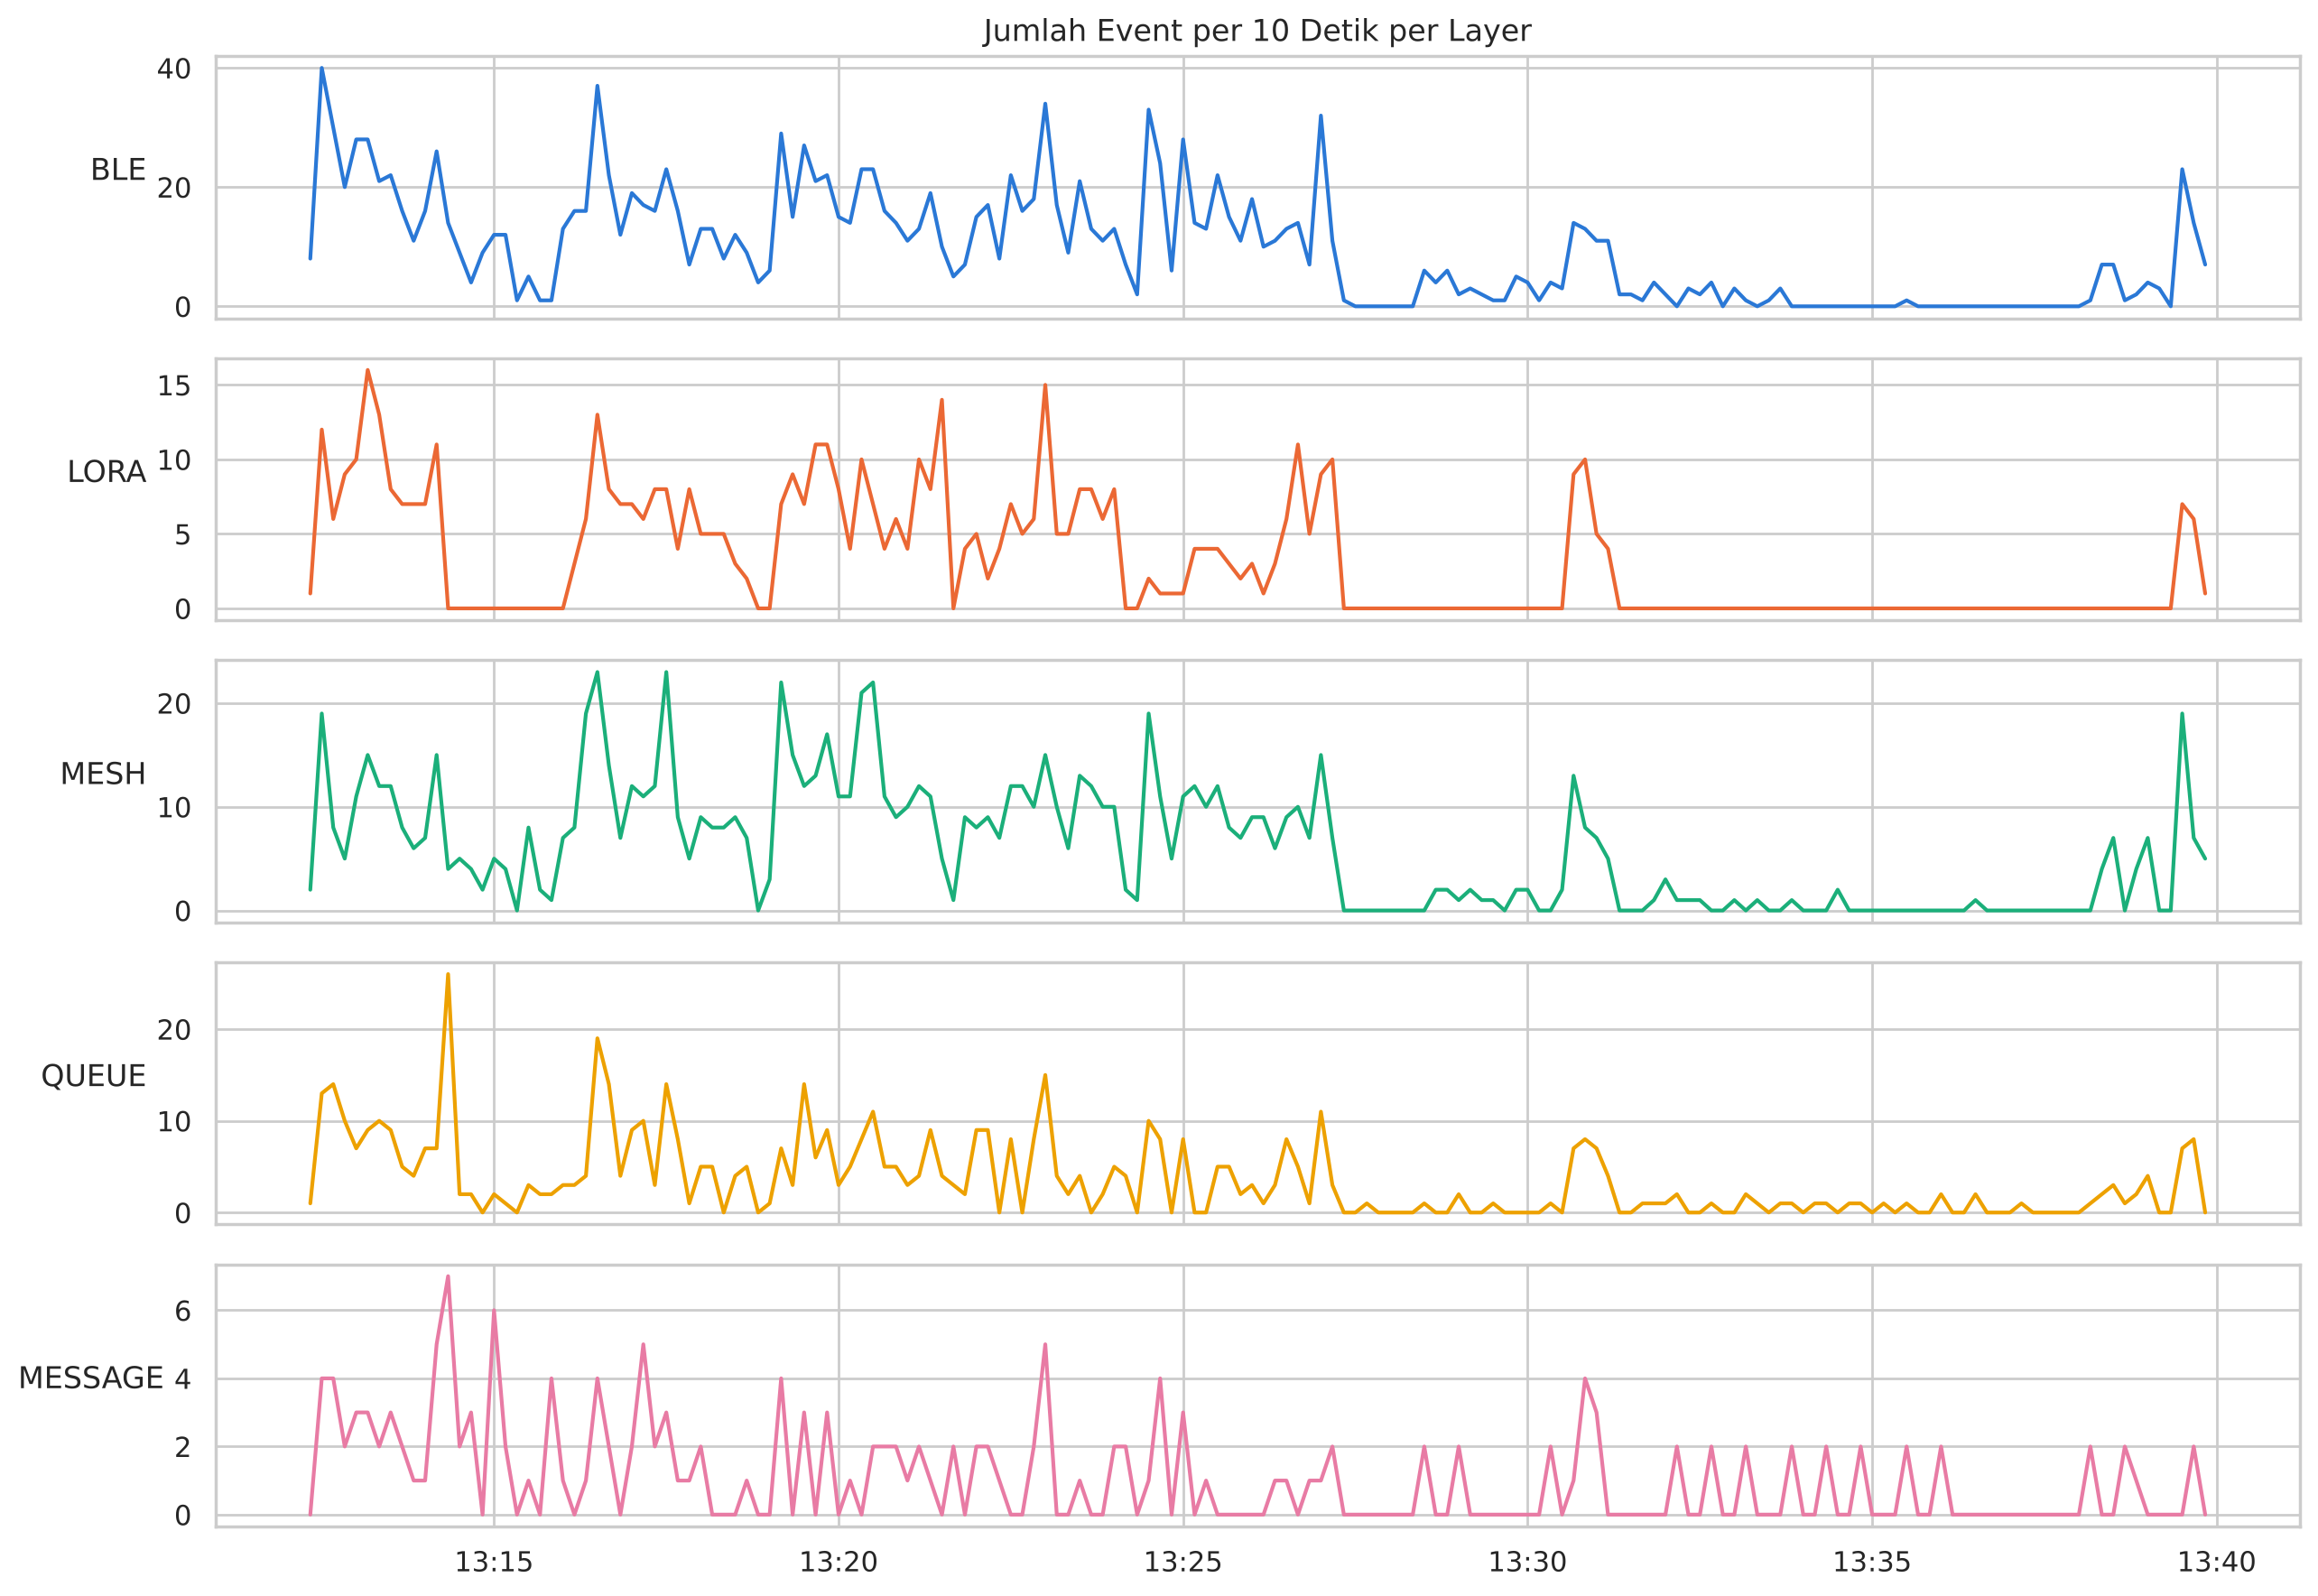

In [30]:
aktivitas = df.set_index('waktu').groupby('layer').resample('10s').size().unstack(0).fillna(0)

fig, axes = plt.subplots(5, 1, figsize=(13, 9), sharex=True)
for ax, layer, warna in zip(axes, ['BLE', 'LORA', 'MESH', 'QUEUE', 'MESSAGE'],
                            ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4']):
    ax.plot(aktivitas.index, aktivitas[layer], color=warna)
    ax.set_ylabel(layer, rotation=0, ha='right')
axes[0].set_title('Jumlah Event per 10 Detik per Layer')
axes[-1].xaxis.set_major_formatter(FORMAT_JAM)
plt.tight_layout()
plt.show()

**Interpretasi:**
- Radio LoRa sudah aktif sejak awal log: frame LoRa pertama diterima pukul **13:12:30**.
- Pukul **13:14–13:16** grafik LORA datar di nol. Pada saat itu koneksi BLE ke NUSN-3 bermasalah dan layanan mesh beberapa kali dimatikan/dinyalakan ulang (`MESH_STOPPED`/`MESH_STARTED`), jadi HP tidak menerima laporan dari node.
- Pukul **13:16–13:27** kelima layer ramai bersamaan. Ini wajar karena satu pesan melewati semua layer (MESSAGE → QUEUE → BLE → LORA → MESH).
- Setelah **13:27** aktivitas hampir berhenti, kecuali lonjakan singkat pukul 13:30–13:31 dan 13:38–13:39. Di periode ini HP berkali-kali gagal terhubung ke NUSN-1 (dibahas di 7.6).

## 7.2 Kapan Masalah Terjadi
**Tujuan:** melihat sebaran WARN (peringatan) dan ERROR (gagal) sepanjang sesi.

**Yang dilakukan cell berikut:**
- Rincian event bermasalah

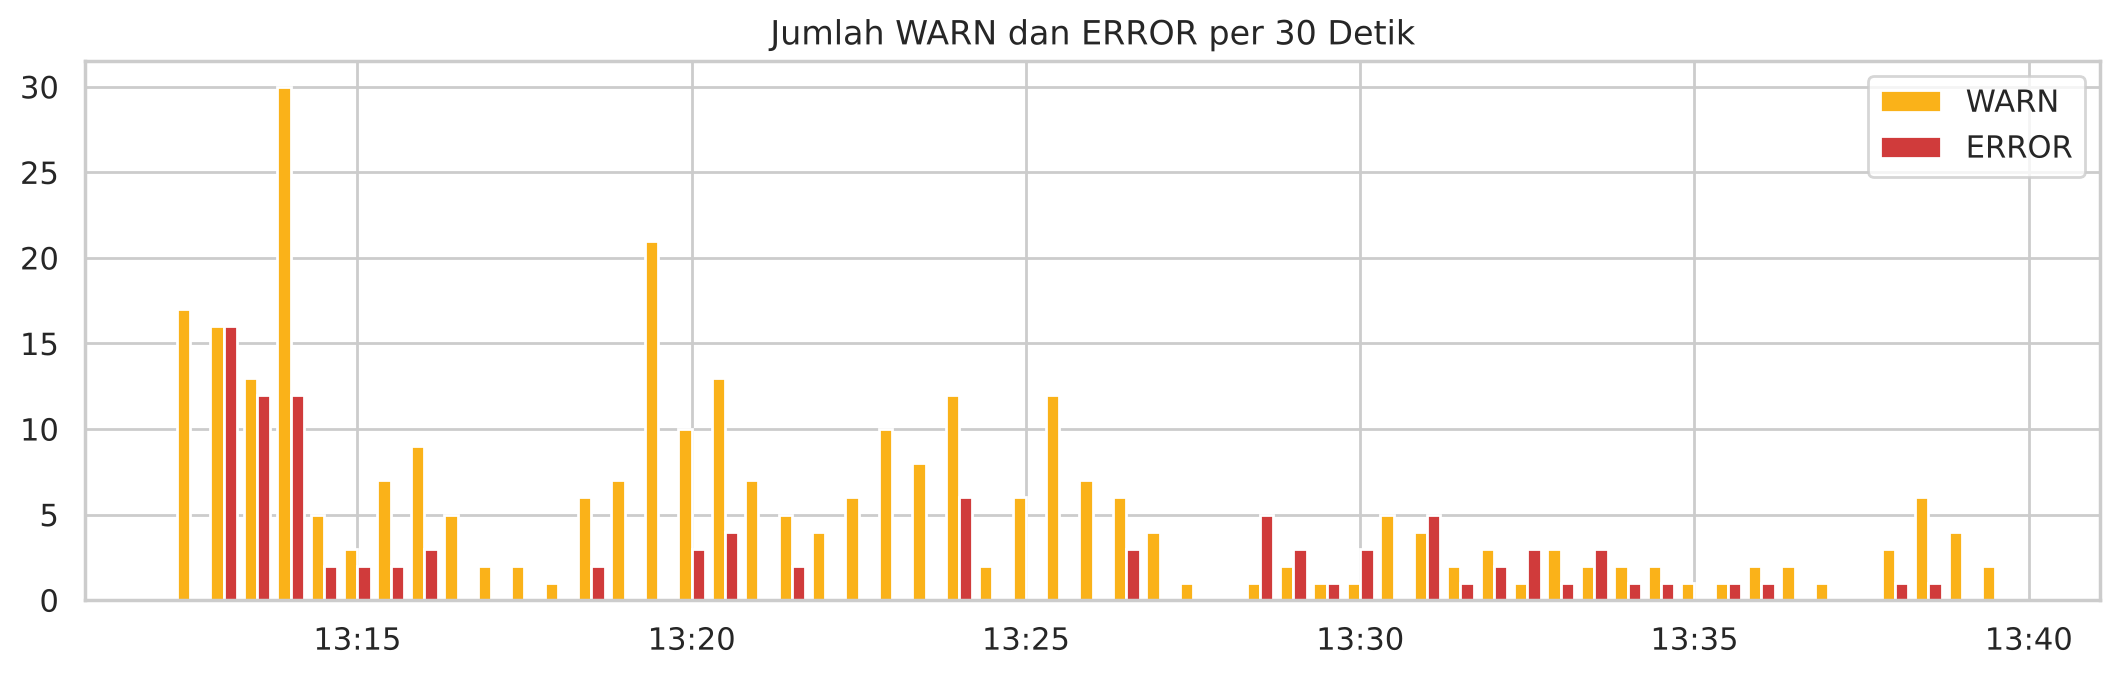

jumlah
level event                         
ERROR CONNECT_FAILED              27
      GATT_ERROR                  34
      MESSAGE_LOCAL_FAILED        22
      TX_FAILED                   19
WARN  BATCH_FAILED                38
      DISCONNECTED                17
      NODE_ADMISSION_BUSY         23
      NODE_ADMISSION_UNKNOWN      16
      NODE_RADIO_NOT_READY         1
      NODE_RX_CRC_ERROR            8
      NODE_TX_DROPPED             77
      NO_PATH                    127
      RX_META_EXPIRED              1

In [31]:
masalah = df[df['level'].isin(['WARN', 'ERROR'])].set_index('waktu').groupby('level').resample('30s').size().unstack(0).fillna(0)

fig, ax = plt.subplots(figsize=(13, 3.5))
lebar = pd.Timedelta(seconds=12)
ax.bar(masalah.index - lebar / 2, masalah['WARN'], width=lebar, color='#fab219', label='WARN')
ax.bar(masalah.index + lebar / 2, masalah['ERROR'], width=lebar, color='#d03b3b', label='ERROR')
ax.set_title('Jumlah WARN dan ERROR per 30 Detik')
ax.xaxis.set_major_formatter(FORMAT_JAM)
ax.legend()
plt.show()

df[df['level'] != 'INFO'].groupby(['level', 'event']).size().to_frame('jumlah')

**Interpretasi:**
- **ERROR paling banyak terjadi pukul 13:13–13:14** (42 ERROR dalam 2 menit). Hampir semuanya `GATT_ERROR` dan `TX_FAILED` pada koneksi BLE ke **NUSN-3**.
- Pukul **13:16–13:27** ERROR jarang dan tersebar, tetapi WARN tetap muncul, terutama `NO_PATH` dan `NODE_TX_DROPPED` (frame dibuang karena antrean node penuh).
- Pukul **13:28–13:36** muncul ERROR kecil tetapi terus-menerus, yaitu `CONNECT_FAILED` ke **NUSN-1** dan pesan yang gagal masuk ke node.
- WARN terbanyak adalah `NO_PATH` (**127 kali**), disusul `NODE_TX_DROPPED` (**77 kali**). ERROR terbanyak adalah `GATT_ERROR` (**34 kali**), lalu `CONNECT_FAILED` (27) dan `MESSAGE_LOCAL_FAILED` (22 pesan gagal masuk ke node).

## 7.3 Kualitas Sinyal LoRa
**Tujuan:** menilai apakah sinyal antar node cukup kuat dan bersih, dibandingkan dengan batas kemampuan LoRa SF7 (`SENSITIVITAS_SF7` dan `SNR_MIN_SF7`).

- **Margin RSSI** = RSSI − (−124 dBm). Makin besar, makin jauh dari batas, makin aman.
- **Margin SNR** = SNR − (−7,5 dB). Jika negatif, frame itu di bawah batas kemampuan demodulasi.

In [32]:
statistik_sinyal = sinyal.groupby('node').agg(
    jumlah_frame     = ('rssi_dbm', 'size'),
    rssi_rata2       = ('rssi_dbm', 'mean'),
    rssi_terlemah    = ('rssi_dbm', 'min'),
    snr_rata2        = ('snr_db', 'mean'),
    snr_terendah     = ('snr_db', 'min'),
    margin_rssi_min  = ('margin_rssi', 'min'),
    frame_di_bawah_batas = ('margin_snr', lambda x: (x < 0).sum()),
).round(2)
statistik_sinyal

,jumlah_frame,rssi_rata2,rssi_terlemah,snr_rata2,snr_terendah,margin_rssi_min,frame_di_bawah_batas
node,,,,,,,
NUSN-1,54,-85.90,-101.0,7.22,-6.0,23.0,0
NUSN-3,94,-93.85,-130.3,6.58,-9.0,-6.3,5


**Yang dilakukan cell berikut:**
- `ax.scatter`: titik = tiap frame
- `ax.plot`: garis = tren

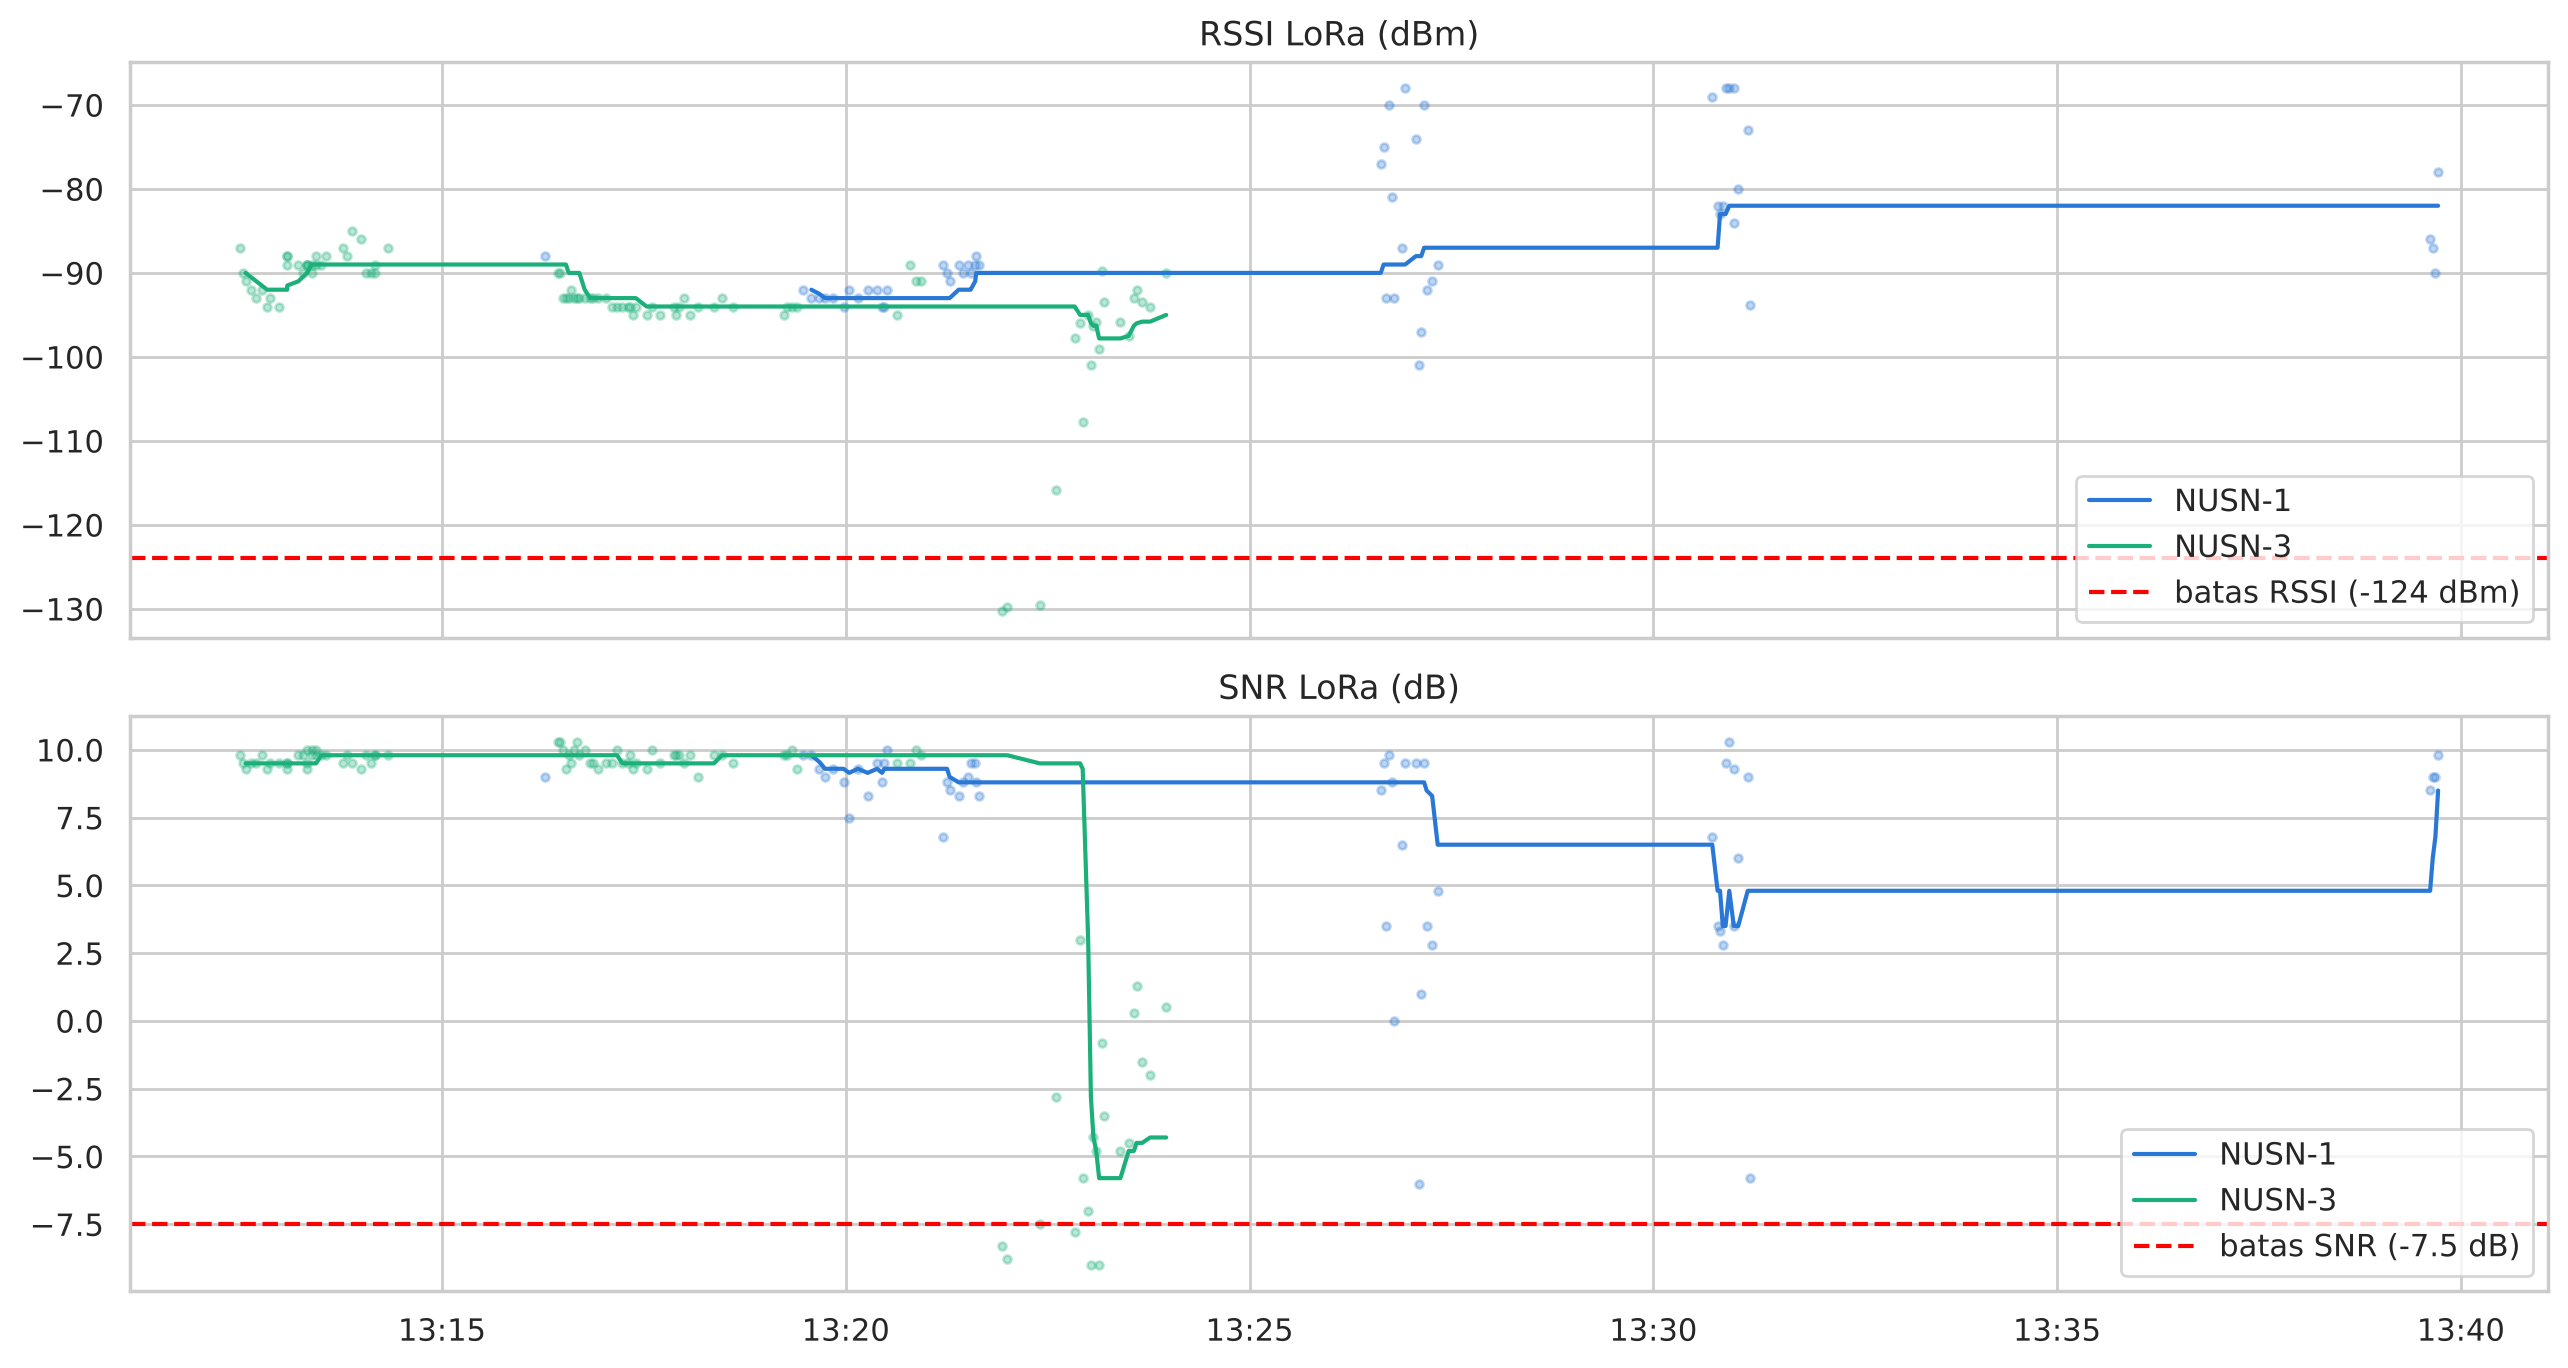

In [33]:
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
for node, data in sinyal.groupby('node'):
    data = data.sort_values('waktu')
    for ax, kolom in zip(axes, ['rssi_dbm', 'snr_db']):
        ax.scatter(data['waktu'], data[kolom], s=8, alpha=0.3, color=WARNA_NODE[node])
        ax.plot(data['waktu'], data[kolom].rolling(15, min_periods=3).median(), color=WARNA_NODE[node], label=node)

axes[0].axhline(SENSITIVITAS_SF7, color='red', linestyle='--', label=f'batas RSSI ({SENSITIVITAS_SF7:.0f} dBm)')
axes[1].axhline(SNR_MIN_SF7, color='red', linestyle='--', label=f'batas SNR ({SNR_MIN_SF7} dB)')
axes[0].set_title('RSSI LoRa (dBm)'); axes[1].set_title('SNR LoRa (dB)')
axes[0].legend(loc='lower right'); axes[1].legend(loc='lower right')
axes[1].xaxis.set_major_formatter(FORMAT_JAM)
plt.tight_layout()
plt.show()

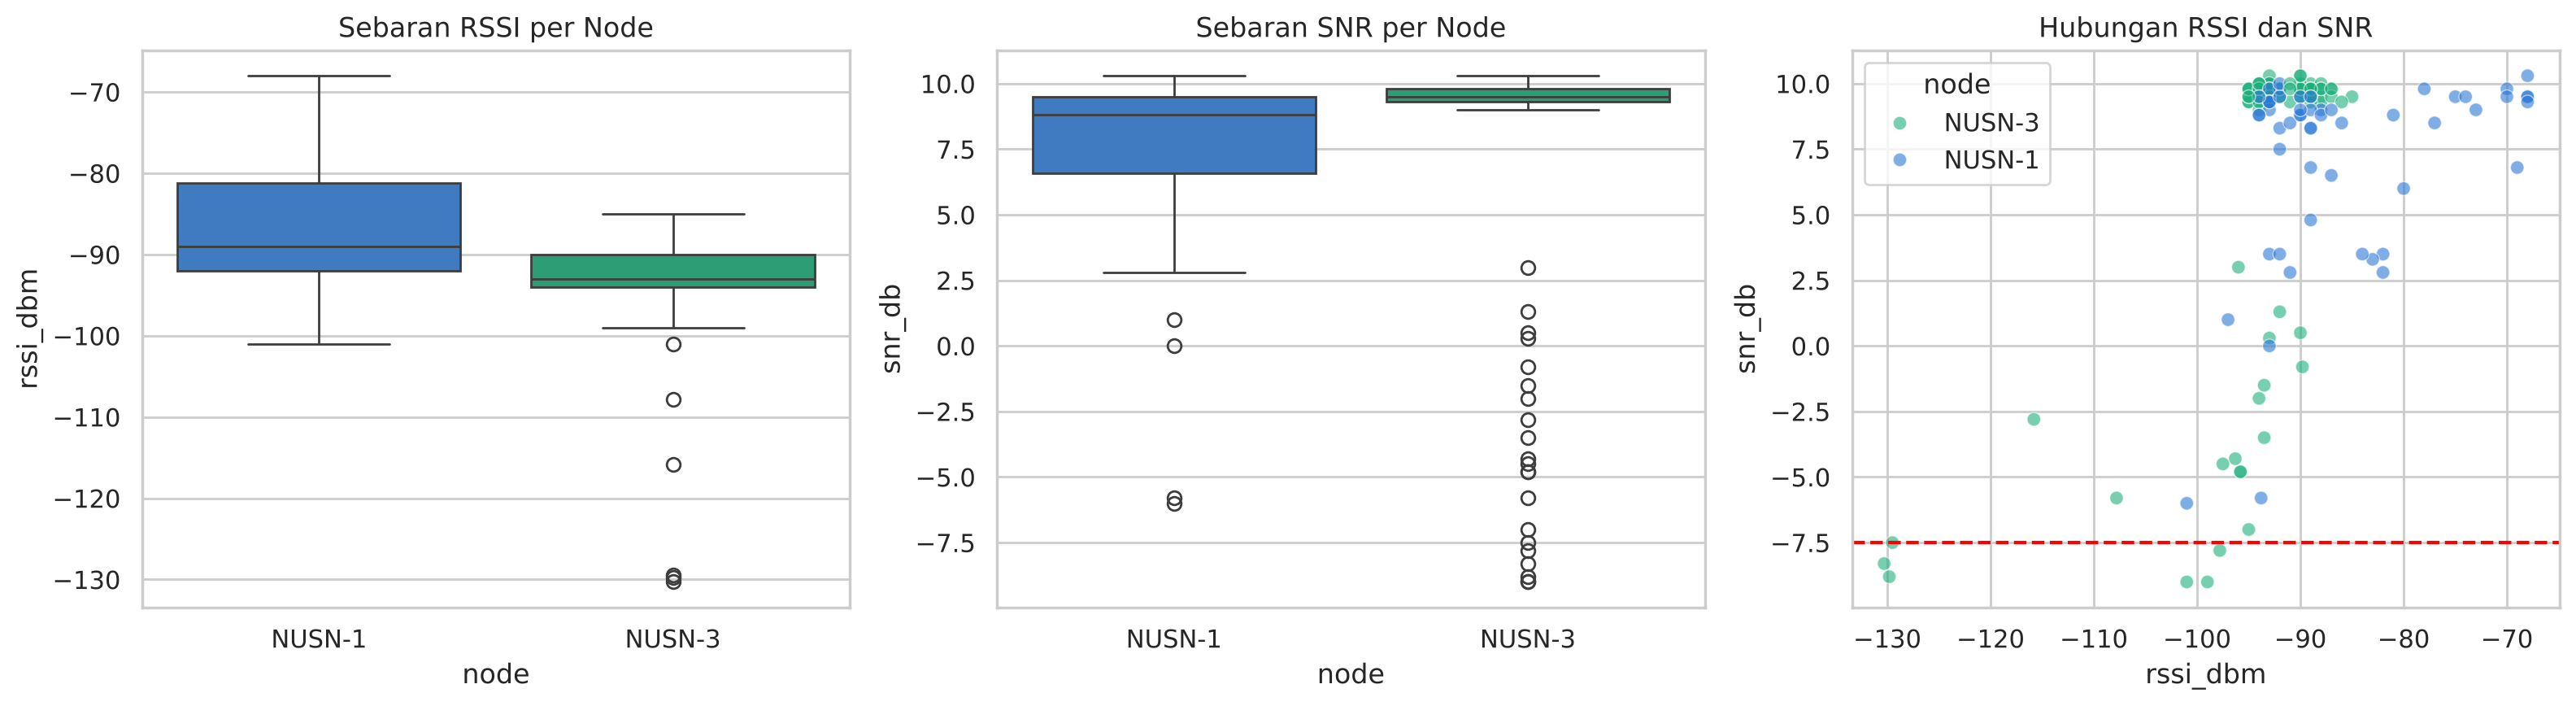

kualitas,Di bawah batas,Lemah,Cukup,Baik
node,,,,
NUSN-1,0.0,3.7,18.5,77.8
NUSN-3,5.3,12.8,4.3,77.7


In [34]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
urutan_node = sorted(sinyal['node'].unique())
sns.boxplot(data=sinyal, x='node', y='rssi_dbm', order=urutan_node, hue='node', palette=WARNA_NODE, legend=False, ax=axes[0])
axes[0].set_title('Sebaran RSSI per Node')
sns.boxplot(data=sinyal, x='node', y='snr_db', order=urutan_node, hue='node', palette=WARNA_NODE, legend=False, ax=axes[1])
axes[1].set_title('Sebaran SNR per Node')
sns.scatterplot(data=sinyal, x='rssi_dbm', y='snr_db', hue='node', palette=WARNA_NODE, alpha=0.6, ax=axes[2])
axes[2].axhline(SNR_MIN_SF7, color='red', linestyle='--')
axes[2].set_title('Hubungan RSSI dan SNR')
plt.tight_layout()
plt.show()

(pd.crosstab(sinyal['node'], sinyal['kualitas'], normalize='index') * 100).round(1)

**Interpretasi:**
- **NUSN-1 sehat.** RSSI rata-rata **−85,9 dBm** dan masih **23 dB di atas batas** pada kondisi terburuknya. SNR rata-rata 7,2 dB dan tidak ada frame di bawah batas SF7.
- **NUSN-3 sempat jatuh.** RSSI rata-rata **−93,9 dBm** dan SNR rata-rata 6,6 dB. Pada **13:21:56–13:23:08** sinyal NUSN-3 turun tajam: RSSI terendah **−130,3 dBm** (6,3 dB di bawah sensitivitas SF7) dan **5 frame** SNR-nya di bawah batas (terendah −9 dB). Setelah 13:24 NUSN-3 tidak lagi mengirim laporan.
- Di luar kejadian itu, **±78% frame kedua node berkualitas baik** (SNR ≥ 5 dB).
- Pada grafik kanan, titik naik ke kanan: makin kuat RSSI, makin bagus SNR (korelasi r ≈ 0,51). Ini wajar.
- **NUSN-2 tidak muncul** karena tidak ikut dalam sesi ini.

## 7.4 Kesehatan Node
**Tujuan:** mengecek kondisi tiap node: radio siap atau tidak, antrean penuh atau tidak, banyak frame rusak atau tidak, dan sisa jatah airtime.

In [35]:
def ringkas_node(data):
    total_tx, total_rx = data['tambah_tx'].sum(), data['tambah_rx'].sum()
    total_crc, total_drop = data['tambah_crc'].sum(), data['tambah_dropped'].sum()
    return pd.Series({
        'radio_siap_%':      round(data['radio_ready'].astype(float).mean() * 100, 1),
        'tetangga_maks':     data['neighbors'].max(),
        'frame_tx':          total_tx,
        'frame_rx':          total_rx,
        'crc_error_rate_%':  round(total_crc / (total_rx + total_crc) * 100, 2) if total_rx + total_crc > 0 else np.nan,
        'drop_rate_%':       round(total_drop / (total_tx + total_drop) * 100, 2) if total_tx + total_drop > 0 else np.nan,
        'antrean_maks':      data['queue'].max(),
        'airtime_terendah_ms': data['budget_ms'].min(),
    })

ringkasan_node = health.groupby('node').apply(ringkas_node, include_groups=False)
ringkasan_node

,radio_siap_%,tetangga_maks,frame_tx,frame_rx,crc_error_rate_%,drop_rate_%,antrean_maks,airtime_terendah_ms
node,,,,,,,,
NUSN-1,73.2,2.0,193.0,260.0,2.99,19.58,19.0,15.0
NUSN-3,100.0,2.0,194.0,176.0,3.30,27.61,23.0,20.0


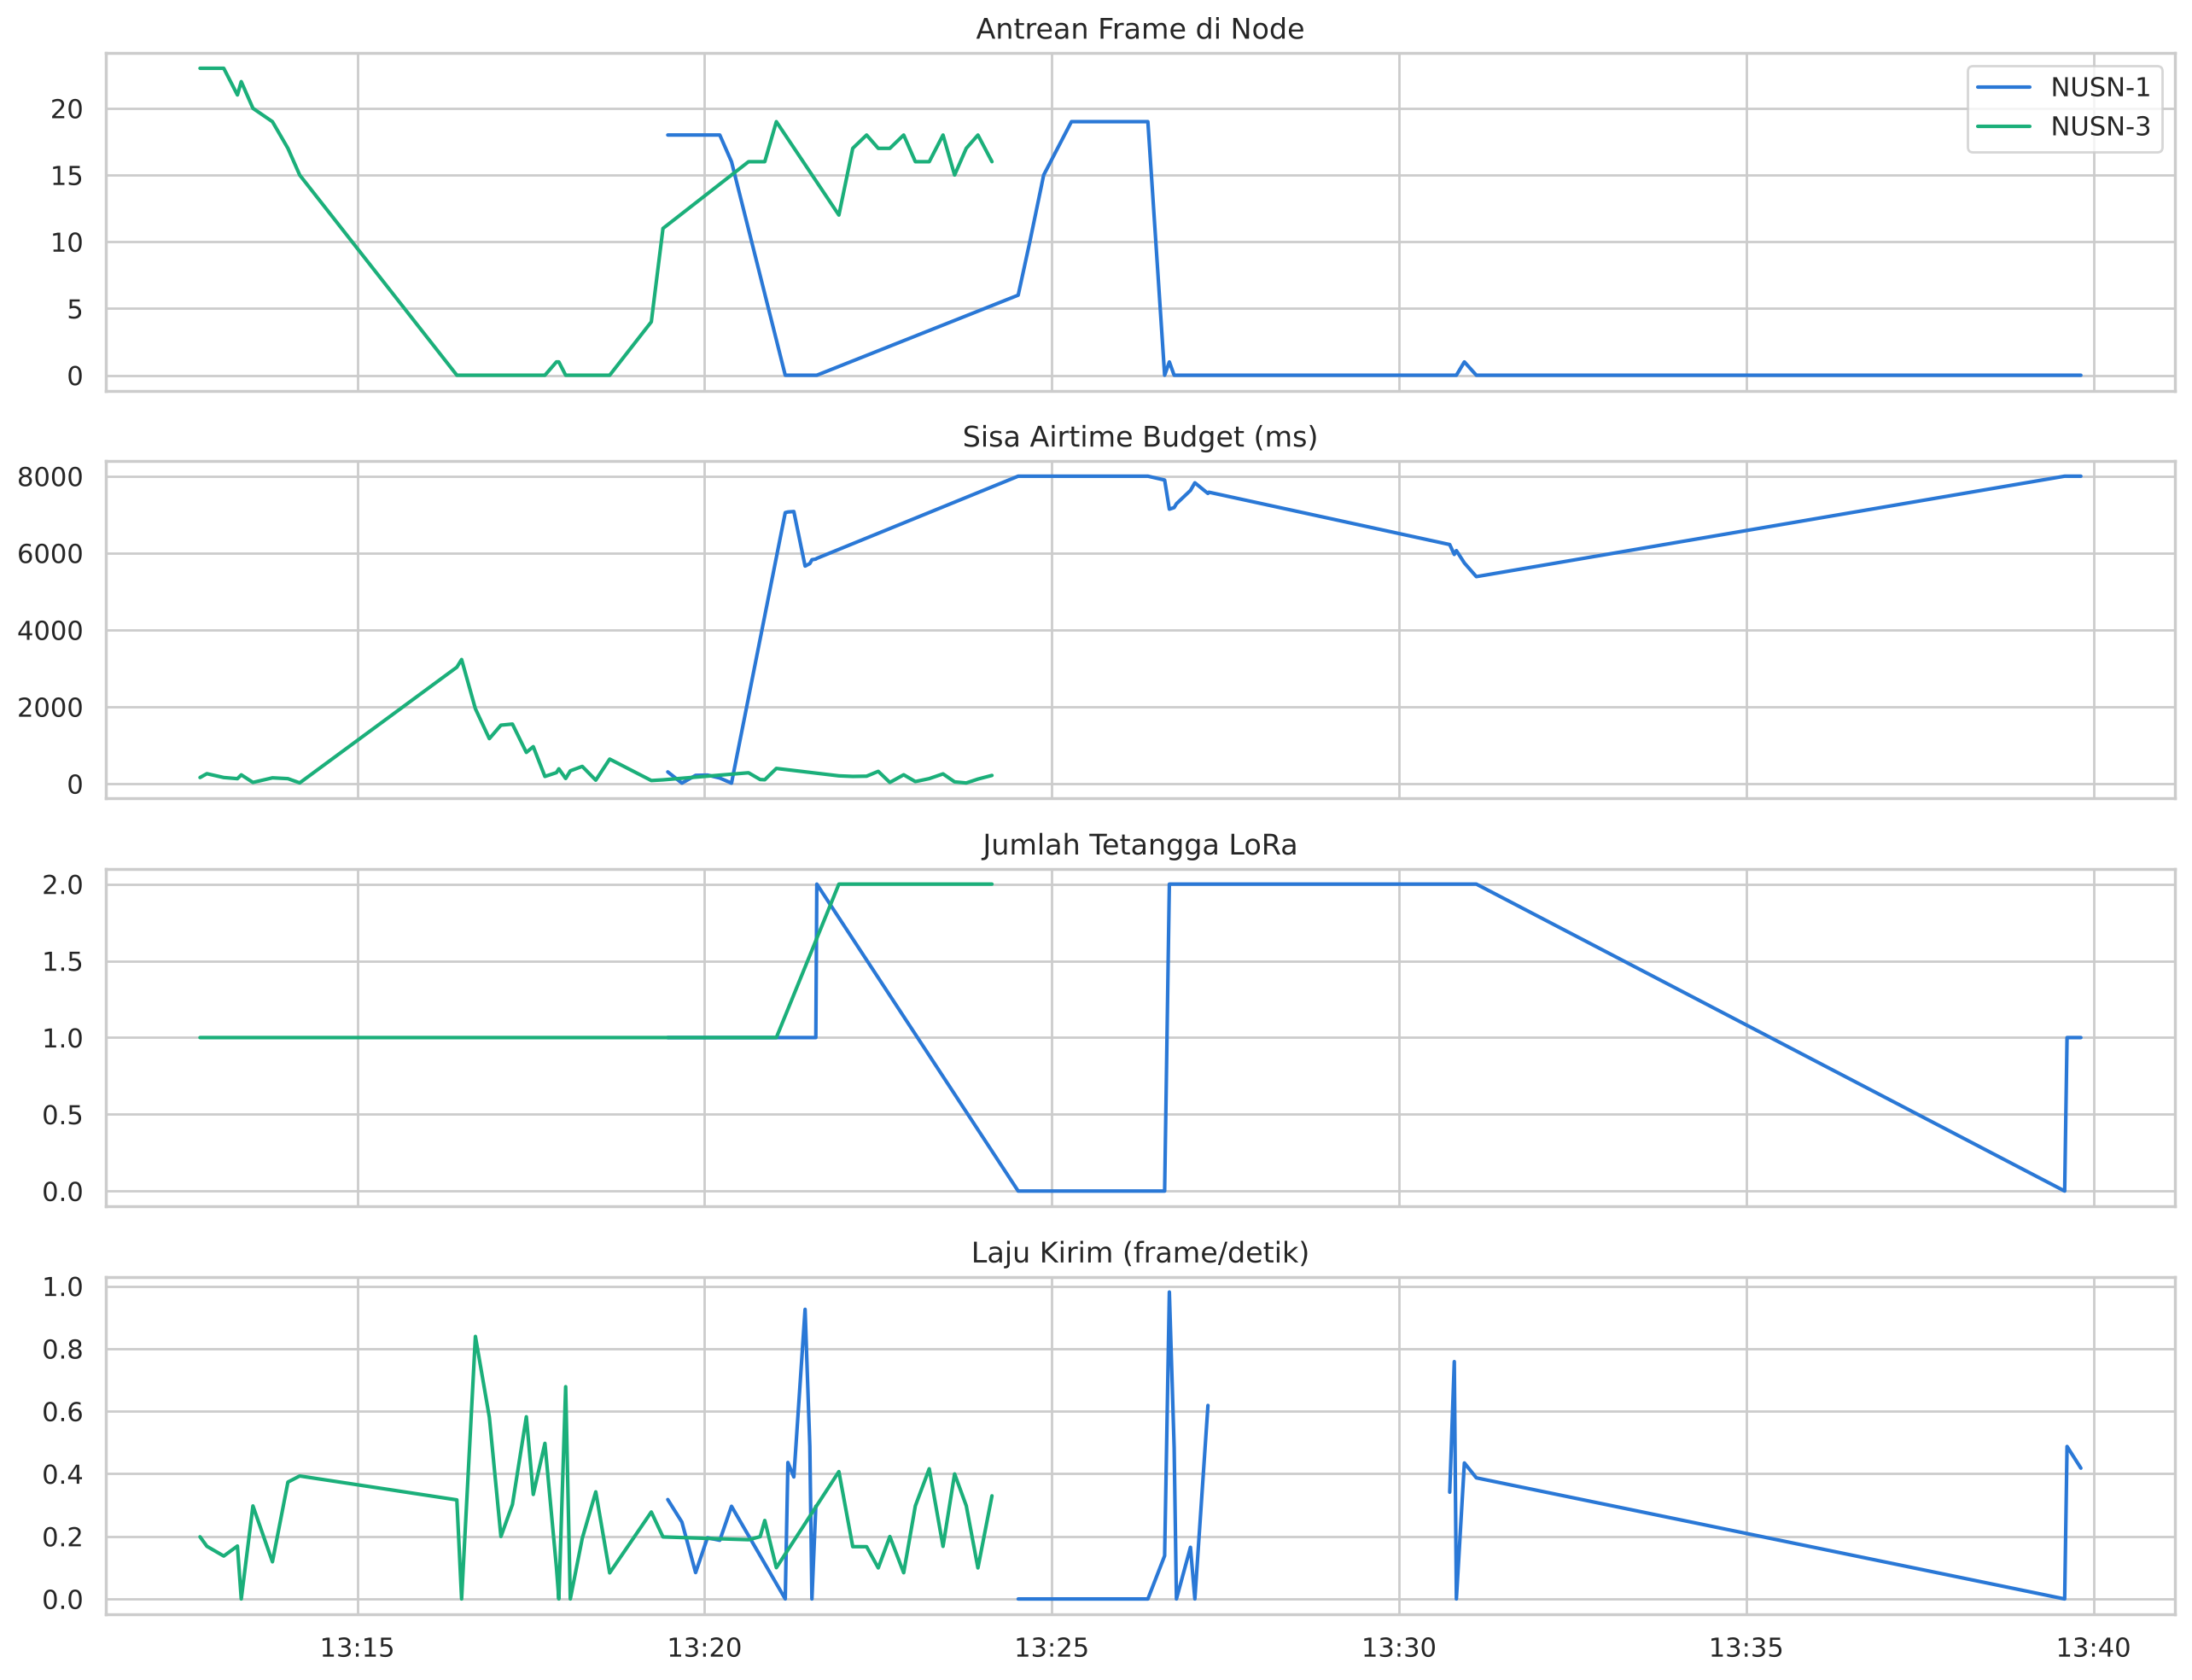

In [36]:
panel = [('queue', 'Antrean Frame di Node'), ('budget_ms', 'Sisa Airtime Budget (ms)'),
         ('neighbors', 'Jumlah Tetangga LoRa'), ('tx_per_detik', 'Laju Kirim (frame/detik)')]

fig, axes = plt.subplots(4, 1, figsize=(13, 10), sharex=True)
for ax, (kolom, judul) in zip(axes, panel):
    for node, data in health.groupby('node'):
        ax.plot(data['waktu'], data[kolom], color=WARNA_NODE[node], label=node)
    ax.set_title(judul)
axes[0].legend(loc='upper right')
axes[-1].xaxis.set_major_formatter(FORMAT_JAM)
plt.tight_layout()
plt.show()

**Interpretasi:**
- **Airtime budget menjadi masalah utama.** Sisa airtime **NUSN-3 hampir selalu di bawah 500 ms** dari jatah 8.000 ms (median ±200 ms) selama 13:12–13:24, kecuali sebentar pada 13:16–13:17. Akibatnya antrean NUSN-3 menumpuk sampai **23 frame** dan **27,6% frame dibuang** (drop rate). NUSN-1 juga mengalami hal yang sama pada 13:19–13:20 (sisa airtime 15–308 ms, antrean 18 frame).
- **Radio NUSN-1 sempat tidak siap** pada **13:24:31–13:26:23** (±2 menit, `radio_siap_% = 73,2`). Selama itu tetangganya 0 dan antrean naik sampai 19 frame. Setelah radionya siap kembali, antrean langsung kosong dan airtime pulih ke ±7.000–8.000 ms.
- **CRC error rendah:** 3,0% (NUSN-1) dan 3,3% (NUSN-3). Frame yang rusak di udara sedikit.
- Masing-masing node paling banyak mendengar **2 tetangga**.
- Laporan NUSN-3 berhenti setelah **13:24**, sedangkan NUSN-1 terus melapor sampai akhir sesi.

## 7.5 Pengiriman Pesan
**Tujuan:** mengukur seberapa sering pesan berhasil sampai ke node, berapa kali harus dikirim ulang, dan berapa lama prosesnya.

$$
\text{Tingkat keberhasilan} = \frac{\text{pesan berhasil masuk node}}{\text{pesan berhasil} + \text{pesan gagal}}
$$

Pesan keluar             : 63
Berhasil masuk node      : 34
Gagal                    : 22
Tingkat keberhasilan     : 60.7%
Pesan yang dikirim ulang : 15


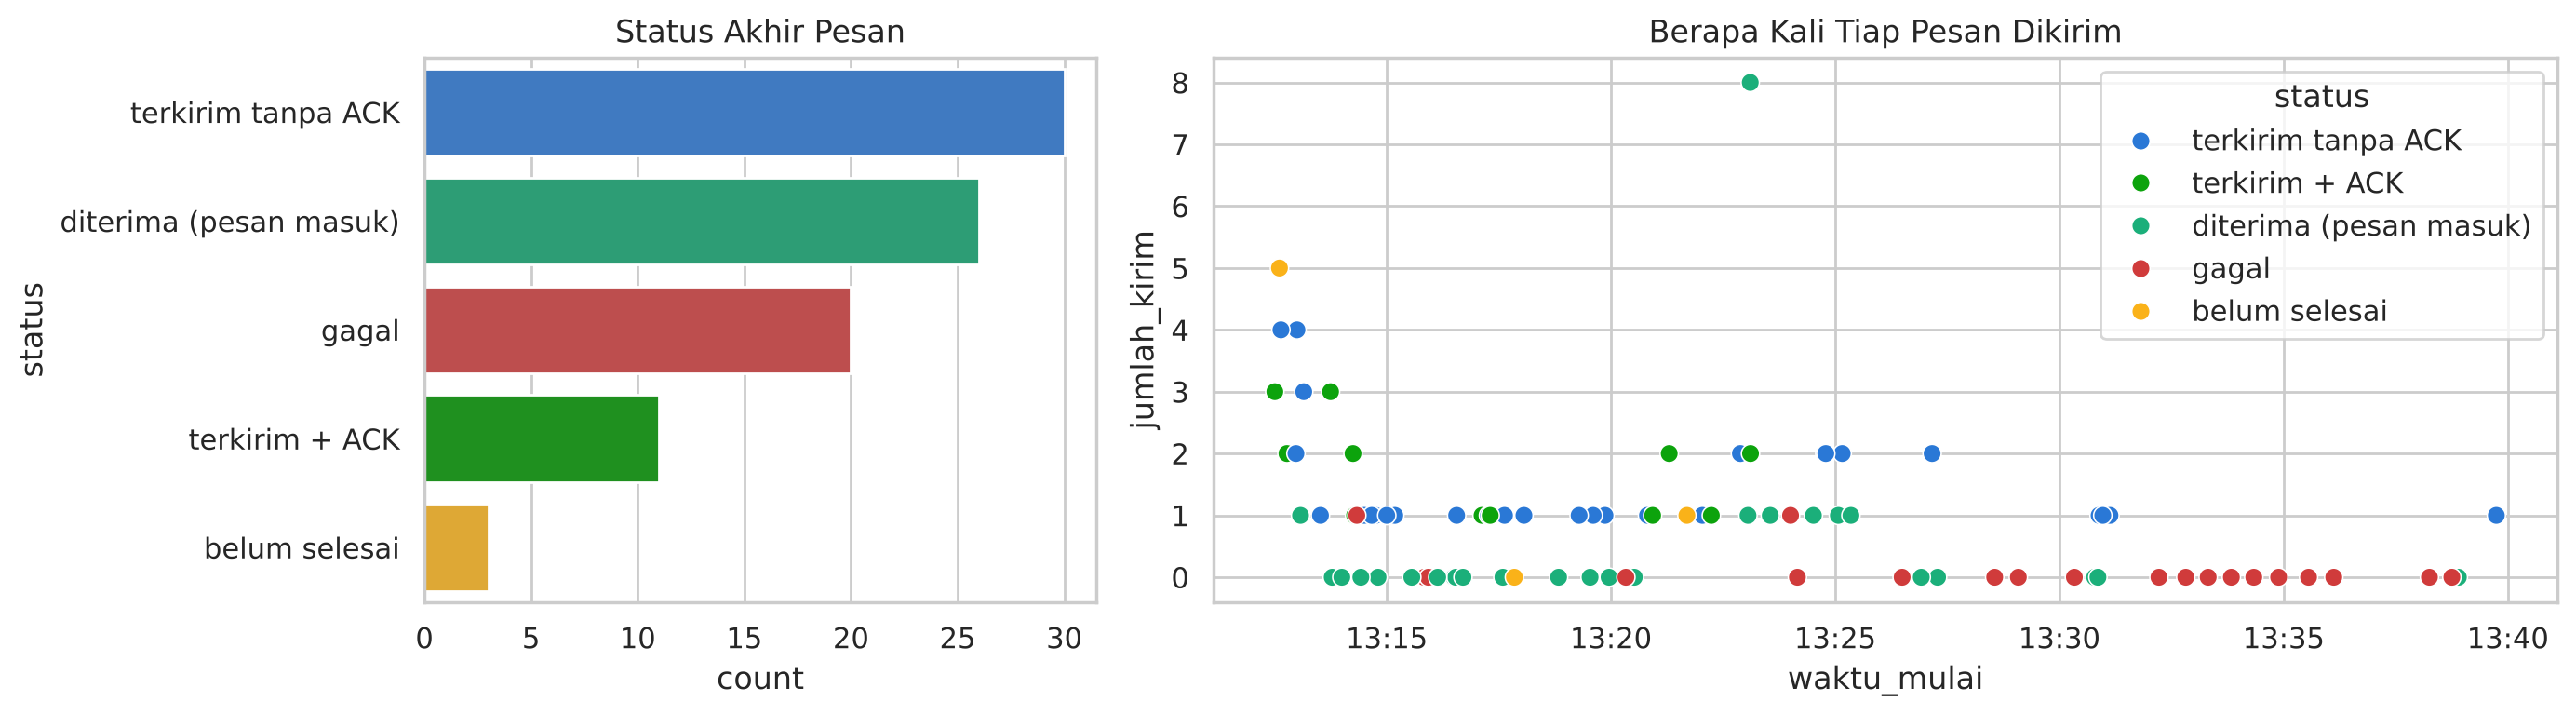

In [37]:
pesan_keluar = pesan[pesan['arah'] == 'keluar']
berhasil = (pesan_keluar['MESSAGE_LOCAL_ACCEPTED'] > 0).sum()
gagal    = (pesan_keluar['MESSAGE_LOCAL_FAILED'] > 0).sum()

print(f'Pesan keluar             : {len(pesan_keluar)}')
print(f'Berhasil masuk node      : {berhasil}')
print(f'Gagal                    : {gagal}')
print(f'Tingkat keberhasilan     : {berhasil / (berhasil + gagal) * 100:.1f}%')
print(f'Pesan yang dikirim ulang : {(pesan_keluar["jumlah_kirim"] > 1).sum()}')

fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={'width_ratios': [1, 2]})
warna_status = {'diterima (pesan masuk)': '#1baf7a', 'terkirim tanpa ACK': '#2a78d6', 'gagal': '#d03b3b',
                'terkirim + ACK': '#0ca30c', 'belum selesai': '#fab219'}
urutan = pesan['status'].value_counts().index
sns.countplot(data=pesan, y='status', order=urutan, hue='status', palette=warna_status, legend=False, ax=axes[0])
axes[0].set_title('Status Akhir Pesan')
sns.scatterplot(data=pesan, x='waktu_mulai', y='jumlah_kirim', hue='status', palette=warna_status, s=50, ax=axes[1])
axes[1].set_title('Berapa Kali Tiap Pesan Dikirim')
axes[1].xaxis.set_major_formatter(FORMAT_JAM)
plt.tight_layout()
plt.show()

**Yang dilakukan cell berikut:**
- Lama setiap tahap pengiriman (ms)

In [38]:
latency = pd.DataFrame({
    'Tulis ke node via BLE': df.loc[df['event'] == 'TX_ACCEPTED', 'duration_ms'].astype(float).describe(),
    'Menunggu di antrean':   df.loc[df['event'] == 'QUEUE_DEQUEUED', 'duration_ms'].astype(float).describe(),
    'Sampai ACK kembali':    pesan_keluar['latency_ack_ms'].astype(float).describe(),
}).T.round(1)
latency

,count,mean,std,min,25%,50%,75%,max
Tulis ke node via BLE,169.0,227.2,458.1,2.0,6.0,83.0,210.0,2485.0
Menunggu di antrean,111.0,40065.7,152556.5,0.0,2.0,1375.0,10958.0,767711.0
Sampai ACK kembali,11.0,33241.7,88919.4,929.0,2835.5,3462.0,9044.0,300523.0


**Interpretasi:**
- **60,7% pesan keluar berhasil masuk ke node** (34 dari 56 pesan yang punya hasil akhir; 7 pesan lainnya belum punya catatan berhasil/gagal di node). Dari tabel status: **20 pesan gagal**, dan **13 di antaranya terjadi setelah 13:28**, saat HP tidak bisa terhubung ke NUSN-1. Pesan-pesan itu bahkan tidak sempat ditulis ke node (`jumlah_kirim = 0`).
- **15 pesan dikirim ulang**, paling banyak 4 kali.
- Sebagian besar pesan berstatus **terkirim tanpa ACK** (30 pesan). Ini belum tentu gagal, karena tidak semua jenis pesan meminta konfirmasi balik. Untuk tahu apakah pesan benar-benar sampai, perlu dicocokkan dengan log di HP penerima.
- **Tulis BLE** median sekitar **83 ms**, tetapi bisa sampai 2,5 detik.
- **ACK kembali** dengan median **3,5 detik** (n = 11). Rata-ratanya 33 detik karena satu ACK baru datang setelah **±5 menit** (pesan 13:14:14, ACK 13:19:15).
- **Waktu antre sangat timpang:** median 1,4 detik, tetapi maksimum **767.711 ms (±12,8 menit)**. Nilai ekstrem ini berasal dari frame tanpa `message_id` yang di-*dequeue* pada 13:12–13:14. Frame itu sudah mengantre sejak sebelum log ini dimulai (±13:01).

## 7.6 Koneksi BLE (HP ↔ Node)
**Tujuan:** mengecek stabilitas koneksi Bluetooth antara HP dan node, dan perangkat mana yang bermasalah.

**Yang dilakukan cell berikut:**
- Jumlah error BLE per perangkat

In [39]:
error_ble = df[df['event'].isin(['CONNECT_FAILED', 'GATT_ERROR', 'TX_FAILED', 'DISCONNECTED'])]
pd.crosstab(error_ble['device_id'], error_ble['event'])

event,CONNECT_FAILED,DISCONNECTED,GATT_ERROR,TX_FAILED
device_id,,,,
14:2B:2F:93:76:92,6,7,25,15
41:DC:35:23:21:2E,0,2,0,0
55:07:37:C1:3B:5B,0,1,0,0
5F:64:2C:DC:E3:AA,0,1,0,0
64:B7:08:AD:2E:DA,21,6,9,4


**Yang dilakukan cell berikut:**
- Pasangan MAC BLE -> node, ditebak dari beacon (type 24): MAC BLE yang meneruskan beacon dengan sender NUSN-n adalah node NUSN-n

In [40]:
beacon = df[(df['event'] == 'RX_PACKET') & (df['type'] == 24)]
mac_ke_node = beacon.groupby('device_id')['sender'].agg(lambda x: nama_node(x.mode()[0]))
mac_ke_node

device_id
14:2B:2F:93:76:92    NUSN-3
64:B7:08:AD:2E:DA    NUSN-1
Name: sender, dtype: str

**Yang dilakukan cell berikut:**
- Kekuatan sinyal BLE dari HP ke tiap node

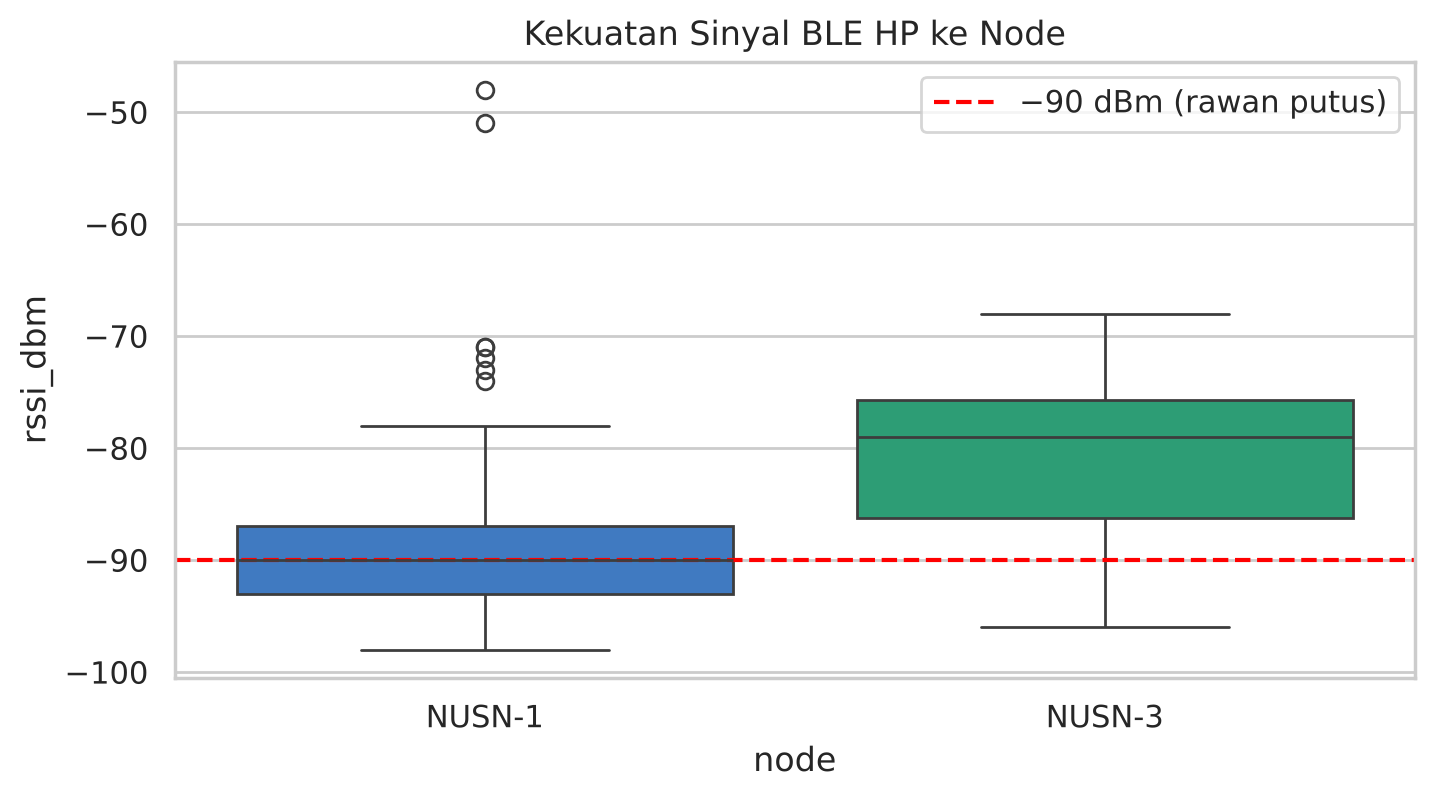

node
NUSN-1   -90.0
NUSN-3   -79.0
Name: rssi_dbm, dtype: float64

In [41]:
scan = df[(df['event'] == 'RSSI_SCAN') & df['device_id'].isin(mac_ke_node.index)].copy()
scan['node'] = scan['device_id'].map(mac_ke_node)

plt.figure(figsize=(8, 4))
sns.boxplot(data=scan, x='node', y='rssi_dbm', hue='node', palette=WARNA_NODE, legend=False,
            order=sorted(scan['node'].unique()))
plt.axhline(-90, color='red', linestyle='--', label='−90 dBm (rawan putus)')
plt.title('Kekuatan Sinyal BLE HP ke Node')
plt.legend()
plt.show()

scan.groupby('node')['rssi_dbm'].median()

**Interpretasi:**
- **Error BLE terbagi ke dua node.** Koneksi ke **NUSN-3** (`14:2B:2F:93:76:92`) mencatat **53 error** (25 GATT error, 15 gagal kirim, 7 putus, 6 gagal connect), hampir semuanya pada **13:13–13:15**. Koneksi ke **NUSN-1** (`64:B7:08:AD:2E:DA`) mencatat **40 error**, didominasi **21 gagal connect**, terutama pada **13:28–13:33**.
- **Sinyal BLE ke NUSN-1 lemah:** median **−90 dBm**, tepat di garis rawan putus. Ini cocok dengan banyaknya gagal connect ke NUSN-1. Sinyal baru naik ke ±−58 dBm pada 13:39, kemungkinan karena HP didekatkan ke node.
- **Sinyal BLE ke NUSN-3 lebih kuat** (median **−79 dBm**), tetapi error tetap banyak di awal sesi. Kemungkinan penyebabnya adalah NUSN-3 yang sedang sibuk (airtime habis, antrean penuh, lihat 7.4), sehingga penulisan BLE timeout.
- Secara keseluruhan tulis BLE **89,9% berhasil** (169 dari 188).

## 7.7 Jaringan Mesh dan Handover
**Tujuan:** mengecek apakah node meneruskan paket dengan baik, apakah banyak paket ganda, dan berapa lama HP pindah antar node.

Paket mesh diterima          : 596  (beacon 371, data 225)
Paket diteruskan (relay)     : 147  -> 65.3% dari paket data
Paket duplikat               : 83  -> 13.93% dari semua paket


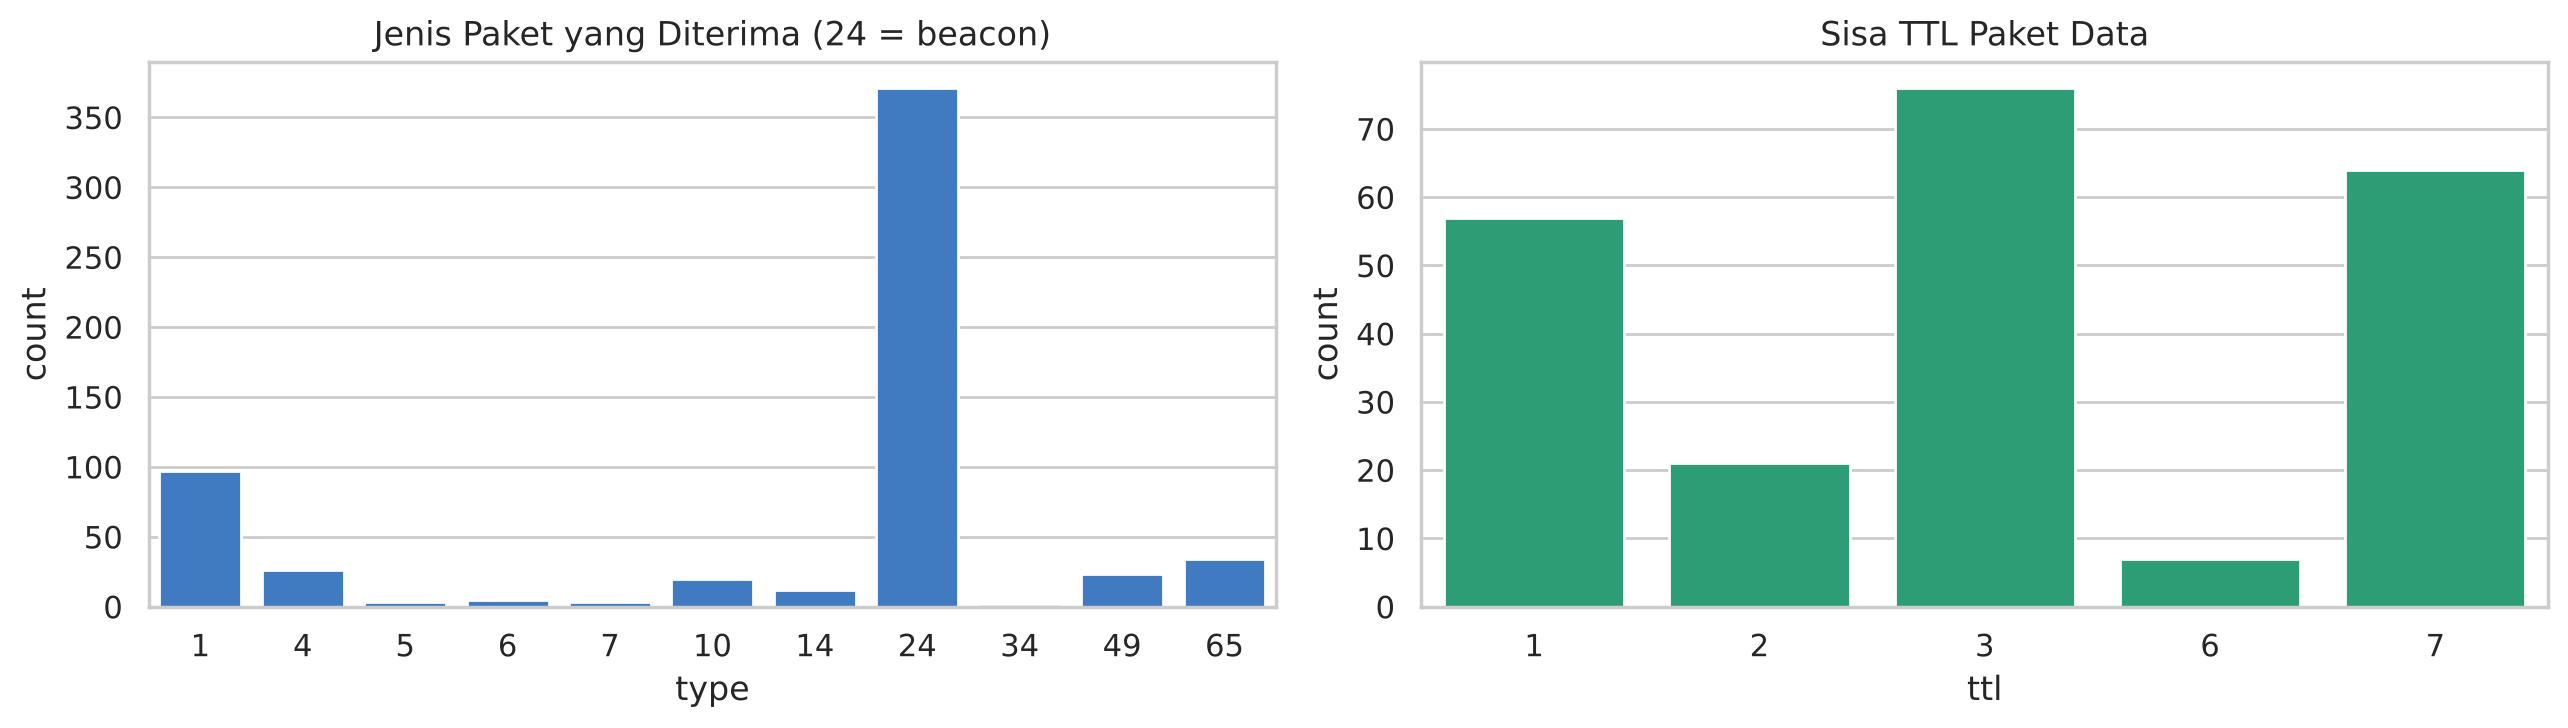

In [42]:
paket_masuk = df[df['event'] == 'RX_PACKET']
paket_non_beacon = paket_masuk[paket_masuk['type'] != 24]

print(f'Paket mesh diterima          : {len(paket_masuk)}  (beacon {(paket_masuk["type"] == 24).sum()}, data {len(paket_non_beacon)})')
print(f'Paket diteruskan (relay)     : {(df["event"] == "RELAYED").sum()}  -> {(df["event"] == "RELAYED").sum() / len(paket_non_beacon) * 100:.1f}% dari paket data')
print(f'Paket duplikat               : {(df["event"] == "RX_DUPLICATE").sum()}  -> {(df["event"] == "RX_DUPLICATE").sum() / len(paket_masuk) * 100:.2f}% dari semua paket')

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
sns.countplot(x=paket_masuk['type'].astype(int), color='#2a78d6', ax=axes[0])
axes[0].set_title('Jenis Paket yang Diterima (24 = beacon)')
sns.countplot(x=paket_non_beacon['ttl'].astype(int), color='#1baf7a', ax=axes[1])
axes[1].set_title('Sisa TTL Paket Data')
plt.tight_layout()
plt.show()

**Yang dilakukan cell berikut:**
- `Handover:` HP pindah dari satu node ke node lain

In [43]:
handover = df.loc[df['event'] == 'MOBILITY_SUCCESS', ['waktu', 'from', 'to', 'duration_ms']].copy()
handover['dari'] = handover['from'].apply(nama_node).fillna('(belum terhubung)')
handover['ke']   = handover['to'].apply(nama_node)
handover['lama_detik'] = handover['duration_ms'] / 1000
handover[['waktu', 'dari', 'ke', 'lama_detik']]

,waktu,dari,ke,lama_detik
862,2026-11-12 13:16:23.135000+07:00,(belum terhubung),NUSN-3,1.174
877,2026-11-12 13:16:24.910000+07:00,NUSN-1,NUSN-3,0.78
1517,2026-11-12 13:19:12.373000+07:00,(belum terhubung),NUSN-3,1.526
1606,2026-11-12 13:19:27.802000+07:00,NUSN-3,NUSN-1,3.431
1976,2026-11-12 13:20:38.040000+07:00,NUSN-1,NUSN-3,2.403
1991,2026-11-12 13:20:40.026000+07:00,NUSN-1,NUSN-3,1.013
2094,2026-11-12 13:21:10.435000+07:00,NUSN-3,NUSN-1,5.914
3480,2026-11-12 13:30:43.879000+07:00,(belum terhubung),NUSN-1,4.924


**Interpretasi:**
- Sekitar **62% paket yang diterima adalah beacon** (371 dari 596), yaitu paket otomatis yang dipancarkan setiap node ±2 detik sekali. Sisanya, **38% (225 paket)**, membawa data pengguna atau kontrol pesan.
- **65% paket data diteruskan** (147 relay). **Paket duplikat cukup tinggi, 13,9%** (83 paket). Penyaringnya bekerja (lihat 9.3), tetapi paket ganda ini ikut memakan airtime.
- TTL paling sering 3 dan 7, sesuai nilai awal dua jenis pesan yang berbeda.
- **Handover terjadi 8 kali**, dengan lama **0,8–5,9 detik**. Pada 13:16–13:21 HP **bolak-balik antara NUSN-1 dan NUSN-3** (6 kali dalam 5 menit, *ping-pong*). Ini tanda kedua node sama-sama tidak stabil dari sisi HP.

## 7.8 Apa Penyebab Masalah: Sinyal atau Beban?
**Tujuan:** menguji apakah error muncul karena **sinyal lemah** atau karena **trafik padat**.

Window 10 detik dibagi dua kelompok: **normal** (tidak ada masalah) dan **bermasalah**. Keduanya dibandingkan dengan **uji Mann-Whitney U**:
- **p-value < 0,05** → kedua kelompok **berbeda signifikan**.
- **p-value ≥ 0,05** → **tidak ada bukti** perbedaan.

Uji ini dipakai (bukan t-test) karena datanya tidak berdistribusi normal.

In [44]:
fitur['kondisi'] = np.where(fitur['n_masalah'] > 0, 'Bermasalah', 'Normal')

uji = []
for kolom, nama in [('snr_lora_mean', 'SNR LoRa (dB)'), ('rssi_lora_mean', 'RSSI LoRa (dBm)'), ('n_TX_START', 'Beban kirim (TX_START)')]:
    normal     = fitur.loc[fitur['kondisi'] == 'Normal', kolom]
    bermasalah = fitur.loc[fitur['kondisi'] == 'Bermasalah', kolom]
    p_value = mannwhitneyu(normal, bermasalah).pvalue
    uji.append({'fitur': nama, 'median normal': normal.median(), 'median bermasalah': bermasalah.median(),
                'p-value': round(p_value, 4), 'beda signifikan?': 'YA' if p_value < 0.05 else 'tidak'})

hasil_uji = pd.DataFrame(uji)
hasil_uji

,fitur,median normal,median bermasalah,p-value,beda signifikan?
0,SNR LoRa (dB),6.683333,8.8125,0.3261,tidak
1,RSSI LoRa (dBm),-83.400000,-89.0000,0.0094,YA
2,Beban kirim (TX_START),0.000000,1.0000,0.0131,YA


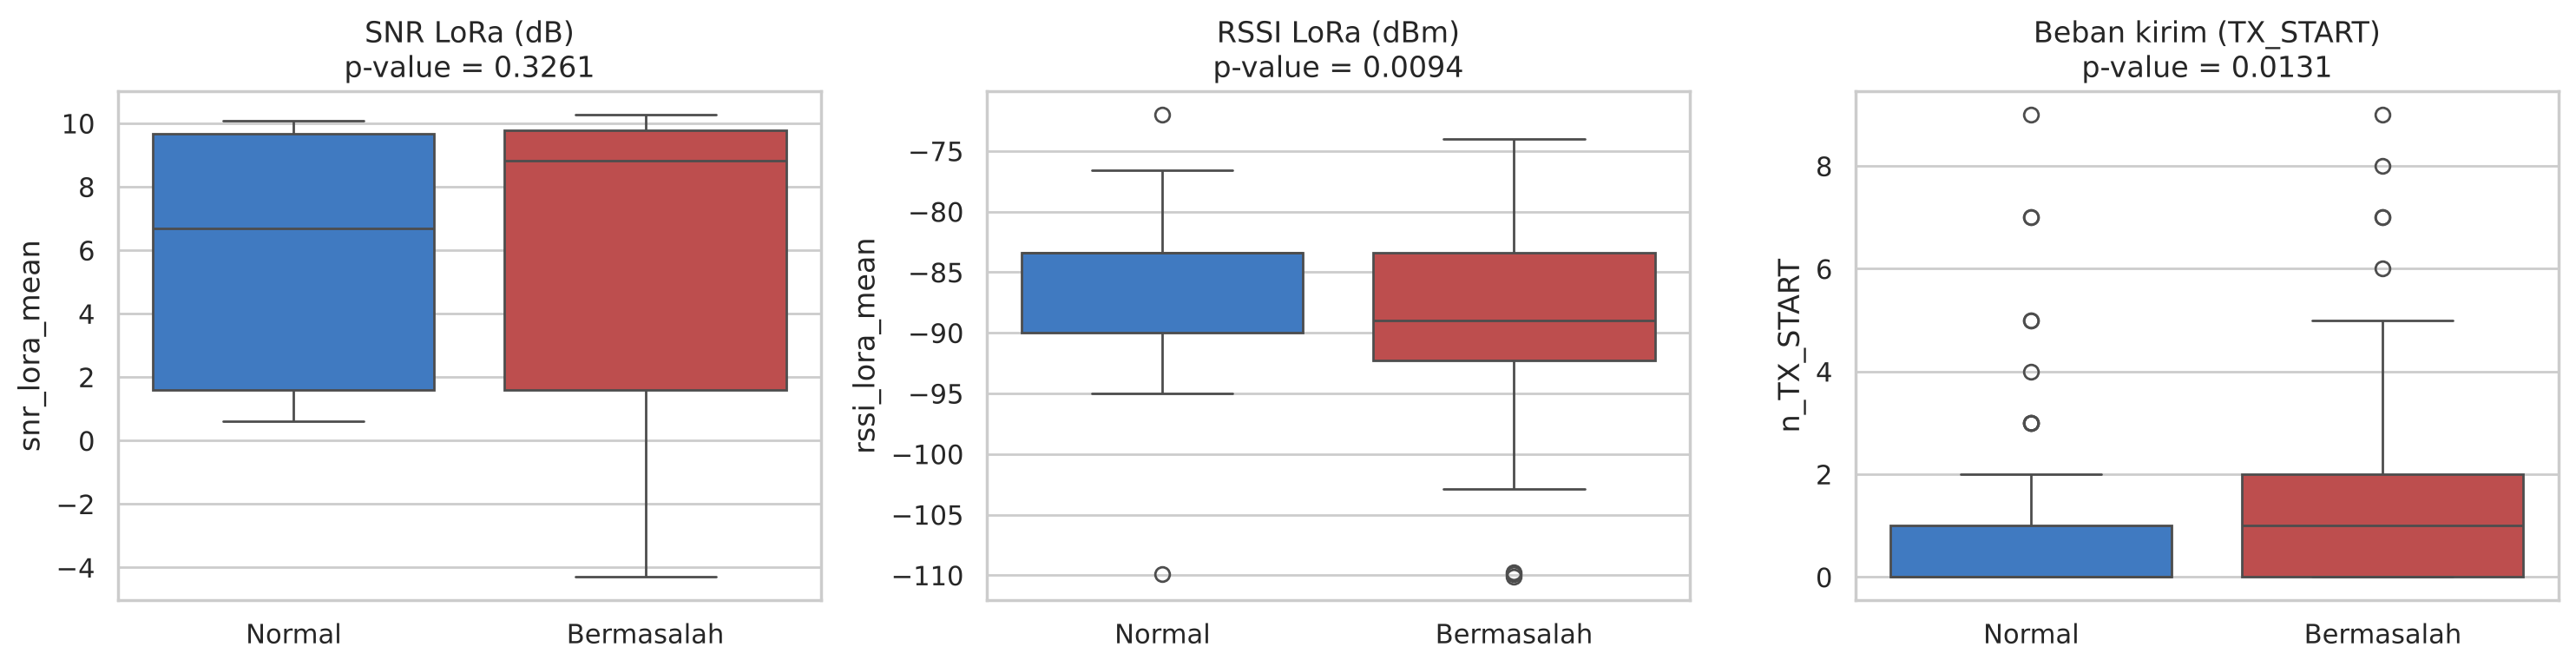

In [45]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (kolom, nama) in zip(axes, [('snr_lora_mean', 'SNR LoRa (dB)'), ('rssi_lora_mean', 'RSSI LoRa (dBm)'), ('n_TX_START', 'Beban kirim (TX_START)')]):
    sns.boxplot(data=fitur, x='kondisi', y=kolom, order=['Normal', 'Bermasalah'], hue='kondisi',
                palette={'Normal': '#2a78d6', 'Bermasalah': '#d03b3b'}, legend=False, ax=ax)
    p = hasil_uji.loc[hasil_uji['fitur'] == nama, 'p-value'].iloc[0]
    ax.set_title(f'{nama}\np-value = {p}')
    ax.set_xlabel('')
plt.tight_layout()
plt.show()

**Yang dilakukan cell berikut:**
- Korelasi Spearman antara fitur dan jumlah masalah di window yang sama

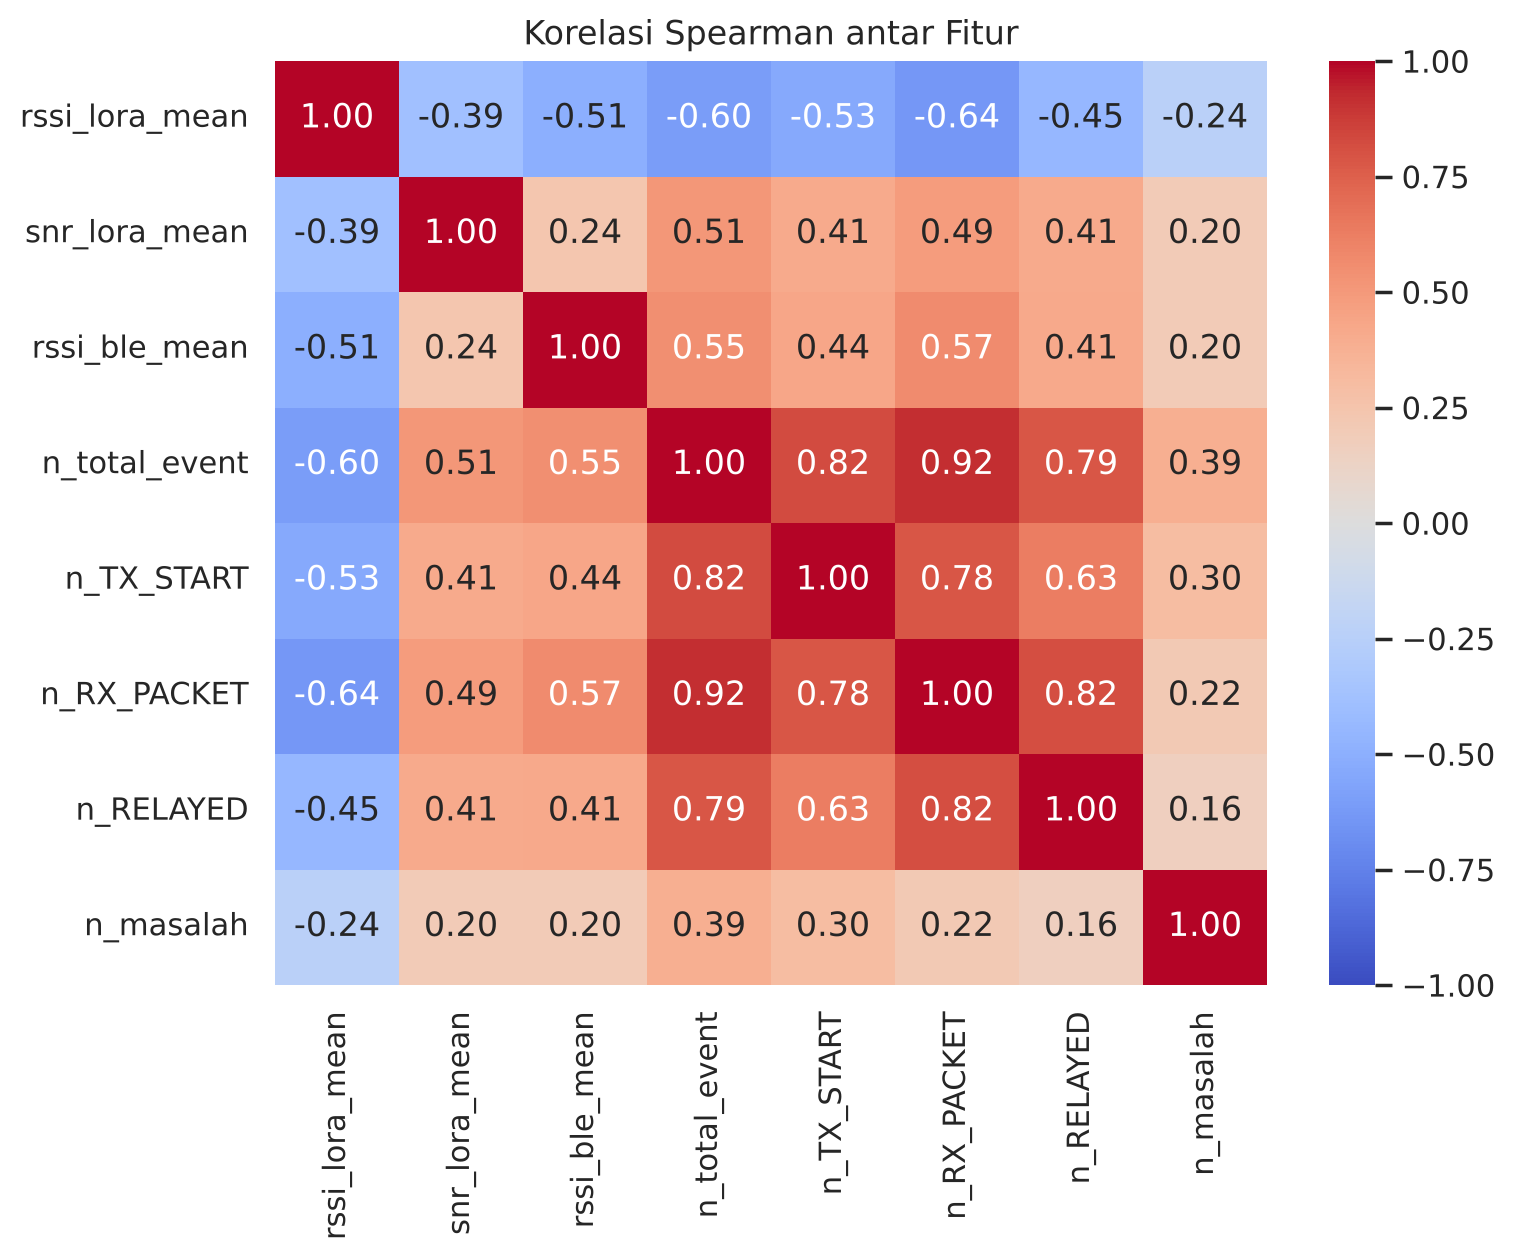

In [46]:
kolom_korelasi = ['rssi_lora_mean', 'snr_lora_mean', 'rssi_ble_mean', 'n_total_event', 'n_TX_START', 'n_RX_PACKET', 'n_RELAYED', 'n_masalah']
plt.figure(figsize=(8, 6))
sns.heatmap(fitur[kolom_korelasi].corr(method='spearman'), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Korelasi Spearman antar Fitur')
plt.show()

**Interpretasi:**
- **SNR tidak berbeda** antara window normal dan bermasalah (p = 0,33).
- **RSSI berbeda signifikan (p = 0,009).** Saat bermasalah, median RSSI LoRa **−89 dBm**, lebih lemah dibanding saat normal (**−83,4 dBm**).
- **Beban kirim juga berbeda signifikan (p = 0,013).** Saat bermasalah, median TX_START 1 kali per 10 detik, dibanding 0 saat normal.
- Heatmap menunjukkan hubungan `n_masalah` **lemah sampai sedang**: ρ ≈ 0,39 terhadap jumlah event, 0,30 terhadap TX_START, dan −0,24 terhadap RSSI LoRa.
- **Kesimpulannya, masalah di sesi ini dipicu dua hal sekaligus:** trafik yang lebih padat (yang menghabiskan airtime node) dan sinyal LoRa yang lebih lemah. Keduanya punya pengaruh, tetapi tidak ada yang dominan.

# **8. Analisis Quality of Service (QoS)**

QoS mengukur seberapa baik jaringan **mengantarkan data**. Mengikuti standar **TIPHON** (ETSI TR 101 329) yang umum dipakai di penelitian QoS, ada 4 parameter utama:

| Parameter | Pertanyaan yang dijawab | Rumus |
|---|---|---|
| **Throughput** | Berapa banyak data yang berhasil lewat per detik? | $\text{Throughput} = \dfrac{\text{jumlah bit diterima}}{\text{waktu pengamatan}}$ |
| **Packet loss** | Berapa persen paket yang hilang/gagal? | $\text{Packet loss} = \dfrac{\text{paket dikirim} - \text{paket diterima}}{\text{paket dikirim}} \times 100\%$ |
| **Delay** | Berapa lama paket sampai? | $\text{Delay rata-rata} = \dfrac{\sum \text{delay tiap paket}}{\text{jumlah paket}}$ |
| **Jitter** | Seberapa tidak konsisten delay-nya? | $\text{Jitter} = \dfrac{\sum \lvert D_i - D_{i-1} \rvert}{\text{jumlah paket}}$ |

## Standar Kategori TIPHON

| Indeks | Kategori | Packet loss | Delay | Jitter | Throughput (% efisiensi) |
|---|---|---|---|---|---|
| 4 | Sangat bagus | 0–2% | < 150 ms | 0 ms | 100% |
| 3 | Bagus | 3–14% | 150–300 ms | 0–75 ms | 75% |
| 2 | Sedang | 15–24% | 300–450 ms | 75–125 ms | 50% |
| 1 | Jelek | ≥ 25% | > 450 ms | 125–225 ms | < 25% |

Indeks keempat parameter dirata-rata untuk menilai QoS keseluruhan:

| Rata-rata indeks | Persentase | Kategori QoS |
|---|---|---|
| 3,8 – 4 | 95 – 100% | Sangat memuaskan |
| 3 – 3,79 | 75 – 94,75% | Memuaskan |
| 2 – 2,99 | 50 – 74,75% | Kurang memuaskan |
| 1 – 1,99 | 25 – 49,75% | Jelek |

## Catatan Penting untuk Jaringan LoRa
- TIPHON dirancang untuk jaringan IP/VoIP berkecepatan tinggi. LoRa SF7 secara fisik **hanya mampu sekitar 5,5 kbps** dan satu paket butuh **ratusan milidetik di udara**. Jadi delay LoRa hampir pasti tidak bisa masuk kategori "sangat bagus" (< 150 ms), meskipun jaringannya sehat. Hasil TIPHON di sini dipakai sebagai **pembanding standar**, dan setiap parameter juga dinilai terhadap batas kemampuan LoRa sendiri.
- Versi TIPHON berbasis Mbps (> 2,1 Mbps = sangat bagus) **tidak dipakai** karena mustahil dicapai LoRa. Throughput dinilai dengan versi **persentase**, yaitu **efisiensi**: berapa persen data yang dikirim aplikasi berhasil diterima node.
- Log berasal dari **satu HP**, jadi yang bisa diukur adalah QoS dari sisi pengirim/penerima di HP itu. Paket yang hilang di node penerima lain tidak tercatat di log ini.

## Fase Pengujian
Sesi dibagi tiga fase (variabel `FASE`) sesuai pola gangguan di log:
- **Fase 1 (gangguan awal), 13:12–13:16:** koneksi BLE ke NUSN-3 sering error (GATT error, gagal kirim), dan airtime NUSN-3 hampir habis.
- **Fase 2 (relatif stabil), 13:16–13:28:** sebagian besar pesan berhasil, walaupun ada handover bolak-balik dan radio NUSN-1 sempat tidak siap ±2 menit.
- **Fase 3 (koneksi putus), 13:28–13:40:** NUSN-3 sudah tidak aktif, dan HP berulang kali gagal terhubung ke NUSN-1.

**Yang dilakukan cell berikut:**
- Parameter radio LoRa yang dipakai node (sesuaikan dengan konfigurasi firmware)
- `LORA_SF`: spreading factor
- `LORA_BW`: bandwidth (Hz)
- `LORA_CR`: coding rate 4/5 -> 1, 4/6 -> 2, 4/7 -> 3, 4/8 -> 4
- `LORA_PREAMBLE`: jumlah simbol preamble
- Rentang waktu tiap fase pengujian (ubah sesuai sesi uji) dan warna tiap fase untuk grafik
- Fungsi bantu: ubah nilai parameter menjadi indeks TIPHON (4 = sangat bagus ... 1 = jelek)

In [47]:
LORA_SF       = 7
LORA_BW       = 125_000
LORA_CR       = 1
LORA_PREAMBLE = 8

FASE = {
    'Fase 1 (gangguan awal)':  (None,                  '2026-11-12 13:16:00'),
    'Fase 2 (relatif stabil)': ('2026-11-12 13:16:00', '2026-11-12 13:28:00'),
    'Fase 3 (koneksi putus)':  ('2026-11-12 13:28:00', None),
}
FASE = {nama: tuple(pd.Timestamp(t, tz=ZONA_WAKTU) if t else None for t in rentang) for nama, rentang in FASE.items()}
WARNA_FASE = dict(zip(FASE, ['#d03b3b', '#2a78d6', '#eda100']))

def indeks_packet_loss(persen):
    return 4 if persen <= 2 else 3 if persen < 15 else 2 if persen < 25 else 1

def indeks_delay(ms):
    return 4 if ms < 150 else 3 if ms <= 300 else 2 if ms <= 450 else 1

def indeks_jitter(ms):
    return 4 if ms == 0 else 3 if ms <= 75 else 2 if ms <= 125 else 1

def indeks_throughput(persen):
    return 4 if persen >= 100 else 3 if persen >= 75 else 2 if persen >= 50 else 1

def kategori_indeks(i):
    return {4: 'Sangat bagus', 3: 'Bagus', 2: 'Sedang', 1: 'Jelek'}[i]

def kategori_qos(rata2):
    return ('Sangat memuaskan' if rata2 >= 3.8 else 'Memuaskan' if rata2 >= 3
            else 'Kurang memuaskan' if rata2 >= 2 else 'Jelek')

## 8.1 Kapasitas Kanal LoRa dan Time-on-Air

**Tujuan:** mengetahui batas kemampuan fisik LoRa sebagai patokan. Ini penting supaya hasil throughput dan delay bisa dinilai secara adil.

**Bitrate LoRa** (kecepatan maksimum teoretis):

$$
R_b = SF \times \frac{BW}{2^{SF}} \times \frac{4}{4 + CR}
$$

**Time-on-Air (ToA)**, yaitu lama satu paket "mengudara" (rumus Semtech AN1200.13):

$$
T_{sym} = \frac{2^{SF}}{BW}, \qquad
N_{payload} = 8 + \max\left(\left\lceil \frac{8PL - 4SF + 28 + 16 - 20H}{4(SF - 2DE)} \right\rceil (CR + 4),\; 0\right)
$$

$$
ToA = (N_{preamble} + 4{,}25)\,T_{sym} + N_{payload}\,T_{sym}
$$

dengan $PL$ = ukuran payload (byte), $H = 0$ untuk header eksplisit, dan $DE = 1$ jika *low data rate optimization* aktif (hanya bila $T_{sym} > 16$ ms).

**Yang dilakukan cell berikut:**
- `t_sym`: lama 1 simbol (ms)
- `de`: low data rate optimization
- Tabel ToA untuk beberapa ukuran payload

In [48]:
def time_on_air_ms(payload_byte, sf=LORA_SF, bw=LORA_BW, cr=LORA_CR, preamble=LORA_PREAMBLE):
    t_sym = (2 ** sf) / bw * 1000
    de = 1 if t_sym > 16 else 0
    n_payload = 8 + max(np.ceil((8 * payload_byte - 4 * sf + 28 + 16 - 0) / (4 * (sf - 2 * de))) * (cr + 4), 0)
    return (preamble + 4.25) * t_sym + n_payload * t_sym

bitrate_lora = LORA_SF * LORA_BW / (2 ** LORA_SF) * 4 / (4 + LORA_CR)
print(f'Bitrate maksimum LoRa SF{LORA_SF}/BW{LORA_BW // 1000} kHz/CR4/{4 + LORA_CR}: {bitrate_lora:,.0f} bps ({bitrate_lora / 1000:.2f} kbps)')

tabel_toa = pd.DataFrame({'payload_byte': [10, 30, 50, 100, 150, 200, 255]})
tabel_toa['time_on_air_ms'] = tabel_toa['payload_byte'].apply(time_on_air_ms).round(1)
tabel_toa

Bitrate maksimum LoRa SF7/BW125 kHz/CR4/5: 5,469 bps (5.47 kbps)


,payload_byte,time_on_air_ms
0,10,41.2
1,30,71.9
2,50,97.5
3,100,174.3
4,150,246.0
5,200,317.7
6,255,399.6


**Yang dilakukan cell berikut:**
- Bandingkan airtime yang diperkirakan aplikasi (modeled_airtime_ms) dengan rumus ToA

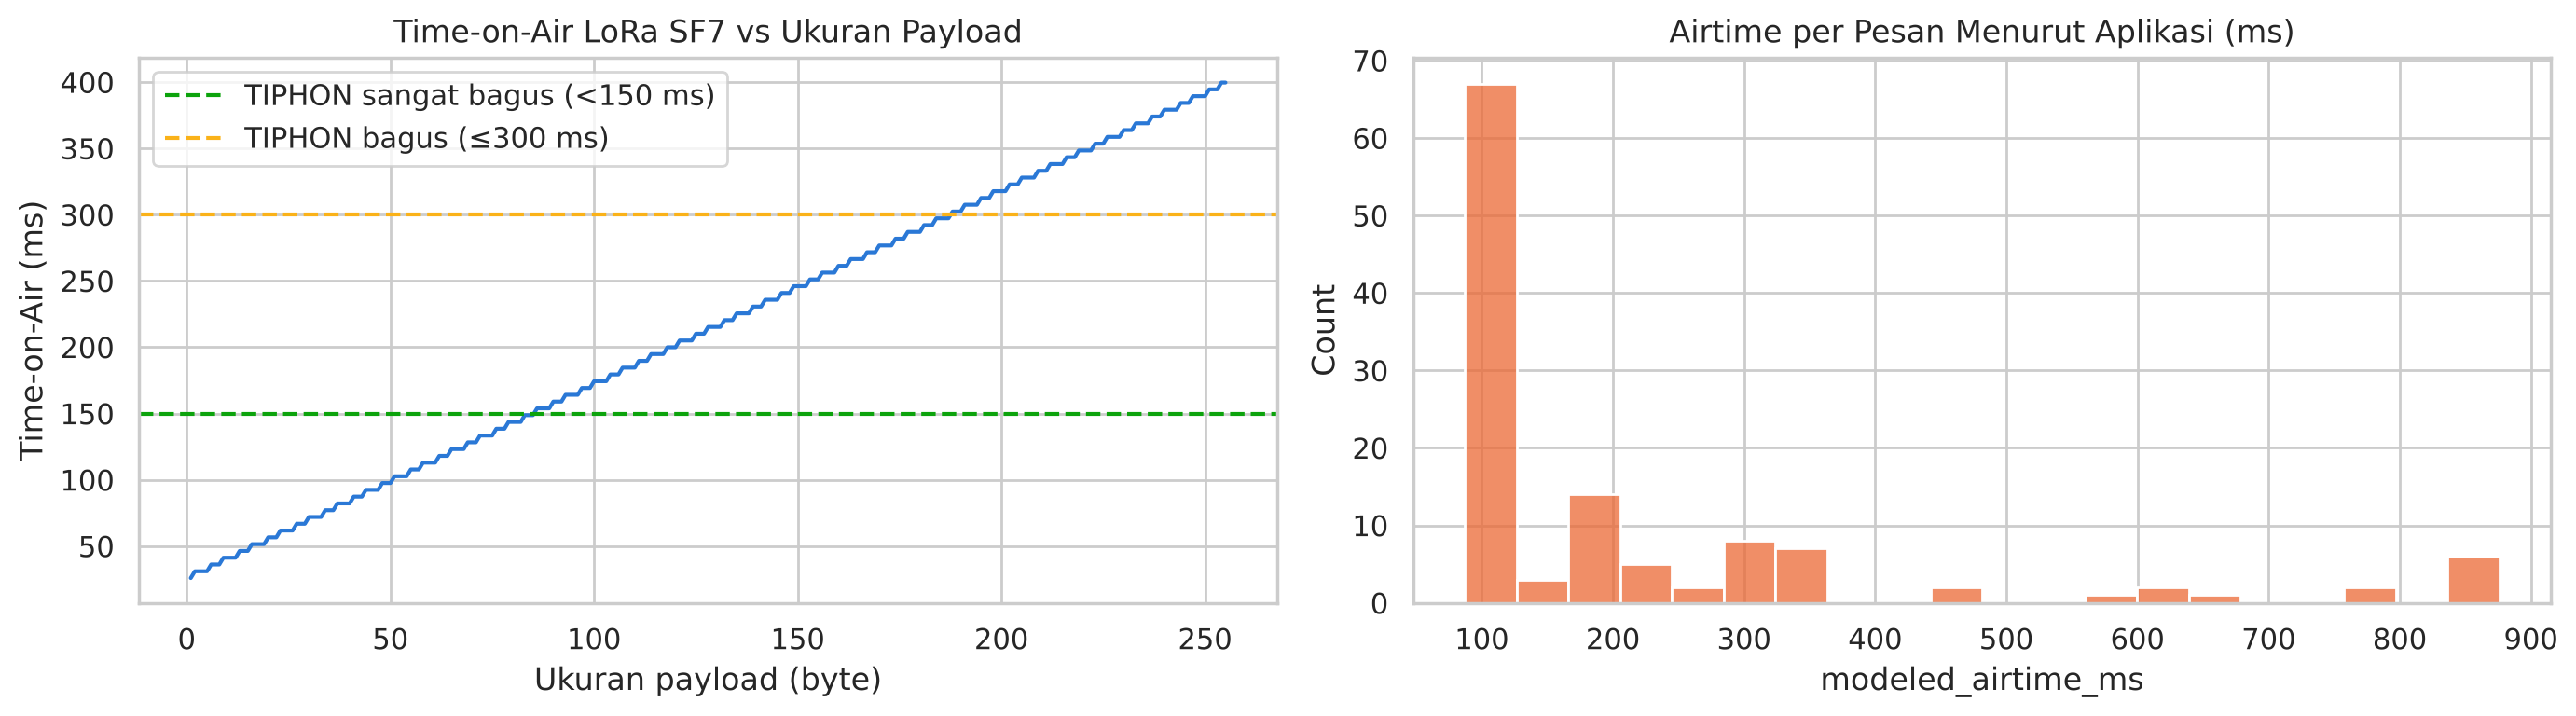

Airtime aplikasi: median 97 ms, rentang 87–14876 ms


In [49]:
airtime_app = df.loc[df['event'] == 'QUEUE_ACCEPTED', 'modeled_airtime_ms'].dropna()

ukuran = np.arange(1, 256)
toa = [time_on_air_ms(p) for p in ukuran]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(ukuran, toa, color='#2a78d6')
axes[0].axhline(150, color='#0ca30c', ls='--', label='TIPHON sangat bagus (<150 ms)')
axes[0].axhline(300, color='#fab219', ls='--', label='TIPHON bagus (≤300 ms)')
axes[0].set_xlabel('Ukuran payload (byte)'); axes[0].set_ylabel('Time-on-Air (ms)')
axes[0].set_title(f'Time-on-Air LoRa SF{LORA_SF} vs Ukuran Payload'); axes[0].legend()

sns.histplot(airtime_app[airtime_app < 1000], bins=20, color='#eb6834', ax=axes[1])
axes[1].set_title('Airtime per Pesan Menurut Aplikasi (ms)')
plt.tight_layout()
plt.show()

print(f'Airtime aplikasi: median {airtime_app.median():.0f} ms, rentang {airtime_app.min():.0f}–{airtime_app.max():.0f} ms')

**Interpretasi:**
- Bitrate maksimum LoRa pada SF7/BW125/CR4/5 hanya sekitar **5,47 kbps**, jauh lebih kecil dibanding jaringan IP yang menjadi acuan TIPHON.
- Karena itu airtime naik lurus dengan ukuran paket. Payload sekitar 85 byte sudah melewati 150 ms, dan payload sekitar 190 byte sudah melewati 300 ms.
- Median airtime di aplikasi **97 ms**, setara paket sekitar 50 byte (beacon/kontrol). Pesan teks berada di kisaran **199–338 ms**. Nilai maksimum **14.876 ms** berasal dari transfer file yang dipecah menjadi banyak fragmen.
- **Kesimpulan:** satu pesan teks LoRa *secara fisik* tidak mungkin masuk kategori delay "sangat bagus" (<150 ms). Itu batas teknologinya, bukan kesalahan sistem. Penilaian delay di bawah perlu dibaca dengan mengingat batas ini.

## 8.2 Throughput

**Tujuan:** mengukur berapa banyak data yang benar-benar lewat di setiap bagian jaringan.

Throughput diukur di 3 titik:
- **BLE (HP ↔ node):** semua byte yang dikirim dan diterima lewat Bluetooth.
- **LoRa mesh (diterima):** byte paket mesh **non-beacon** yang sampai ke HP, yaitu data yang benar-benar melewati LoRa.
- **Goodput** (*good data received*): byte isi pesan pengguna yang diterima (data bersih tanpa header/protokol).

Untuk LoRa juga dihitung **utilisasi kanal**:

$$
\text{Utilisasi} = \frac{\text{throughput LoRa terukur}}{R_b} \times 100\%
$$

**Yang dilakukan cell berikut:**
- Durasi pengamatan
- `mulai_lora`: LoRa baru aktif sejak frame pertama diterima

In [50]:
mulai_lora = df.loc[df['event'] == 'NODE_RX_FRAMES', 'waktu'].min()
selesai    = df['waktu'].max()
durasi_sesi = (selesai - df['waktu'].min()).total_seconds()
durasi_lora = (selesai - mulai_lora).total_seconds()

bit = lambda event, data=df: data.loc[data['event'] == event, 'bytes'].fillna(0).sum() * 8

paket_data_mesh = df[(df['event'] == 'RX_PACKET') & (df['type'] != 24)]
throughput = pd.DataFrame({
    'durasi (detik)': [durasi_sesi, durasi_lora, durasi_lora],
    'total bit':      [bit('RX_BYTES') + bit('TX_ACCEPTED'),
                       paket_data_mesh['bytes'].sum() * 8,
                       bit('MESSAGE_RECEIVED')],
}, index=['BLE (HP <-> node)', 'LoRa mesh diterima', 'Goodput pesan masuk'])
throughput['throughput (bps)'] = (throughput['total bit'] / throughput['durasi (detik)']).round(1)
throughput.loc[['LoRa mesh diterima', 'Goodput pesan masuk'], 'utilisasi kanal LoRa (%)'] = \
    (throughput.loc[['LoRa mesh diterima', 'Goodput pesan masuk'], 'throughput (bps)'] / bitrate_lora * 100).round(2)
throughput

,durasi (detik),total bit,throughput (bps),utilisasi kanal LoRa (%)
BLE (HP <-> node),1652.355,1148640,695.2,NaN
LoRa mesh diterima,1649.039,279376,169.4,3.10
Goodput pesan masuk,1649.039,25608,15.5,0.28


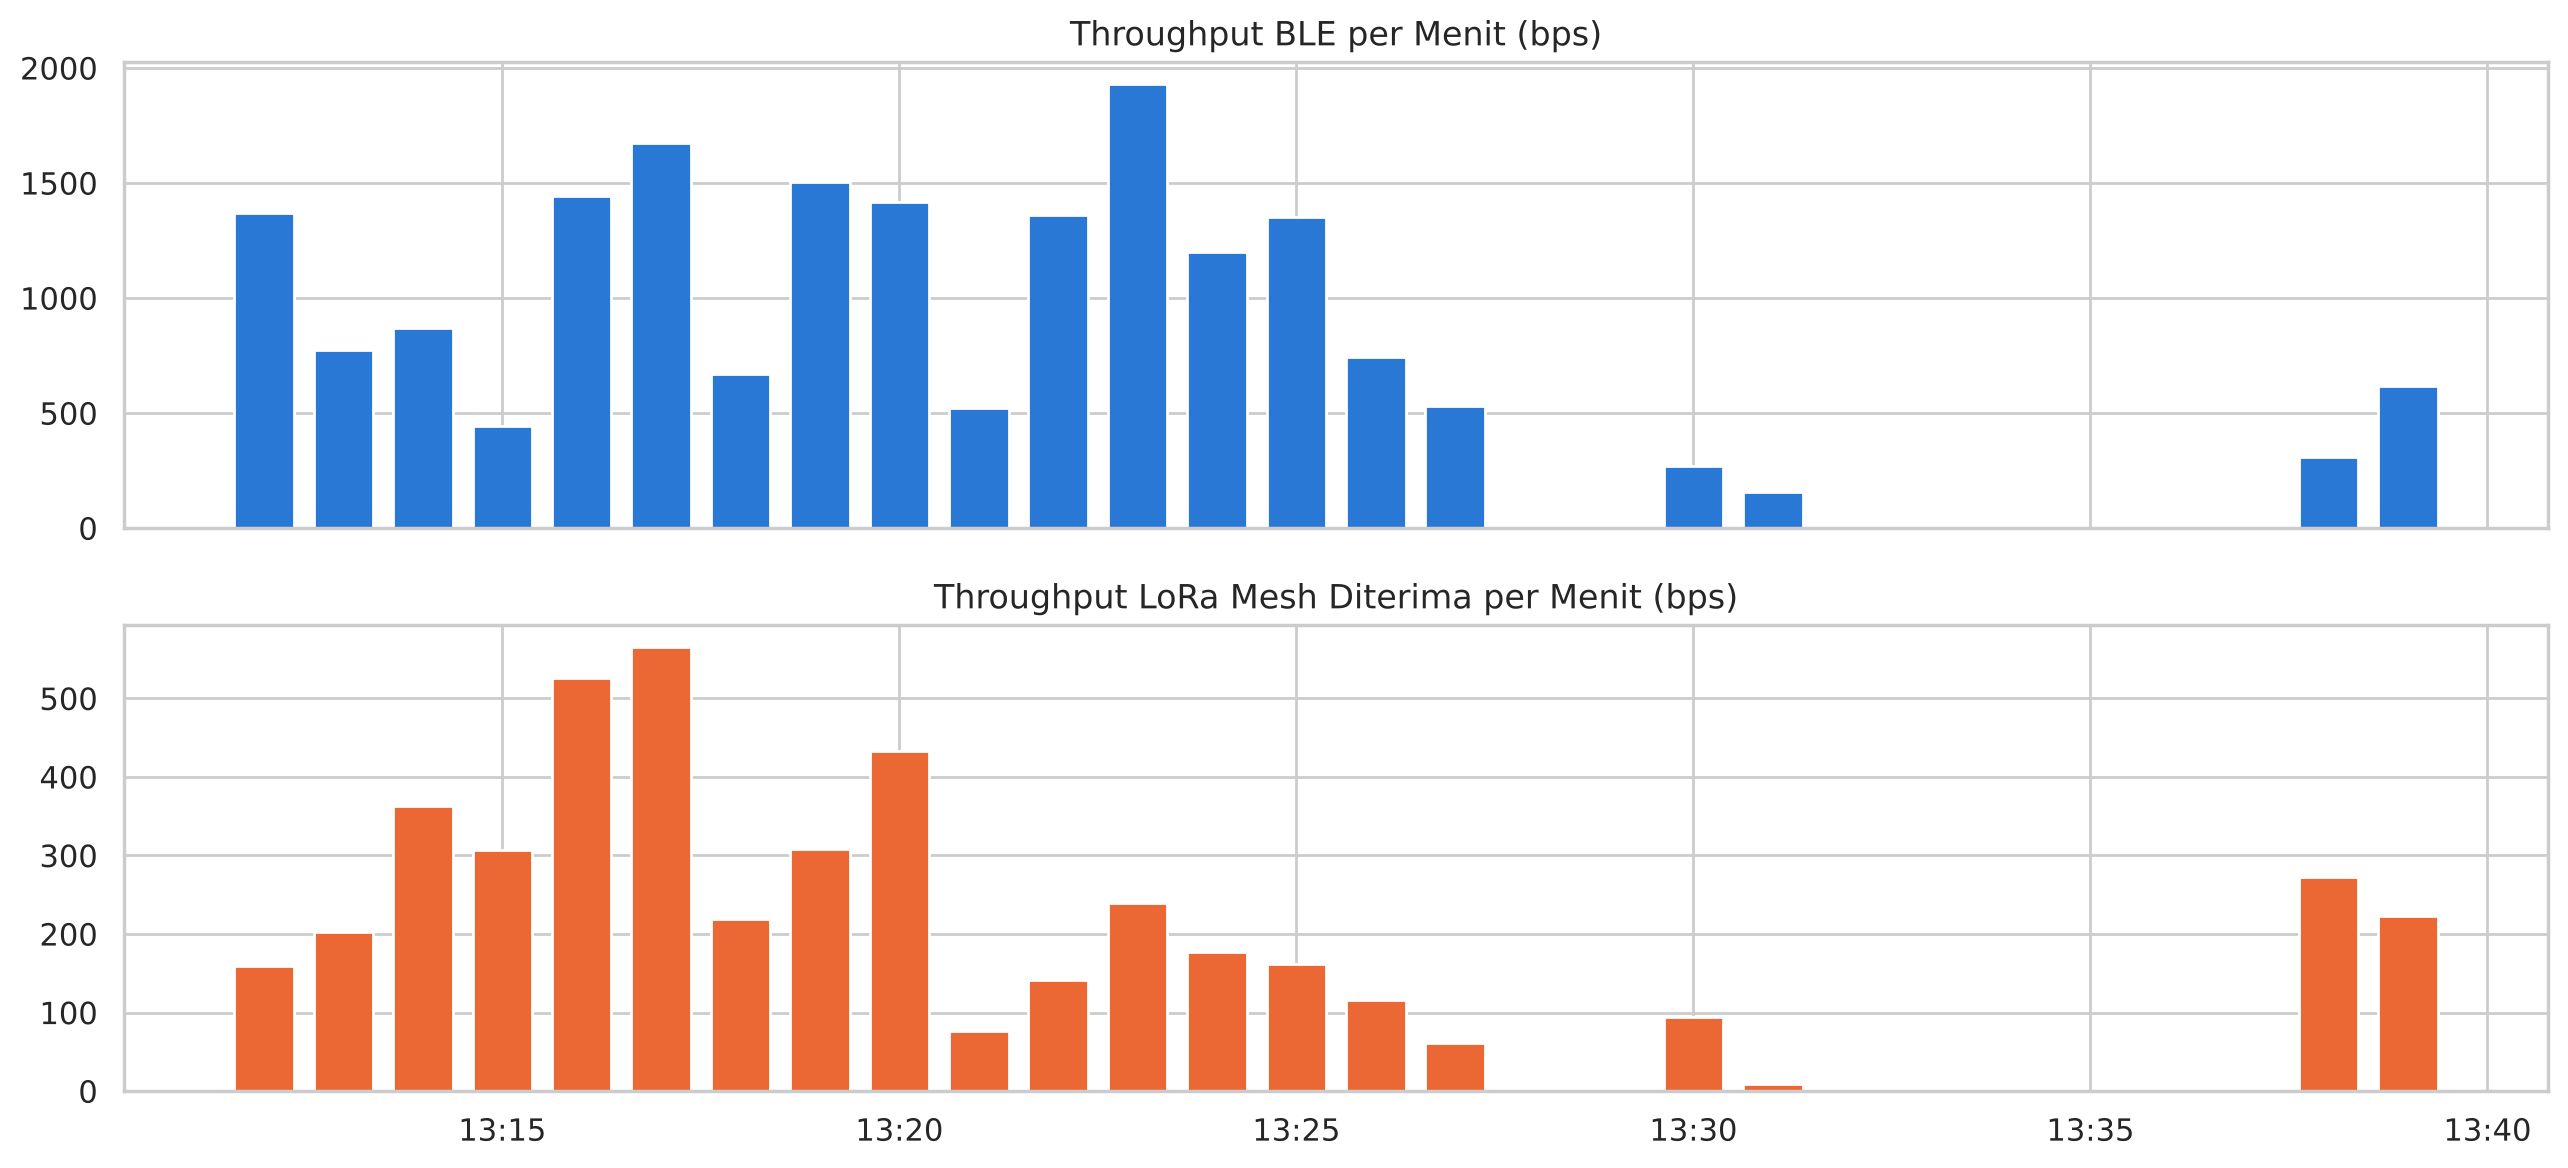

In [51]:
log = df.set_index('waktu')
per_menit = pd.DataFrame({
    'BLE':       (log['bytes'].where(log['event'].isin(['RX_BYTES', 'TX_ACCEPTED'])).resample('1min').sum() * 8 / 60),
    'LoRa mesh': (log['bytes'].where((log['event'] == 'RX_PACKET') & (log['type'] != 24)).resample('1min').sum() * 8 / 60),
})

fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
axes[0].bar(per_menit.index, per_menit['BLE'], width=pd.Timedelta(seconds=45), color='#2a78d6')
axes[0].set_title('Throughput BLE per Menit (bps)')
axes[1].bar(per_menit.index, per_menit['LoRa mesh'], width=pd.Timedelta(seconds=45), color='#eb6834')
axes[1].set_title('Throughput LoRa Mesh Diterima per Menit (bps)')
axes[1].xaxis.set_major_formatter(FORMAT_JAM)
plt.tight_layout()
plt.show()

**Yang dilakukan cell berikut:**
- Efisiensi throughput (dipakai untuk indeks TIPHON):
- Bit yang dikirim aplikasi ke node DAN diterima node, dibagi semua bit yang dicoba dikirim (termasuk kiriman ulang)
- Pesan yang gagal tanpa sempat dikirim sama sekali tetap dihitung sebagai data yang ditawarkan (1 frame)

In [52]:
def efisiensi_throughput(data):
    dicoba    = data.loc[data['event'] == 'TX_START', 'bytes'].fillna(0).sum()
    diterima  = data.loc[data['event'] == 'TX_ACCEPTED', 'bytes'].fillna(0).sum()
    gagal_tanpa_kirim = pesan[(pesan['status'] == 'gagal') & (pesan['jumlah_kirim'] == 0)]
    gagal_tanpa_kirim = gagal_tanpa_kirim[gagal_tanpa_kirim['waktu_mulai'].isin(data['waktu'])]
    dicoba += len(gagal_tanpa_kirim) * 256
    return diterima / dicoba * 100 if dicoba > 0 else np.nan

print(f'Efisiensi throughput keseluruhan: {efisiensi_throughput(df):.1f}%')

Efisiensi throughput keseluruhan: 81.0%


**Interpretasi:**
- **BLE (HP ↔ node) ±695 bps.** Ini trafik yang terpakai, bukan kapasitas BLE. Nilainya masih di atas throughput LoRa terukur (±169 bps), jadi kapasitas BLE bukan bottleneck. Masalah BLE di sesi ini ada di **kestabilan koneksi**, bukan kecepatan.
- **LoRa mesh yang diterima ±169 bps**, atau hanya **3,1%** dari kapasitas kanal. Kanal LoRa masih jauh dari penuh. Yang membatasi node adalah **jatah airtime per node** (duty cycle), bukan kanalnya.
- **Goodput pesan ±15,5 bps (0,28%)**, sesuai untuk aplikasi chat yang trafiknya sesekali.
- Grafik per menit menunjukkan trafik ramai pada 13:12–13:27, lalu hampir nol setelah 13:28 saat koneksi ke node putus.
- **Efisiensi throughput 81,0%:** sekitar seperlima byte yang diminta aplikasi tidak sampai ke radio. Penyebabnya adalah 19 penulisan BLE yang gagal dan pesan yang gagal sebelum sempat dikirim (terutama di Fase 3).

## 8.3 Packet Loss

**Tujuan:** mengukur persentase paket yang hilang di **setiap lapisan** jaringan, supaya ketahuan di mana kehilangan paling banyak terjadi.

| Lapisan | Paket dikirim | Paket hilang |
|---|---|---|
| Aplikasi → node | pesan yang selesai diproses | `MESSAGE_LOCAL_FAILED` |
| Tulis BLE | `TX_START` | `TX_FAILED` |
| Antrean node | frame TX + frame dibuang | `dropped` (dari `NODE_HEALTH`) |
| Link LoRa (udara) | frame RX + frame rusak | `crc` (dari `NODE_HEALTH`) |

In [53]:
pesan_keluar = pesan[pesan['arah'] == 'keluar']
n_berhasil = (pesan_keluar['status'].isin(['terkirim tanpa ACK', 'terkirim + ACK'])).sum()
n_gagal    = (pesan_keluar['status'] == 'gagal').sum()

total_tx, total_drop = health['tambah_tx'].sum(), health['tambah_dropped'].sum()
total_rx, total_crc  = health['tambah_rx'].sum(), health['tambah_crc'].sum()

packet_loss = pd.DataFrame({
    'dikirim': [n_berhasil + n_gagal, (df['event'] == 'TX_START').sum(), total_tx + total_drop, total_rx + total_crc],
    'hilang':  [n_gagal, (df['event'] == 'TX_FAILED').sum(), total_drop, total_crc],
}, index=['Aplikasi -> node (pesan)', 'Tulis BLE (frame)', 'Antrean node (frame)', 'Link LoRa / udara (frame)'])
packet_loss['packet loss (%)'] = (packet_loss['hilang'] / packet_loss['dikirim'] * 100).round(2)
packet_loss['indeks TIPHON'] = packet_loss['packet loss (%)'].apply(indeks_packet_loss)
packet_loss['kategori'] = packet_loss['indeks TIPHON'].apply(kategori_indeks)
packet_loss

,dikirim,hilang,packet loss (%),indeks TIPHON,kategori
Aplikasi -> node (pesan),61.0,20.0,32.79,1,Jelek
Tulis BLE (frame),188.0,19.0,10.11,3,Bagus
Antrean node (frame),508.0,121.0,23.82,2,Sedang
Link LoRa / udara (frame),450.0,14.0,3.11,3,Bagus


**Yang dilakukan cell berikut:**
- Packet loss link LoRa (CRC error) per menit, dari laporan NODE_HEALTH

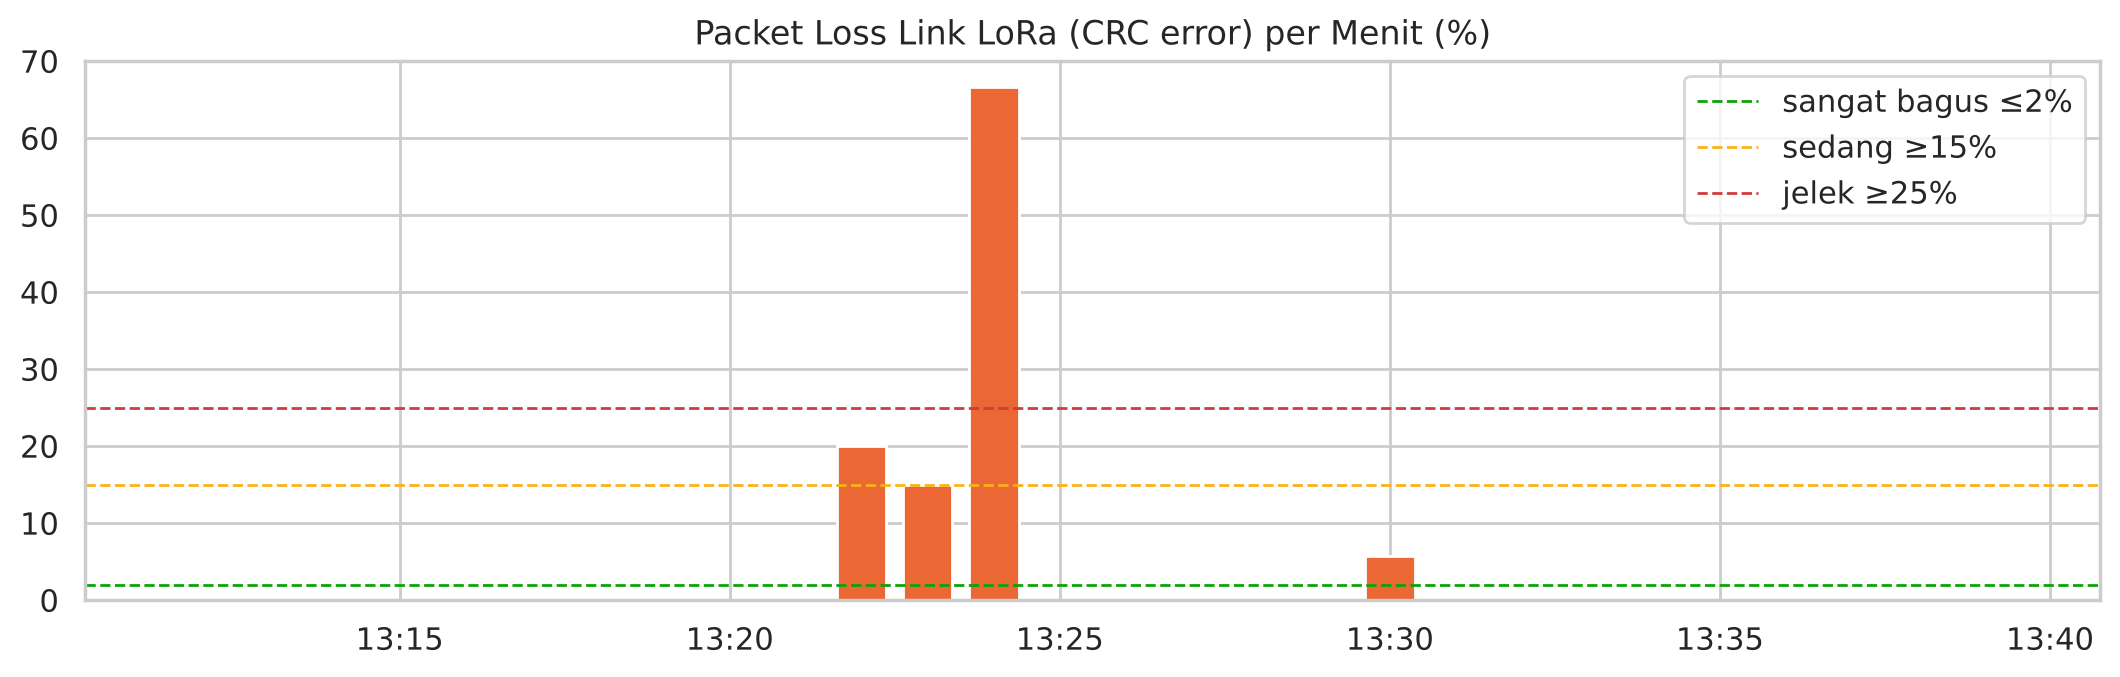

In [54]:
crc_menit = health.set_index('waktu')[['tambah_rx', 'tambah_crc']].resample('1min').sum()
crc_menit['loss_%'] = crc_menit['tambah_crc'] / (crc_menit['tambah_rx'] + crc_menit['tambah_crc']) * 100

fig, ax = plt.subplots(figsize=(13, 3.5))
ax.bar(crc_menit.index, crc_menit['loss_%'], width=pd.Timedelta(seconds=45), color='#eb6834')
for batas, warna, label in [(2, '#0ca30c', 'sangat bagus ≤2%'), (15, '#fab219', 'sedang ≥15%'), (25, '#d03b3b', 'jelek ≥25%')]:
    ax.axhline(batas, color=warna, ls='--', lw=1, label=label)
ax.set_title('Packet Loss Link LoRa (CRC error) per Menit (%)')
ax.xaxis.set_major_formatter(FORMAT_JAM)
ax.legend(loc='upper right')
plt.show()

**Interpretasi:** packet loss dihitung **per lapisan** supaya terlihat di titik mana paket hilang.

| Lapisan | Loss | Artinya |
|---|---|---|
| Aplikasi → node | **32,8%** (Jelek) | 20 dari 61 pesan gagal; 13 di antaranya terjadi di Fase 3 saat HP tidak bisa terhubung ke NUSN-1 |
| Tulis BLE | **10,1%** (Bagus) | 19 dari 188 penulisan gagal, kebanyakan ke NUSN-3 di awal sesi |
| Antrean node | **23,8%** (Sedang) | 121 frame dibuang karena antrean penuh saat airtime node habis |
| Link LoRa (CRC) | **3,1%** (Bagus) | frame rusak di udara sedikit; puncaknya 15–20% per menit pada 13:22–13:23 saat sinyal NUSN-3 jatuh |

- **Kesimpulan:** loss terbesar **bukan di link radio**, melainkan di **koneksi HP ke node** dan **antrean node yang penuh**. Hal ini sesuai dengan pembagian fase: loss aplikasi **15,0% di Fase 1**, **16,7% di Fase 2**, dan melonjak ke **76,5% di Fase 3**.

## 8.4 Delay

**Tujuan:** mengukur berapa lama sebuah pesan sampai ke udara, dan bagian mana yang paling lama.

Delay tiap pesan keluar dihitung sebagai jumlah 3 komponen:

$$
D_{pesan} = D_{antre} + D_{tulis\ BLE} + D_{airtime}
$$

- $D_{antre}$: lama menunggu di antrean aplikasi (`QUEUE_DEQUEUED`),
- $D_{tulis\ BLE}$: lama menulis pesan ke node lewat BLE (`TX_ACCEPTED`),
- $D_{airtime}$: lama pesan mengudara di LoRa (`modeled_airtime_ms`).

Transfer **file** dihitung terpisah karena satu file dipecah menjadi banyak fragmen LoRa, sehingga delay-nya tidak sebanding dengan pesan teks.

Sebagai pembanding, **round-trip time (RTT)** dari pesan yang mendapat ACK juga ditampilkan. Delay satu arah ≈ RTT ÷ 2.

**Yang dilakukan cell berikut:**
- Hanya pesan yang punya ketiga komponen (pesan yang benar-benar terkirim)
- Transfer FILE dipisahkan: satu file dipecah jadi banyak fragmen LoRa, jadi delay-nya
- Tidak sebanding dengan pesan teks (kelas layanan berbeda)

In [55]:
event_keluar = df[df['message_id'].isin(pesan_keluar.index)]

delay = pd.DataFrame({
    'waktu':        pesan_keluar['waktu_mulai'],
    'antre_ms':     pesan_keluar['lama_antre_ms'].astype(float),
    'tulis_ble_ms': event_keluar[event_keluar['event'] == 'TX_ACCEPTED'].groupby('message_id')['duration_ms'].mean().astype(float),
    'airtime_ms':   event_keluar[event_keluar['event'] == 'QUEUE_ACCEPTED'].groupby('message_id')['modeled_airtime_ms'].max(),
})
delay = delay.dropna().sort_values('waktu')
delay['delay_total_ms'] = delay[['antre_ms', 'tulis_ble_ms', 'airtime_ms']].sum(axis=1)

delay_file = delay[delay.index.str.startswith('file-')]
delay = delay[~delay.index.str.startswith('file-')]

print(f'Jumlah pesan teks yang dihitung delay-nya: {len(delay)}')
print(f'Transfer file (dipisah): {len(delay_file)} file, delay total {delay_file["delay_total_ms"].round(0).tolist()} ms')
delay[['antre_ms', 'tulis_ble_ms', 'airtime_ms', 'delay_total_ms']].describe(percentiles=[.5, .9]).round(1)

Jumlah pesan teks yang dihitung delay-nya: 26
Transfer file (dipisah): 4 file, delay total [799.0, 755.0, 7346.0, 1038.0] ms


,antre_ms,tulis_ble_ms,airtime_ms,delay_total_ms
count,26.0,26.0,26.0,26.0
mean,2083.5,300.7,250.3,2634.6
std,4203.8,491.1,55.5,4298.9
min,1.0,3.0,199.0,239.0
50%,35.0,144.3,212.5,636.5
90%,5404.5,656.5,333.0,5908.3
max,15177.0,2316.0,338.0,16626.5


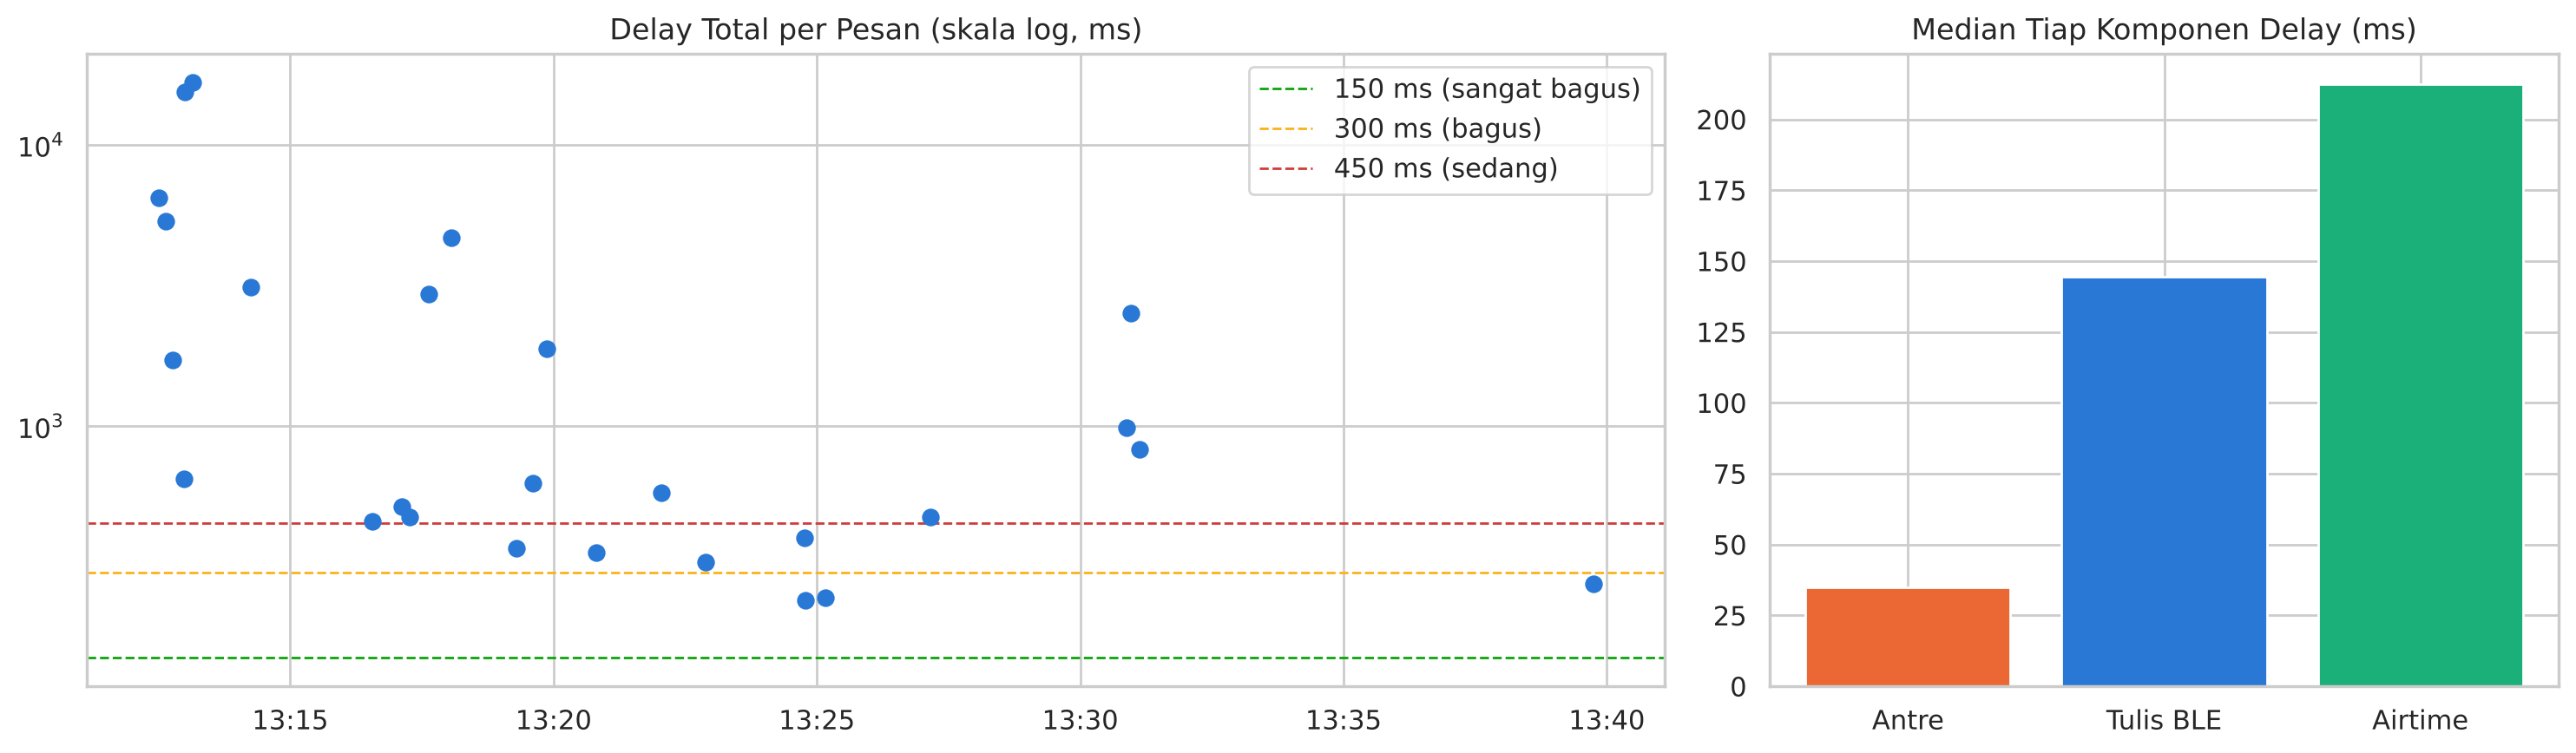

RTT (pesan ber-ACK, n=11): rata-rata 33,242 ms -> delay satu arah ≈ 16,621 ms


In [56]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={'width_ratios': [2, 1]})

axes[0].scatter(delay['waktu'], delay['delay_total_ms'], color='#2a78d6', s=40, zorder=3)
for batas, warna, label in [(150, '#0ca30c', '150 ms (sangat bagus)'), (300, '#fab219', '300 ms (bagus)'), (450, '#d03b3b', '450 ms (sedang)')]:
    axes[0].axhline(batas, color=warna, ls='--', lw=1, label=label)
axes[0].set_yscale('log')
axes[0].set_title('Delay Total per Pesan (skala log, ms)')
axes[0].xaxis.set_major_formatter(FORMAT_JAM)
axes[0].legend(loc='upper right')

komponen = delay[['antre_ms', 'tulis_ble_ms', 'airtime_ms']].median()
axes[1].bar(['Antre', 'Tulis BLE', 'Airtime'], komponen.values, color=['#eb6834', '#2a78d6', '#1baf7a'])
axes[1].set_title('Median Tiap Komponen Delay (ms)')
plt.tight_layout()
plt.show()

rtt = pesan_keluar['latency_ack_ms'].dropna().astype(float)
print(f'RTT (pesan ber-ACK, n={len(rtt)}): rata-rata {rtt.mean():,.0f} ms -> delay satu arah ≈ {rtt.mean() / 2:,.0f} ms')

**Interpretasi:**
- Delay dihitung dari **26 pesan teks**. Empat transfer file dipisah, dengan delay 755–7.346 ms.
- **Rata-rata (2.635 ms) jauh di atas median (636,5 ms).** Sebagian besar pesan cukup cepat, tetapi beberapa pesan di awal sesi (13:12–13:13) tertahan di antrean **15 detik**. Delay terbesar **16,6 detik**.
- **Komponen median:** antrean ±35 ms, tulis BLE ±144 ms, dan **airtime ±212,5 ms**. Dalam kondisi normal **airtime LoRa tetap penyumbang terbesar**, tetapi tulis BLE ikut besar. Pada 13:30–13:31 tulis BLE sampai **2,3 detik**, saat sinyal BLE ke NUSN-1 lemah.
- Median delay (636,5 ms) berada di kategori **"jelek"** (>450 ms). Sebarannya: 11,5% pesan < 300 ms, 15,4% di 300–450 ms, dan 73,1% > 450 ms.
- RTT pesan ber-ACK: median **±3,5 detik** (n = 11). Rata-ratanya 33,2 detik karena satu ACK yang terlambat ±5 menit, jadi rata-rata RTT tidak bisa dipakai.
- **Kesimpulan:** delay jaringan (BLE + airtime) rata-rata **±551 ms**, di atas batas fisik LoRa SF7 (±200–340 ms untuk pesan teks). Kelebihannya berasal dari **tulis BLE yang lambat** dan **antrean saat node sibuk**.

## 8.5 Jitter

**Tujuan:** mengukur seberapa **tidak konsisten** delay antar paket. Jitter besar artinya waktu sampai paket sulit ditebak.

Dua cara pengukuran:
1. **Jitter delay pesan** (rumus TIPHON): rata-rata selisih delay antar pesan berurutan.
2. **Jitter beacon**: setiap node memancarkan beacon secara berkala (±2 detik) dan HP ikut menerimanya lewat node yang terhubung. Kalau jaringan stabil, jarak antar beacon seharusnya konstan, sehingga variasinya menunjukkan ketidakstabilan link HP ↔ node.

$$
\text{Jitter} = \frac{\sum_{i=2}^{n} \lvert D_i - D_{i-1} \rvert}{n}
$$

**Yang dilakukan cell berikut:**
- `1)` Jitter delay pesan
- Jitter tanpa komponen antrean (hanya tulis BLE + airtime) untuk melihat jitter jaringan murni

In [57]:
variasi_delay = delay['delay_total_ms'].diff().abs()
jitter_pesan = variasi_delay.sum() / len(delay)

delay_jaringan = delay['tulis_ble_ms'] + delay['airtime_ms']
jitter_jaringan = delay_jaringan.diff().abs().sum() / len(delay)

print(f'Jitter delay pesan (total)          : {jitter_pesan:,.1f} ms')
print(f'Jitter jaringan (tanpa antrean)     : {jitter_jaringan:,.1f} ms')

Jitter delay pesan (total)          : 2,109.6 ms
Jitter jaringan (tanpa antrean)     : 340.1 ms


**Yang dilakukan cell berikut:**
- `2)` Jitter beacon per node (beacon type 24 yang diterima HP)
- Interval > 10 detik dianggap koneksi terputus/berpindah node, bukan jitter

In [58]:
beacon = df[(df['event'] == 'RX_PACKET') & (df['type'] == 24)].copy()
beacon['node'] = beacon['sender'].apply(nama_node)
beacon = beacon.sort_values('waktu')
beacon['interval_ms'] = beacon.groupby('node')['time_ms'].diff().astype(float)

beacon_ok = beacon[beacon['interval_ms'] <= 10_000]
jitter_beacon = beacon_ok.groupby('node')['interval_ms'].agg(
    jumlah='count',
    interval_rata2_ms='mean',
    jitter_ms=lambda x: x.diff().abs().mean(),
).round(1)
jitter_beacon

,jumlah,interval_rata2_ms,jitter_ms
node,,,
NUSN-1,154,2043.6,513.5
NUSN-3,206,2021.6,649.1


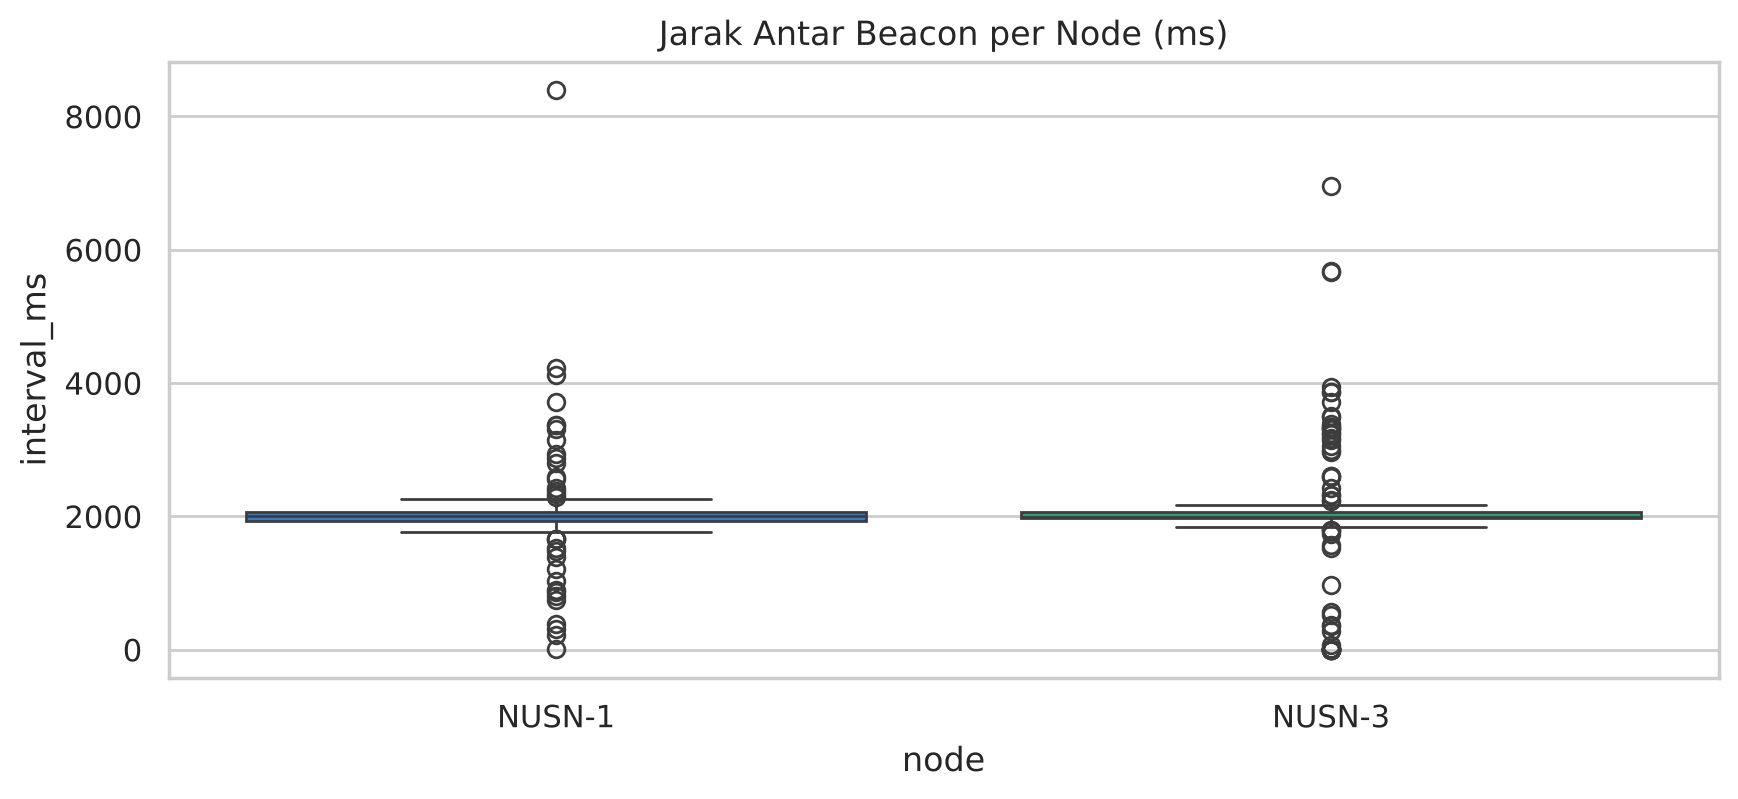

In [59]:
plt.figure(figsize=(10, 4))
sns.boxplot(data=beacon_ok, x='node', y='interval_ms', hue='node', palette=WARNA_NODE, legend=False,
            order=sorted(beacon_ok['node'].unique()))
plt.title('Jarak Antar Beacon per Node (ms)')
plt.show()

**Interpretasi:**
- **Jitter total ±2,1 detik** didominasi variasi waktu antre: ada pesan yang langsung terkirim, ada juga yang tertahan sampai 15 detik.
- **Jitter jaringan ±340 ms** (tanpa antrean), masuk kategori jelek. Di Fase 2 nilainya turun ke **±108 ms (Sedang)**. Artinya radio dan BLE lebih stabil saat koneksi HP ke node lancar.
- **Jitter beacon:** interval rata-rata kedua node sudah sekitar 2 detik, tetapi jitternya tinggi: **NUSN-1 ±514 ms** dan **NUSN-3 ±649 ms**. Banyak beacon yang hilang atau terlambat (interval sampai 7–8 detik), sesuai dengan koneksi BLE yang sering putus dan handover bolak-balik.
- **Kesimpulan:** sumber jitter adalah **koneksi BLE yang tidak stabil** dan **antrean saat airtime node habis**, bukan link LoRa itu sendiri.

## 8.6 Ketersediaan (Availability) dan Pemakaian Airtime

**Tujuan:** menilai apakah node **siap melayani**, dan seberapa banyak jatah airtime yang terpakai.

$$
\text{Availability} = \frac{\text{waktu radio siap}}{\text{waktu node aktif}} \times 100\%
$$

In [60]:
availability = health.groupby('node').agg(
    laporan=('radio_ready', 'size'),
    radio_siap_persen=('radio_ready', lambda x: round(x.astype(float).mean() * 100, 1)),
    punya_tetangga_persen=('neighbors', lambda x: round((x > 0).mean() * 100, 1)),
    airtime_awal_ms=('budget_ms', 'first'),
    airtime_terendah_ms=('budget_ms', 'min'),
)
availability['airtime_terpakai_maks_%'] = ((1 - availability['airtime_terendah_ms'] / availability['airtime_awal_ms'].max()) * 100).round(1)
availability

,laporan,radio_siap_persen,punya_tetangga_persen,airtime_awal_ms,airtime_terendah_ms,airtime_terpakai_maks_%
node,,,,,,
NUSN-1,41,73.2,68.3,308.0,15.0,95.1
NUSN-3,44,100.0,100.0,161.0,20.0,93.5


**Interpretasi:**
- **NUSN-1: radio siap 73,2%** dan punya tetangga 68,3% dari laporan. Radionya tidak siap ±2 menit (13:24:31–13:26:23), lalu normal kembali.
- **NUSN-3: radio siap 100%**, tetapi laporannya berhenti setelah 13:24, dan HP tidak lagi menemukannya setelah 13:29.
- **Airtime kedua node hampir habis:** terpakai maksimum **95,1%** (NUSN-1, sisa 15 ms) dan **93,5%** (NUSN-3, sisa 20 ms). Laju kirim keduanya sebenarnya mirip (±0,23 dan ±0,26 frame/detik), tetapi NUSN-3 hampir selalu kehabisan budget sejak awal log.
- **Kesimpulan:** bottleneck sesi ini adalah **jatah airtime node** (terutama NUSN-3) dan **ketersediaan node** (NUSN-1 sempat tidak siap, NUSN-3 berhenti aktif).

## 8.7 Indeks QoS TIPHON per Fase

**Tujuan:** merangkum keempat parameter menjadi satu nilai QoS, lalu membandingkan **fase gangguan** dengan **fase stabil**.

Parameter yang dipakai untuk indeks:
- **Throughput**: efisiensi throughput.
- **Packet loss**: lapisan aplikasi → node (pesan), karena paling mencerminkan pengalaman pengguna.
- **Delay** dan **Jitter**: dihitung dengan dua sudut pandang:
  - **QoS pengguna**: termasuk waktu menunggu di antrean aplikasi, yaitu yang benar-benar dirasakan pengguna.
  - **QoS jaringan**: tanpa antrean aplikasi (hanya tulis BLE + airtime LoRa), yaitu kinerja jaringannya saja.

**Yang dilakukan cell berikut:**
- Pilih data sesuai rentang waktu
- `d_jaringan`: delay tanpa antrean aplikasi

In [61]:
def hitung_qos(mulai=None, akhir=None):
    m_pesan = pesan_keluar.copy()
    m_delay = delay.copy()
    m_df = df.copy()
    if mulai is not None:
        m_pesan = m_pesan[m_pesan['waktu_mulai'] >= mulai]; m_delay = m_delay[m_delay['waktu'] >= mulai]; m_df = m_df[m_df['waktu'] >= mulai]
    if akhir is not None:
        m_pesan = m_pesan[m_pesan['waktu_mulai'] < akhir]; m_delay = m_delay[m_delay['waktu'] < akhir]; m_df = m_df[m_df['waktu'] < akhir]

    berhasil = m_pesan['status'].isin(['terkirim tanpa ACK', 'terkirim + ACK']).sum()
    gagal = (m_pesan['status'] == 'gagal').sum()

    d_jaringan = m_delay['tulis_ble_ms'] + m_delay['airtime_ms']
    n = len(m_delay)

    nilai = {
        'Throughput (efisiensi %)':      efisiensi_throughput(m_df),
        'Packet loss (%)':               gagal / (berhasil + gagal) * 100 if berhasil + gagal > 0 else np.nan,
        'Delay total (ms)':              m_delay['delay_total_ms'].mean(),
        'Jitter total (ms)':             m_delay['delay_total_ms'].diff().abs().sum() / n if n else np.nan,
        'Delay jaringan (ms)':           d_jaringan.mean(),
        'Jitter jaringan (ms)':          d_jaringan.diff().abs().sum() / n if n else np.nan,
    }
    fungsi = {
        'Throughput (efisiensi %)': indeks_throughput, 'Packet loss (%)': indeks_packet_loss,
        'Delay total (ms)': indeks_delay, 'Jitter total (ms)': indeks_jitter,
        'Delay jaringan (ms)': indeks_delay, 'Jitter jaringan (ms)': indeks_jitter,
    }
    indeks = {k: fungsi[k](v) for k, v in nilai.items()}
    return pd.DataFrame({'nilai': pd.Series(nilai).round(1), 'indeks': pd.Series(indeks)})

hasil_fase = {'Keseluruhan': hitung_qos()}
for nama, (mulai, akhir) in FASE.items():
    hasil_fase[nama] = hitung_qos(mulai=mulai, akhir=akhir)
tabel_qos = pd.concat(hasil_fase, axis=1)
tabel_qos

Keseluruhan        Fase 1 (gangguan awal)         \
                               nilai indeks                  nilai indeks   
Throughput (efisiensi %)        81.0      3                   69.3      2   
Packet loss (%)                 32.8      1                   15.0      2   
Delay total (ms)              2634.6      1                 7049.5      1   
Jitter total (ms)             2109.6      1                 5049.0      1   
Delay jaringan (ms)            551.0      1                  517.5      1   
Jitter jaringan (ms)           340.1      1                  399.3      1   

                         Fase 2 (relatif stabil)         \
                                           nilai indeks   
Throughput (efisiensi %)                    94.0      3   
Packet loss (%)                             16.7      2   
Delay total (ms)                           969.8      1   
Jitter total (ms)                          837.7      1   
Delay jaringan (ms)                        407.0      2   
Jitter jaringan (ms)                       108.1      2   

                         Fase 3 (koneksi putus)         
                                          nilai indeks  
Throughput (efisiensi %)                   36.4      1  
Packet loss (%)                            76.5      1  
Delay total (ms)                         1151.2      1  
Jitter total (ms)                         947.2      1  
Delay jaringan (ms)                      1149.8      1  
Jitter jaringan (ms)                      947.0      1

**Yang dilakukan cell berikut:**
- Dua sudut pandang:
- `-` QoS pengguna : delay & jitter TERMASUK waktu menunggu di antrean aplikasi (yang dirasakan pengguna)
- `-` QoS jaringan : delay & jitter TANPA antrean aplikasi (kinerja BLE + LoRa saja)

In [62]:
PARAM_PENGGUNA = ['Throughput (efisiensi %)', 'Packet loss (%)', 'Delay total (ms)', 'Jitter total (ms)']
PARAM_JARINGAN = ['Throughput (efisiensi %)', 'Packet loss (%)', 'Delay jaringan (ms)', 'Jitter jaringan (ms)']

baris = []
for fase, t in hasil_fase.items():
    for sudut, param in [('QoS pengguna', PARAM_PENGGUNA), ('QoS jaringan', PARAM_JARINGAN)]:
        rata2 = t.loc[param, 'indeks'].mean()
        baris.append({'fase': fase, 'sudut pandang': sudut, 'rata-rata indeks': round(rata2, 2),
                      'persentase': f'{rata2 / 4 * 100:.1f}%', 'kategori QoS': kategori_qos(rata2)})
ringkasan_qos = pd.DataFrame(baris).set_index(['fase', 'sudut pandang'])
ringkasan_qos

rata-rata indeks persentase  \
fase                    sudut pandang                                
Keseluruhan             QoS pengguna               1.50      37.5%   
                        QoS jaringan               1.50      37.5%   
Fase 1 (gangguan awal)  QoS pengguna               1.50      37.5%   
                        QoS jaringan               1.50      37.5%   
Fase 2 (relatif stabil) QoS pengguna               1.75      43.8%   
                        QoS jaringan               2.25      56.2%   
Fase 3 (koneksi putus)  QoS pengguna               1.00      25.0%   
                        QoS jaringan               1.00      25.0%   

                                           kategori QoS  
fase                    sudut pandang                    
Keseluruhan             QoS pengguna              Jelek  
                        QoS jaringan              Jelek  
Fase 1 (gangguan awal)  QoS pengguna              Jelek  
                        QoS jaringan              Jelek  
Fase 2 (relatif stabil) QoS pengguna              Jelek  
                        QoS jaringan   Kurang memuaskan  
Fase 3 (koneksi putus)  QoS pengguna              Jelek  
                        QoS jaringan              Jelek

**Yang dilakukan cell berikut:**
- Visualisasi indeks per parameter per fase

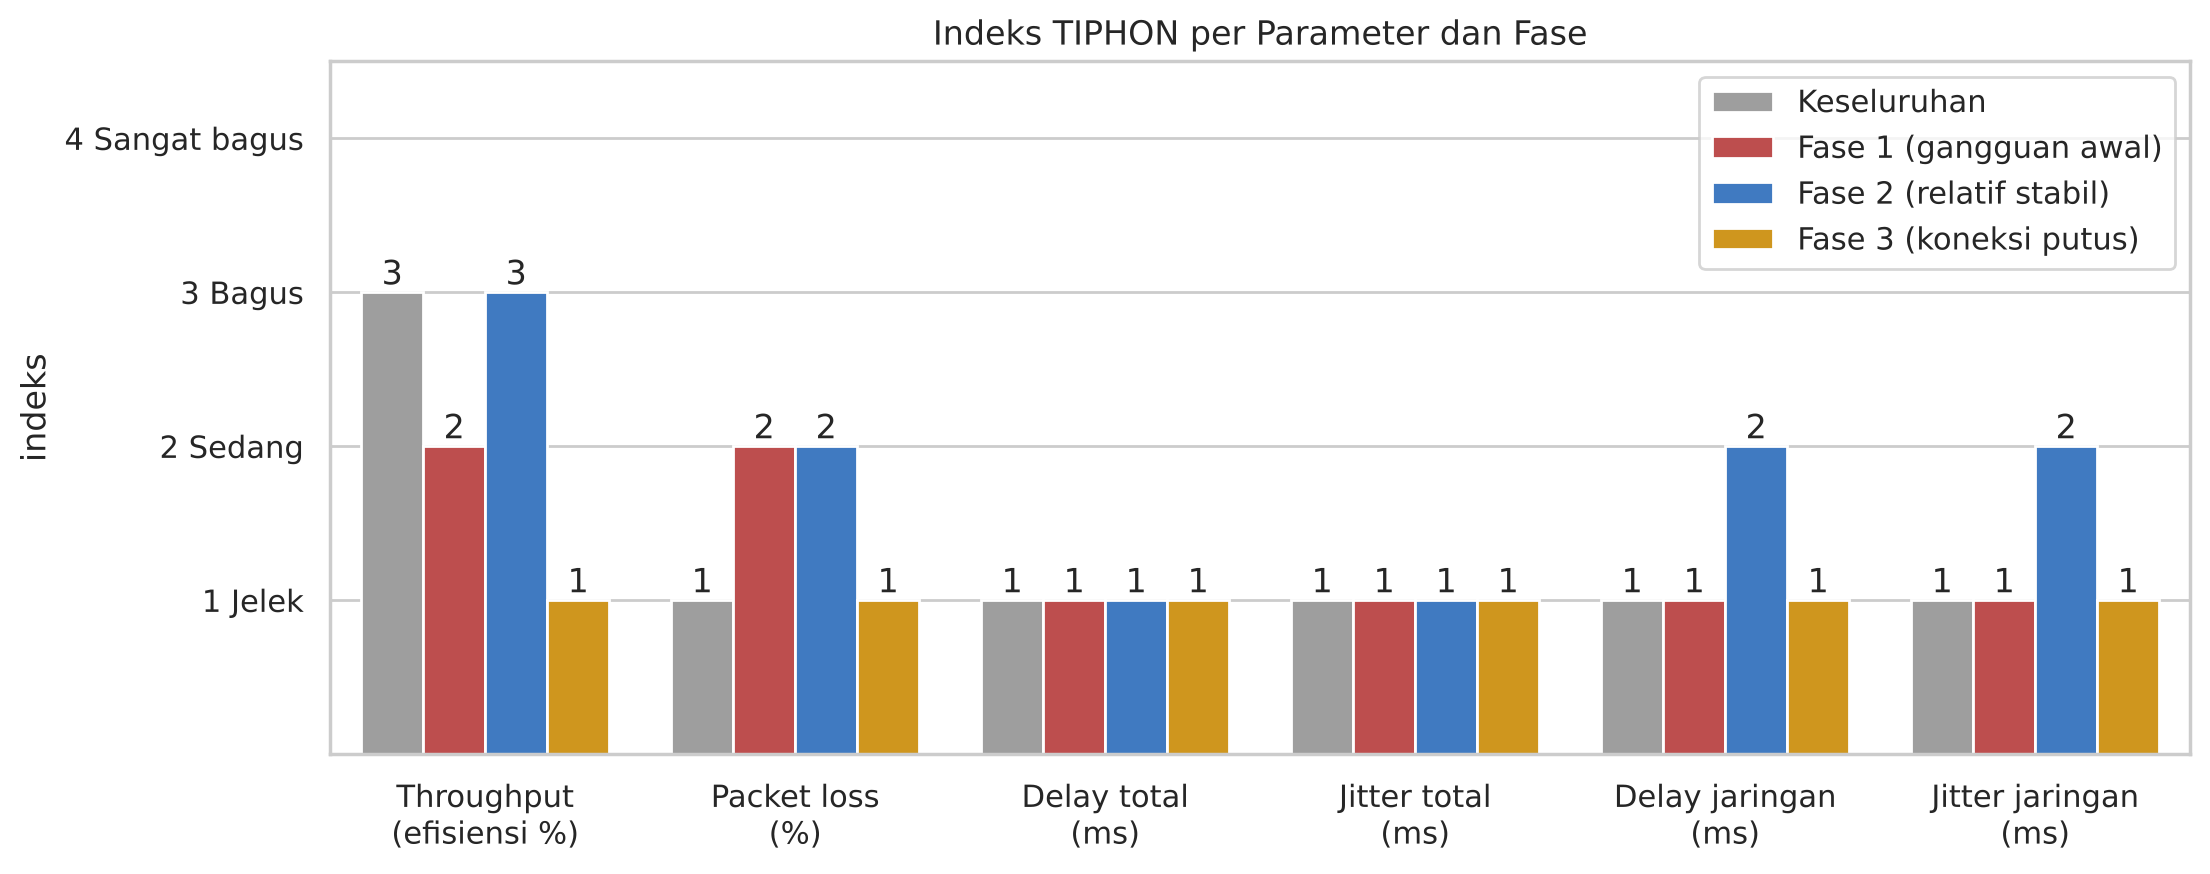

In [63]:
data_plot = pd.concat({f: t['indeks'] for f, t in hasil_fase.items()}, axis=1).reset_index().melt(
    id_vars='index', var_name='fase', value_name='indeks')

plt.figure(figsize=(12, 4.5))
ax = sns.barplot(data=data_plot, x='index', y='indeks', hue='fase',
                 palette={'Keseluruhan': '#9e9e9e', **WARNA_FASE})
for c in ax.containers:
    ax.bar_label(c)
ax.set_yticks([1, 2, 3, 4], ['1 Jelek', '2 Sedang', '3 Bagus', '4 Sangat bagus'])
ax.set_ylim(0, 4.5)
ax.set_xlabel('')
ax.set_xticks(range(data_plot['index'].nunique()), [t.replace(' (', '\n(') for t in data_plot['index'].unique()])
ax.set_title('Indeks TIPHON per Parameter dan Fase')
ax.legend(loc='upper right')
plt.show()

**Interpretasi:**

| Fase | QoS pengguna (termasuk antrean) | QoS jaringan (BLE + LoRa) |
|---|---|---|
| Keseluruhan | 1,50 – **Jelek** | 1,50 – **Jelek** |
| Fase 1 (gangguan awal) | 1,50 – **Jelek** | 1,50 – **Jelek** |
| Fase 2 (relatif stabil) | 1,75 – **Jelek** | **2,25 – Kurang memuaskan** |
| Fase 3 (koneksi putus) | 1,00 – **Jelek** | 1,00 – **Jelek** |

- **Fase 2 adalah kondisi terbaik di sesi ini:** throughput 94% (3), loss 16,7% (2), delay jaringan 407 ms (2), dan jitter jaringan 108 ms (2). Hasil akhirnya **Kurang memuaskan**, belum mencapai "Memuaskan".
- **Fase 1** turun karena throughput hanya 69,3% dan delay/jitter tinggi akibat antrean di awal sesi.
- **Fase 3 paling buruk:** throughput 36,4% dan packet loss 76,5%, karena HP tidak bisa terhubung ke node. Delay Fase 3 hanya dihitung dari 4 pesan yang berhasil terkirim.
- Dari sisi pengguna, QoS tetap jelek di semua fase karena **delay dan jitter** yang besar. Perbaikan paling berdampak ada di **kestabilan koneksi BLE HP ↔ node** dan **pengaturan airtime node**, bukan di daya radio LoRa.
- Catatan: TIPHON dibuat untuk jaringan IP (VoIP), jadi untuk LoRa kategori delay sebaiknya dibaca bersama batas fisik ToA.

# **9. Analisis Parameter Uji TA (Dokumen CD-2)**

Bagian ini mencocokkan isi log dengan **parameter kinerja pada Tabel 1.3** dan **pemeriksaan pada Tabel 1.4** dokumen CD-2 NusaMesh. Semua parameter yang **masih bisa diolah** dari dua file log dibahas di sini. Parameter yang tidak bisa diolah dicatat di matriks 9.8 dan menjadi dasar saran logging di bagian 10.

| Parameter CD-2 | Dibahas di | Catatan |
|---|---|---|
| RSSI LoRa & BLE (rata-rata, terendah, tertinggi) | 9.1 | Tanpa variasi jarak (jarak tidak tercatat) |
| SNR per koneksi antarnode | 9.1 | |
| PDR dan PLR | 9.2 | **Pendekatan** per lapisan, karena belum ada paket uji bernomor |
| Penerusan pesan (hop) & pesan tampil satu kali | 9.3 | Hop ditaksir dari TTL |
| Airtime & duty cycle (batas 5% / 1%) | 9.4 | Airtime per frame ditaksir dari ukuran paket |
| Penggunaan ponsel per node & perpindahan pengguna | 9.5 | |
| Jenis dan ukuran pesan | 9.6 | Jenis suara/gambar/lokasi belum dibedakan di log |
| Frekuensi, lebar pita, SF, daya pancar | 9.7 | Frekuensi & daya tidak tercatat |
| Throughput BLE & LoRa, delay | sudah di 8.2 dan 8.4 | Tidak diulang |

Rumus yang dipakai:

$$PDR = \frac{N_{diterima}}{N_{dikirim}} \times 100\% \qquad PLR = 100\% - PDR$$

$$\text{Duty cycle} = \frac{\sum T_{airtime}}{T_{pengamatan}} \times 100\% \qquad \text{Airtime per jam} = \text{Duty cycle} \times 3600\ \text{s}$$

$$\text{Hop} = TTL_{awal} - TTL_{diterima} + 1$$

## 9.1 RSSI dan SNR (rata-rata, terendah, tertinggi)

CD-2 meminta RSSI LoRa dilaporkan sebagai **rata-rata, terendah, dan tertinggi**, serta SNR pada setiap koneksi antarnode. Ada dua sumber nilai di log:
- `NODE_RX_FRAMES`: RSSI/SNR frame yang diterima radio node (laporan kesehatan node).
- `RX_META_MATCHED`: RSSI/SNR **per paket yang sampai ke ponsel penerima**. Sumber ini paling dekat dengan definisi CD-2 (dicatat di sisi penerima).

RSSI BLE diambil dari `RSSI_SCAN` (pemindaian ponsel ke node). Garis batas: sensitivitas SF7 = −124 dBm, batas SNR SF7 = −7,5 dB.

**Yang dilakukan cell berikut:**
- Gabungkan dua sumber: frame di node (NODE_RX_FRAMES) dan paket di ponsel (RX_META_MATCHED)
- `RX_META_MATCHED` memakai MAC BLE node, jadi dipetakan dulu ke nama node

In [64]:
sumber_nama = {'NODE_RX_FRAMES': 'Frame diterima node', 'RX_META_MATCHED': 'Paket diterima ponsel'}
meta = df[(df['event'] == 'RX_META_MATCHED') & df['rssi_dbm'].notna()].copy()
meta['node'] = meta['device_id'].map(mac_ke_node)
sinyal_cd2 = pd.concat([sinyal[sinyal['event'] == 'NODE_RX_FRAMES'], meta.dropna(subset=['node'])])
sinyal_cd2['sumber'] = sinyal_cd2['event'].map(sumber_nama)

tabel_rssi_snr = (sinyal_cd2
                  .groupby(['node', 'sumber'])
                  .agg(jumlah=('rssi_dbm', 'size'),
                       rssi_rata2=('rssi_dbm', 'mean'), rssi_min=('rssi_dbm', 'min'), rssi_maks=('rssi_dbm', 'max'),
                       snr_rata2=('snr_db', 'mean'), snr_min=('snr_db', 'min'), snr_maks=('snr_db', 'max'))
                  .round(2))
tabel_rssi_snr

jumlah  rssi_rata2  rssi_min  rssi_maks  \
node   sumber                                                           
NUSN-1 Frame diterima node        54      -85.90    -101.0      -68.0   
       Paket diterima ponsel      18      -86.33     -94.0      -70.0   
NUSN-3 Frame diterima node        94      -93.85    -130.3      -85.0   
       Paket diterima ponsel      34      -91.26     -97.8      -86.0   

                              snr_rata2  snr_min  snr_maks  
node   sumber                                               
NUSN-1 Frame diterima node         7.22     -6.0      10.3  
       Paket diterima ponsel       8.49      2.8      10.0  
NUSN-3 Frame diterima node         6.58     -9.0      10.3  
       Paket diterima ponsel       8.44     -7.8      10.3

**Yang dilakukan cell berikut:**
- Ringkasan RSSI BLE (ponsel -> node) per node

In [65]:
scan_ble = df[(df['event'] == 'RSSI_SCAN') & df['rssi_dbm'].notna()].copy()
scan_ble['node'] = scan_ble['device_id'].map(mac_ke_node)
tabel_rssi_ble = (scan_ble.dropna(subset=['node']).groupby('node')['rssi_dbm']
                  .agg(jumlah='size', rata2='mean', terendah='min', tertinggi='max').round(1))
print('Perangkat BLE lain yang terpindai tapi bukan node NusaMesh:',
      scan_ble['node'].isna().sum(), 'kali dari', scan_ble.loc[scan_ble['node'].isna(), 'device_id'].nunique(), 'perangkat')
tabel_rssi_ble

Perangkat BLE lain yang terpindai tapi bukan node NusaMesh: 24 kali dari 4 perangkat


,jumlah,rata2,terendah,tertinggi
node,,,,
NUSN-1,73,-87.8,-98.0,-48.0
NUSN-3,56,-80.8,-96.0,-68.0


**Yang dilakukan cell berikut:**
- `(a)` Sebaran RSSI LoRa per node
- `(b)` Sebaran SNR per node
- `(c)` Hubungan RSSI dan SNR

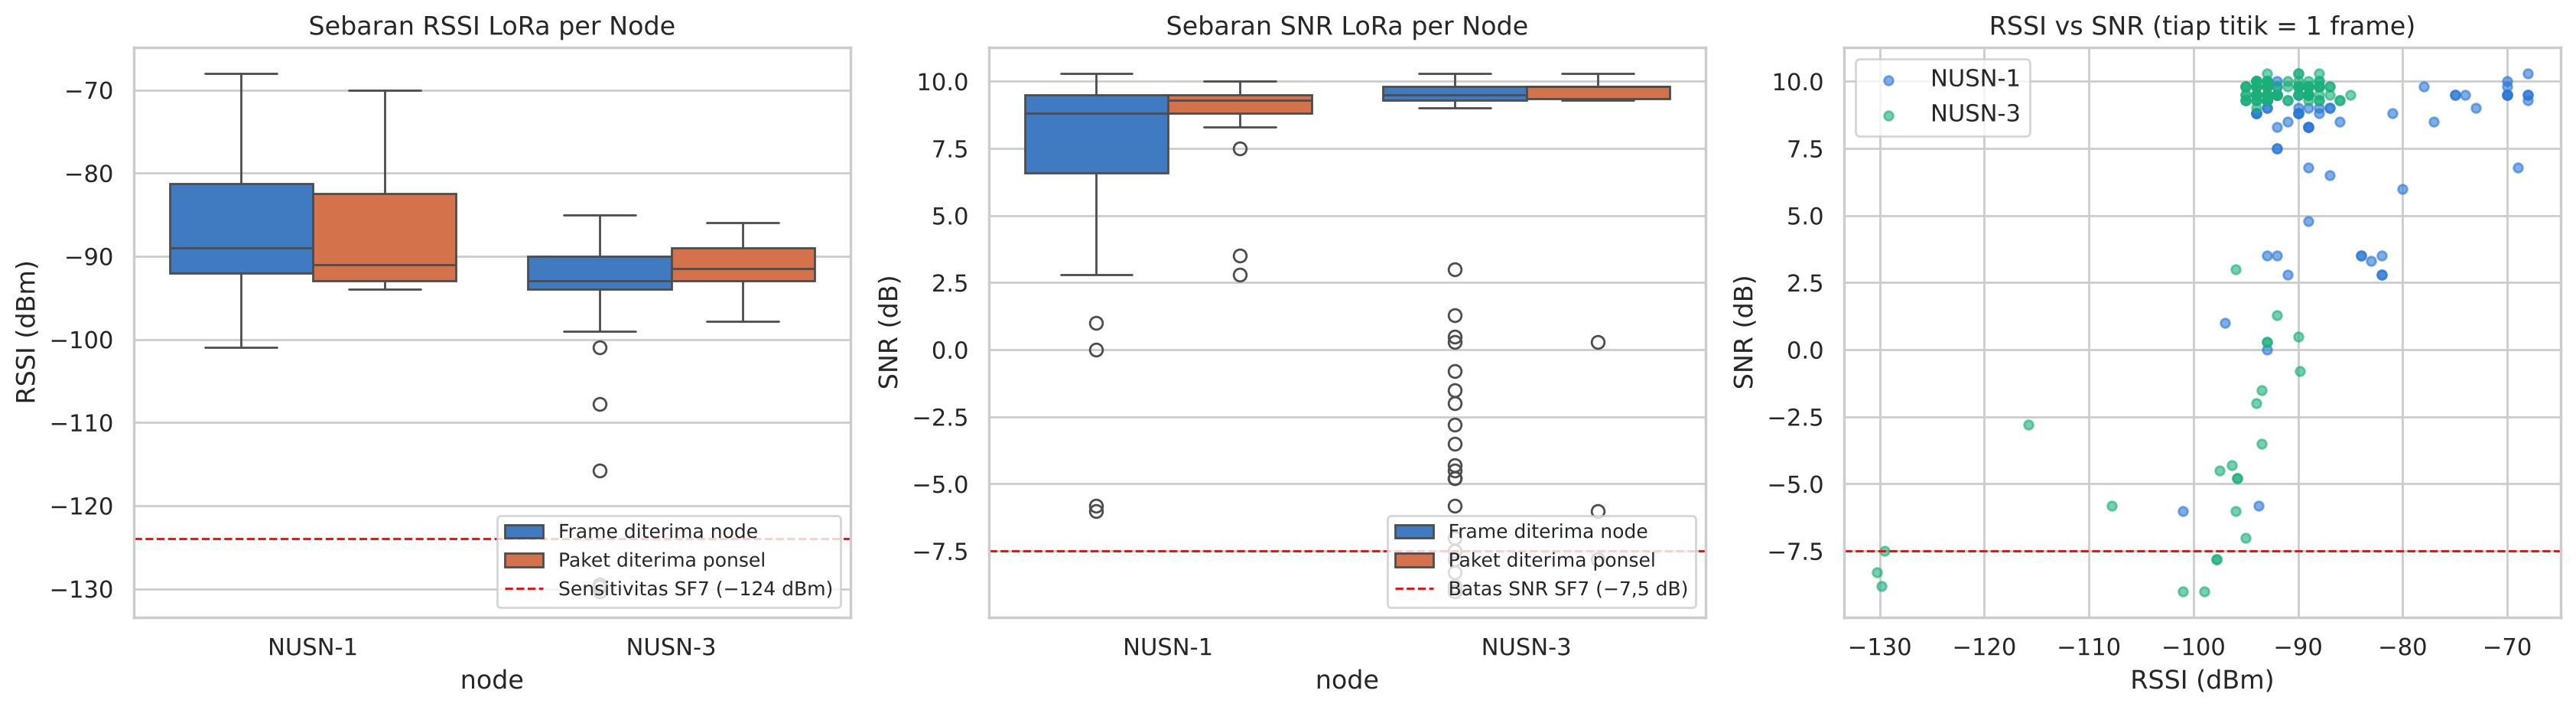

In [66]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
urut = sorted(sinyal_cd2['node'].unique())

sns.boxplot(data=sinyal_cd2, x='node', y='rssi_dbm', order=urut, hue='sumber', palette=['#2a78d6', '#eb6834'], ax=axes[0])
axes[0].axhline(SENSITIVITAS_SF7, color='red', ls='--', lw=1, label='Sensitivitas SF7 (−124 dBm)')
axes[0].set_title('Sebaran RSSI LoRa per Node')
axes[0].set_ylabel('RSSI (dBm)'); axes[0].legend(loc='lower right', fontsize=9)

sns.boxplot(data=sinyal_cd2, x='node', y='snr_db', order=urut, hue='sumber', palette=['#2a78d6', '#eb6834'], ax=axes[1])
axes[1].axhline(SNR_MIN_SF7, color='red', ls='--', lw=1, label='Batas SNR SF7 (−7,5 dB)')
axes[1].set_title('Sebaran SNR LoRa per Node')
axes[1].set_ylabel('SNR (dB)'); axes[1].legend(loc='lower right', fontsize=9)

for n in urut:
    s = sinyal_cd2[sinyal_cd2['node'] == n]
    axes[2].scatter(s['rssi_dbm'], s['snr_db'], s=18, alpha=0.6, color=WARNA_NODE[n], label=n)
axes[2].axhline(SNR_MIN_SF7, color='red', ls='--', lw=1)
axes[2].set_xlabel('RSSI (dBm)'); axes[2].set_ylabel('SNR (dB)')
axes[2].set_title('RSSI vs SNR (tiap titik = 1 frame)')
axes[2].legend()
plt.tight_layout(); plt.show()

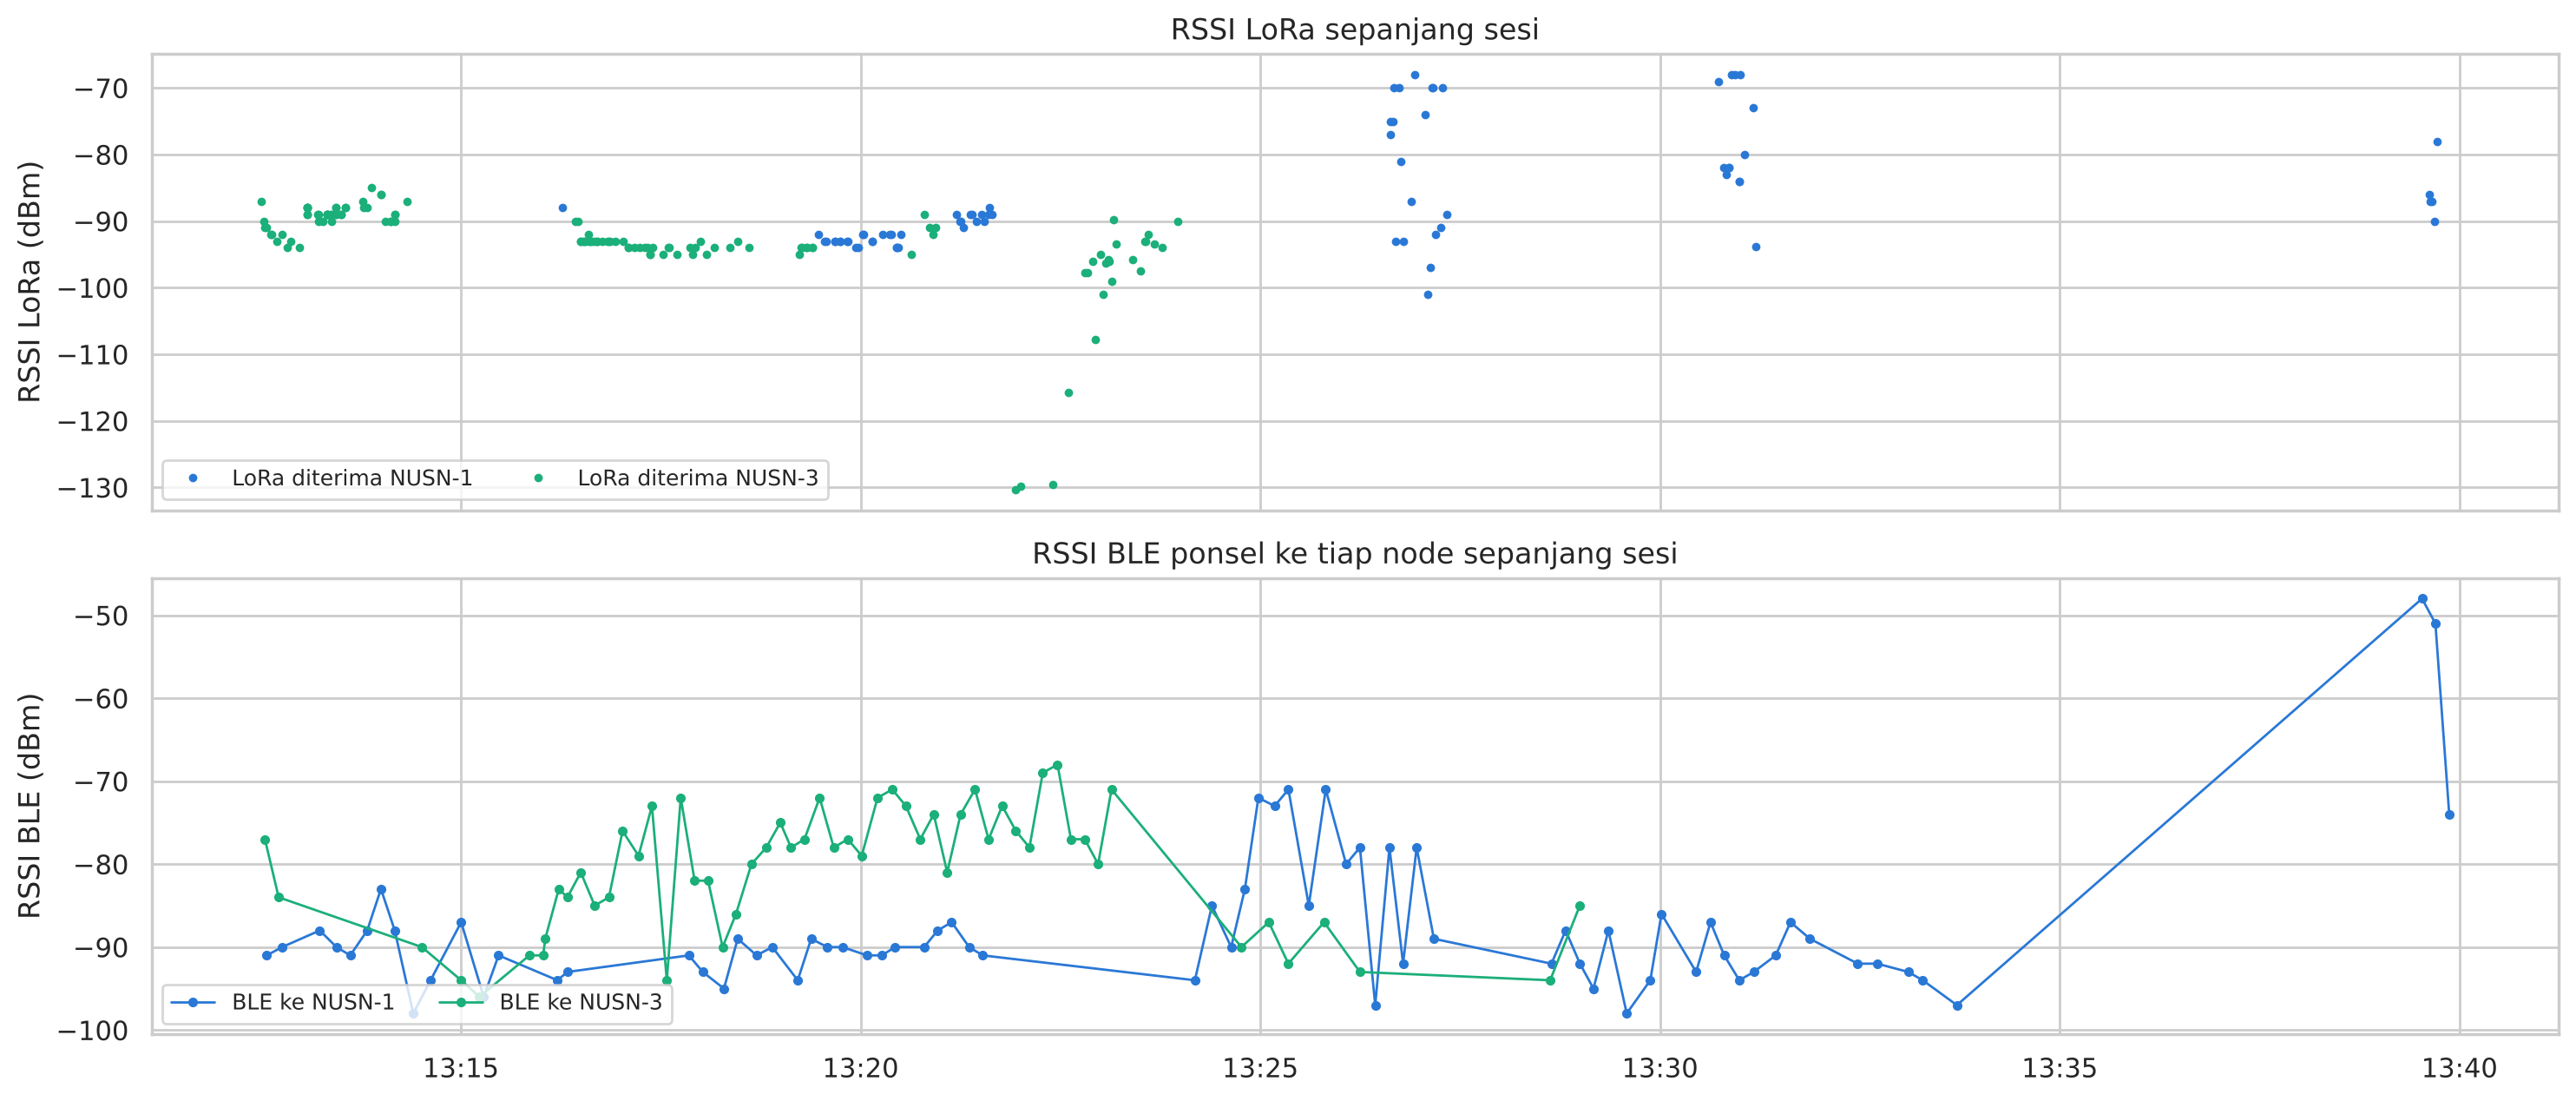

In [67]:
fig, axes = plt.subplots(2, 1, figsize=(15, 6.5), sharex=True)
for n in sorted(sinyal_cd2['node'].unique()):
    s = sinyal_cd2[sinyal_cd2['node'] == n].sort_values('waktu')
    axes[0].plot(s['waktu'], s['rssi_dbm'], '.', ms=5, color=WARNA_NODE[n], label=f'LoRa diterima {n}')
for n in sorted(tabel_rssi_ble.index):
    s = scan_ble[scan_ble['node'] == n].sort_values('waktu')
    axes[1].plot(s['waktu'], s['rssi_dbm'], '-o', ms=3, lw=1, color=WARNA_NODE[n], label=f'BLE ke {n}')
axes[0].set_ylabel('RSSI LoRa (dBm)'); axes[0].set_title('RSSI LoRa sepanjang sesi')
axes[1].set_ylabel('RSSI BLE (dBm)'); axes[1].set_title('RSSI BLE ponsel ke tiap node sepanjang sesi')
for ax in axes:
    ax.legend(loc='lower left', fontsize=9, ncol=3)
axes[1].xaxis.set_major_formatter(FORMAT_JAM)
plt.tight_layout(); plt.show()

**Interpretasi:**
- **RSSI LoRa** frame di node: NUSN-1 rata-rata **−85,9 dBm** (rentang −101 s/d −68 dBm), NUSN-3 **−93,9 dBm** (−130,3 s/d −85 dBm). Paket yang sampai ke ponsel: NUSN-1 −86,3 dBm dan NUSN-3 −91,3 dBm. Semua nilai masih di atas sensitivitas SF7 (−124 dBm), **kecuali 3 frame NUSN-3 pada 13:21:56–13:22:24** (±−130 dBm).
- **SNR** rata-rata 6,6–8,5 dB, terendah −9,0 dB (NUSN-3). Scatter menunjukkan pola wajar: SNR stabil di sekitar 9–10 dB saat sinyal kuat, lalu turun tajam saat RSSI melemah ke sekitar −100 dBm atau lebih rendah.
- **RSSI BLE:** ponsel ke NUSN-1 lemah (rata-rata **−87,8 dBm**), ke NUSN-3 lebih kuat (**−80,8 dBm**). Grafik waktu menunjukkan RSSI BLE ke NUSN-1 bertahan di sekitar −90 dBm hampir sepanjang sesi, lalu naik ke ±−58 dBm pada 13:39. Sinyal BLE ke NUSN-3 paling kuat pada 13:18–13:23 (±−75 dBm), lalu melemah dan hilang setelah 13:29. Ada juga 4 perangkat BLE lain yang ikut terpindai (24 kali).
- **Keterbatasan:** CD-2 meminta RSSI dan SNR **per jarak**. Log tidak mencatat jarak, jadi grafik RSSI vs jarak belum bisa dibuat.

## 9.2 PDR dan PLR (pendekatan per lapisan)

Definisi CD-2: PDR dihitung dari **paket uji bernomor** yang direncanakan, dicatat di ponsel penerima. Log ini belum punya paket uji (`test_mode=false`), jadi PDR dihitung **per lapisan** dari sisi pengirim sebagai pendekatan:

| Lapisan | Dikirim | Diterima |
|---|---|---|
| Tulis BLE (ponsel → node) | `TX_START` | `TX_ACCEPTED` |
| Pesan lokal (aplikasi → node) | pesan keluar | `MESSAGE_LOCAL_ACCEPTED` |
| Antrean node | frame masuk antrean | frame tidak dibuang (`dropped`) |
| Link LoRa (udara) | frame sampai ke radio | frame tanpa CRC error |
| End-to-end terkonfirmasi | pesan terkirim | pesan yang ACK-nya kembali (`ACK_MATCHED`) |

Baris terakhir adalah **batas bawah**: pesan tanpa ACK belum tentu hilang, karena belum dicocokkan dengan log ponsel penerima.

In [68]:
n_ack = int(pesan['ACK_MATCHED'].gt(0).sum())
pdr = pd.DataFrame({
    'dikirim':  [len(df[df['event'] == 'TX_START']), n_berhasil + n_gagal, total_tx + total_drop, total_rx + total_crc, n_berhasil],
    'diterima': [len(df[df['event'] == 'TX_ACCEPTED']), n_berhasil, total_tx, total_rx, n_ack],
}, index=['Tulis BLE (frame)', 'Pesan lokal (aplikasi -> node)', 'Antrean node (frame)',
          'Link LoRa / udara (frame)', 'End-to-end terkonfirmasi ACK (pesan)'])
pdr['PDR (%)'] = (pdr['diterima'] / pdr['dikirim'] * 100).round(2)
pdr['PLR (%)'] = (100 - pdr['PDR (%)']).round(2)
pdr

,dikirim,diterima,PDR (%),PLR (%)
Tulis BLE (frame),188.0,169.0,89.89,10.11
Pesan lokal (aplikasi -> node),61.0,41.0,67.21,32.79
Antrean node (frame),508.0,387.0,76.18,23.82
Link LoRa / udara (frame),450.0,436.0,96.89,3.11
End-to-end terkonfirmasi ACK (pesan),41.0,11.0,26.83,73.17


**Yang dilakukan cell berikut:**
- `(a)` PDR vs PLR per lapisan
- `(b)` PDR per menit: pesan lokal dan link LoRa

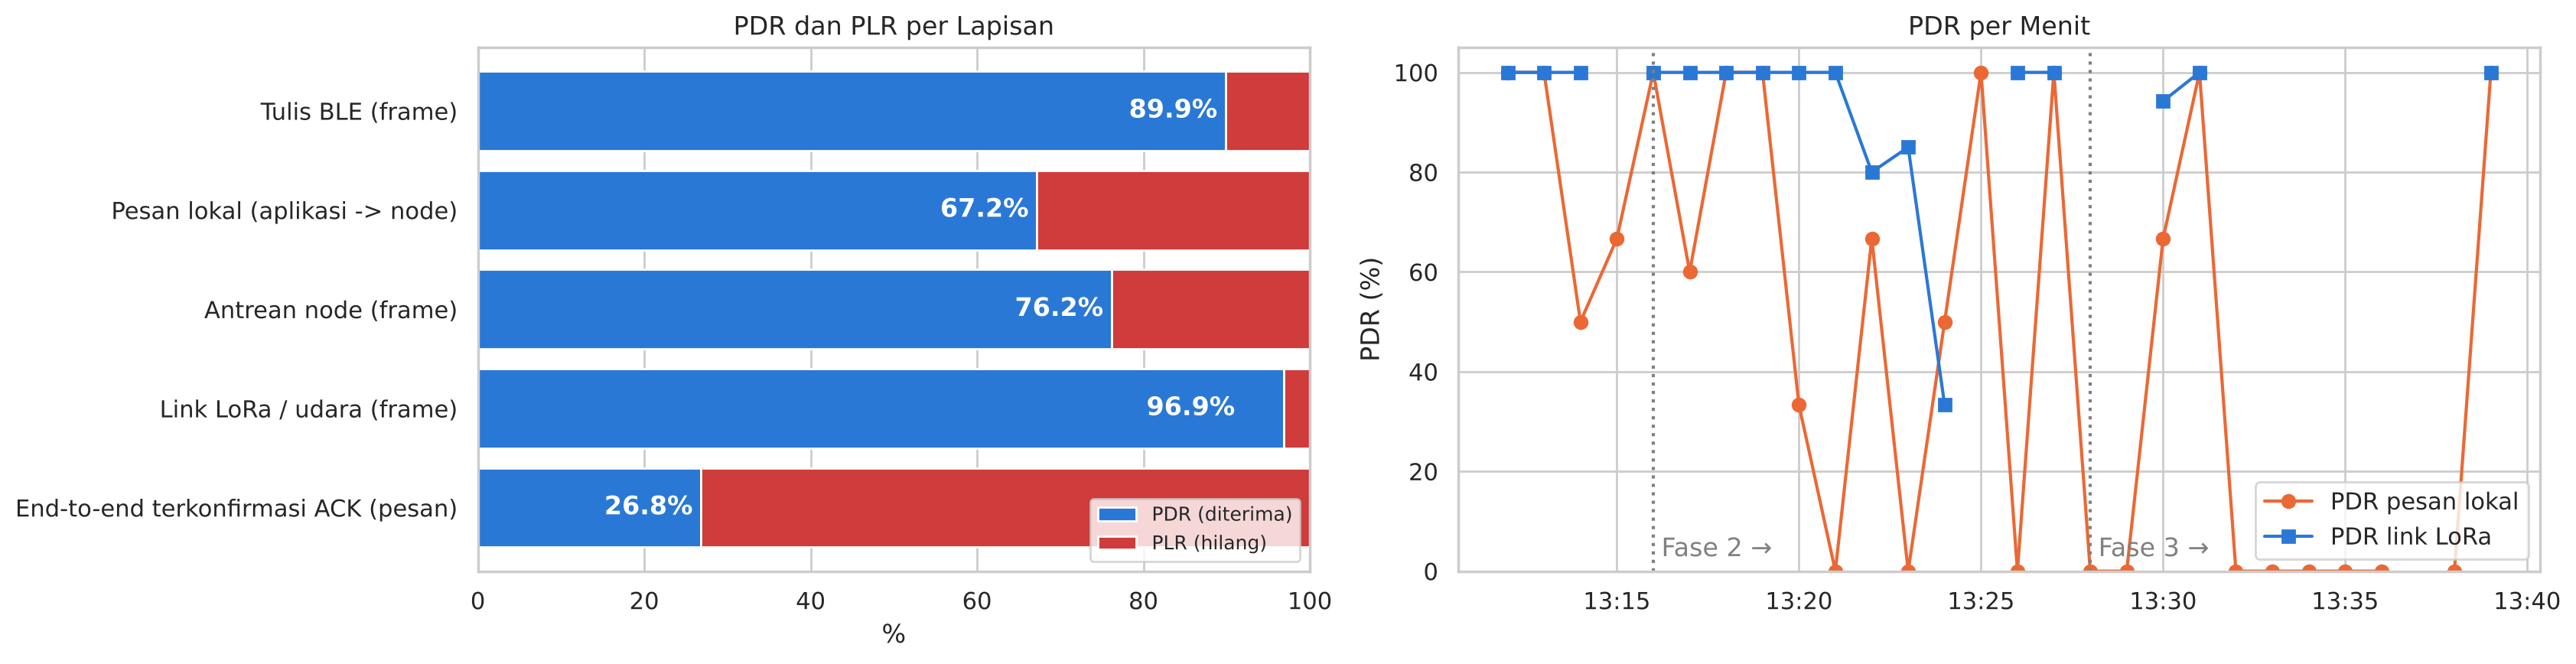

In [69]:
fig, axes = plt.subplots(1, 2, figsize=(17, 4.5), gridspec_kw={'width_ratios': [1, 1.3]})

p = pdr.iloc[::-1]
axes[0].barh(p.index, p['PDR (%)'], color='#2a78d6', label='PDR (diterima)')
axes[0].barh(p.index, p['PLR (%)'], left=p['PDR (%)'], color='#d03b3b', label='PLR (hilang)')
for i, v in enumerate(p['PDR (%)']):
    axes[0].text(min(v, 92) - 1, i, f'{v:.1f}%', va='center', ha='right', color='white', fontweight='bold')
axes[0].set_xlim(0, 100); axes[0].set_xlabel('%')
axes[0].set_title('PDR dan PLR per Lapisan'); axes[0].legend(loc='lower right', fontsize=9)

pesan_keluar_menit = pesan[pesan['arah'] == 'keluar'].set_index('waktu_mulai')
lokal = pesan_keluar_menit['MESSAGE_LOCAL_ACCEPTED'].gt(0).resample('1min').mean() * 100
link = health.set_index('waktu')[['tambah_rx', 'tambah_crc']].resample('1min').sum()
link = (link['tambah_rx'] / (link['tambah_rx'] + link['tambah_crc']) * 100)
axes[1].plot(lokal.index, lokal.values, '-o', color='#eb6834', label='PDR pesan lokal')
axes[1].plot(link.index, link.values, '-s', color='#2a78d6', label='PDR link LoRa')
for nama, (mulai, akhir) in FASE.items():
    if mulai is not None:
        axes[1].axvline(mulai, color='grey', ls=':', lw=1.5)
        axes[1].text(mulai, 3, ' ' + nama.split(' (')[0] + ' →', color='grey')
axes[1].set_ylim(0, 105); axes[1].set_ylabel('PDR (%)')
axes[1].xaxis.set_major_formatter(FORMAT_JAM)
axes[1].set_title('PDR per Menit'); axes[1].legend(loc='lower right')
plt.tight_layout(); plt.show()

**Interpretasi:**
- PDR tiap lapisan: **link LoRa 96,9%**, **BLE 89,9%**, **antrean node 76,2%**, dan **pesan lokal 67,2%**. Paket paling banyak hilang di **antara aplikasi dan node** serta di **antrean node**, bukan di udara.
- Grafik per menit memperjelas penyebabnya. PDR pesan lokal naik-turun di Fase 1–2 (0–100%), lalu hampir selalu **0% pada 13:32–13:38** (Fase 3) saat HP tidak bisa terhubung ke NUSN-1.
- PDR link LoRa stabil di **±100%**, kecuali turun pada 13:22–13:24 saat sinyal NUSN-3 jatuh.
- **PDR end-to-end terkonfirmasi ACK 26,8%** (11 dari 41). Ini **batas bawah**, bukan PDR sebenarnya: tidak semua pesan meminta ACK (jenis pesan dan tujuannya tidak tercatat di log), dan log ponsel penerima tidak tersedia.
- **Keterbatasan:** PDR versi CD-2 butuh paket uji bernomor dan jumlah paket yang direncanakan. Angka di sini adalah **pendekatan**.

## 9.3 Penerusan Pesan (Hop) dan Pesan Tampil Satu Kali

CD-2 menguji pengiriman **langsung (1 hop)** dan **melalui satu node perantara (2 hop)**, serta memastikan pesan **ditampilkan satu kali**.

Log tidak mencatat jumlah hop secara langsung. Hop ditaksir dari TTL: setiap kali paket diteruskan, TTL berkurang 1. TTL awal tiap tipe paket diasumsikan sama dengan **TTL terbesar yang teramati** untuk tipe itu. Paket kontrol ber-TTL 1 (beacon tipe 24, tipe 49, tipe 65) tidak diteruskan, jadi tidak dihitung.

**Yang dilakukan cell berikut:**
- Node NusaMesh -> NUSN-n, ID lain (pengguna/ponsel) -> HP-xxxx
- `paket_data`: hanya tipe yang bisa diteruskan

In [70]:
def label_pengirim(x):
    n = nama_node(x)
    return n if isinstance(n, str) and n.startswith('NUSN') else f'HP-{str(x)[:4]}'

paket = df[df['event'] == 'RX_PACKET'].dropna(subset=['type', 'ttl']).copy()
ttl_awal = paket.groupby('type')['ttl'].max()
paket_data = paket[paket['type'].map(ttl_awal) > 1].copy()
paket_data['ttl_awal'] = paket_data['type'].map(ttl_awal)
paket_data['hop'] = (paket_data['ttl_awal'] - paket_data['ttl'] + 1).astype(int)
paket_data['pengirim'] = paket_data['sender'].apply(label_pengirim)
paket_data['diterima_lewat'] = paket_data['device_id'].map(mac_ke_node).fillna('MAC lain')

print('TTL awal per tipe paket :', ttl_awal.astype(int).to_dict())
print(f'Paket data yang dianalisis: {len(paket_data)}')
tabel_hop = pd.crosstab(paket_data['type'].astype(int), paket_data['hop'], margins=True, margins_name='Total')
tabel_hop.columns = [f'{c} hop' if c != 'Total' else c for c in tabel_hop.columns]
tabel_hop

TTL awal per tipe paket : {1.0: 3, 4.0: 7, 5.0: 7, 6.0: 7, 7.0: 7, 10.0: 7, 14.0: 7, 24.0: 1, 34.0: 7, 49.0: 1, 65.0: 1}
Paket data yang dianalisis: 168


,1 hop,2 hop,Total
type,,,
1,76,21,97
4,21,5,26
5,3,0,3
6,5,0,5
7,3,0,3
10,19,1,20
14,11,1,12
34,2,0,2
Total,140,28,168


**Yang dilakukan cell berikut:**
- Pesan tampil satu kali: cek duplikat pada pesan yang diterima aplikasi

In [71]:
pesan_masuk = df[df['event'] == 'MESSAGE_RECEIVED']
tabel_dup = pd.Series({
    'Paket mesh diterima (RX_PACKET)': len(df[df['event'] == 'RX_PACKET']),
    'Paket duplikat disaring (RX_DUPLICATE)': len(df[df['event'] == 'RX_DUPLICATE']),
    'Paket milik sendiri disaring (RX_GUARD_DROP)': len(df[df['event'] == 'RX_GUARD_DROP']),
    'Paket diteruskan (RELAYED)': len(df[df['event'] == 'RELAYED']),
    'Pesan tampil di aplikasi (MESSAGE_RECEIVED)': len(pesan_masuk),
    'message_id unik yang tampil': pesan_masuk['message_id'].nunique(),
    'Pesan tampil lebih dari sekali': int(pesan_masuk['message_id'].duplicated().sum()),
}, name='jumlah').to_frame()
tabel_dup

,jumlah
Paket mesh diterima (RX_PACKET),596
Paket duplikat disaring (RX_DUPLICATE),83
Paket milik sendiri disaring (RX_GUARD_DROP),36
Paket diteruskan (RELAYED),147
Pesan tampil di aplikasi (MESSAGE_RECEIVED),26
message_id unik yang tampil,26
Pesan tampil lebih dari sekali,0


**Yang dilakukan cell berikut:**
- `(a)` Distribusi hop
- `(b)` Matriks pengirim asal -> node yang menyerahkan ke ponsel

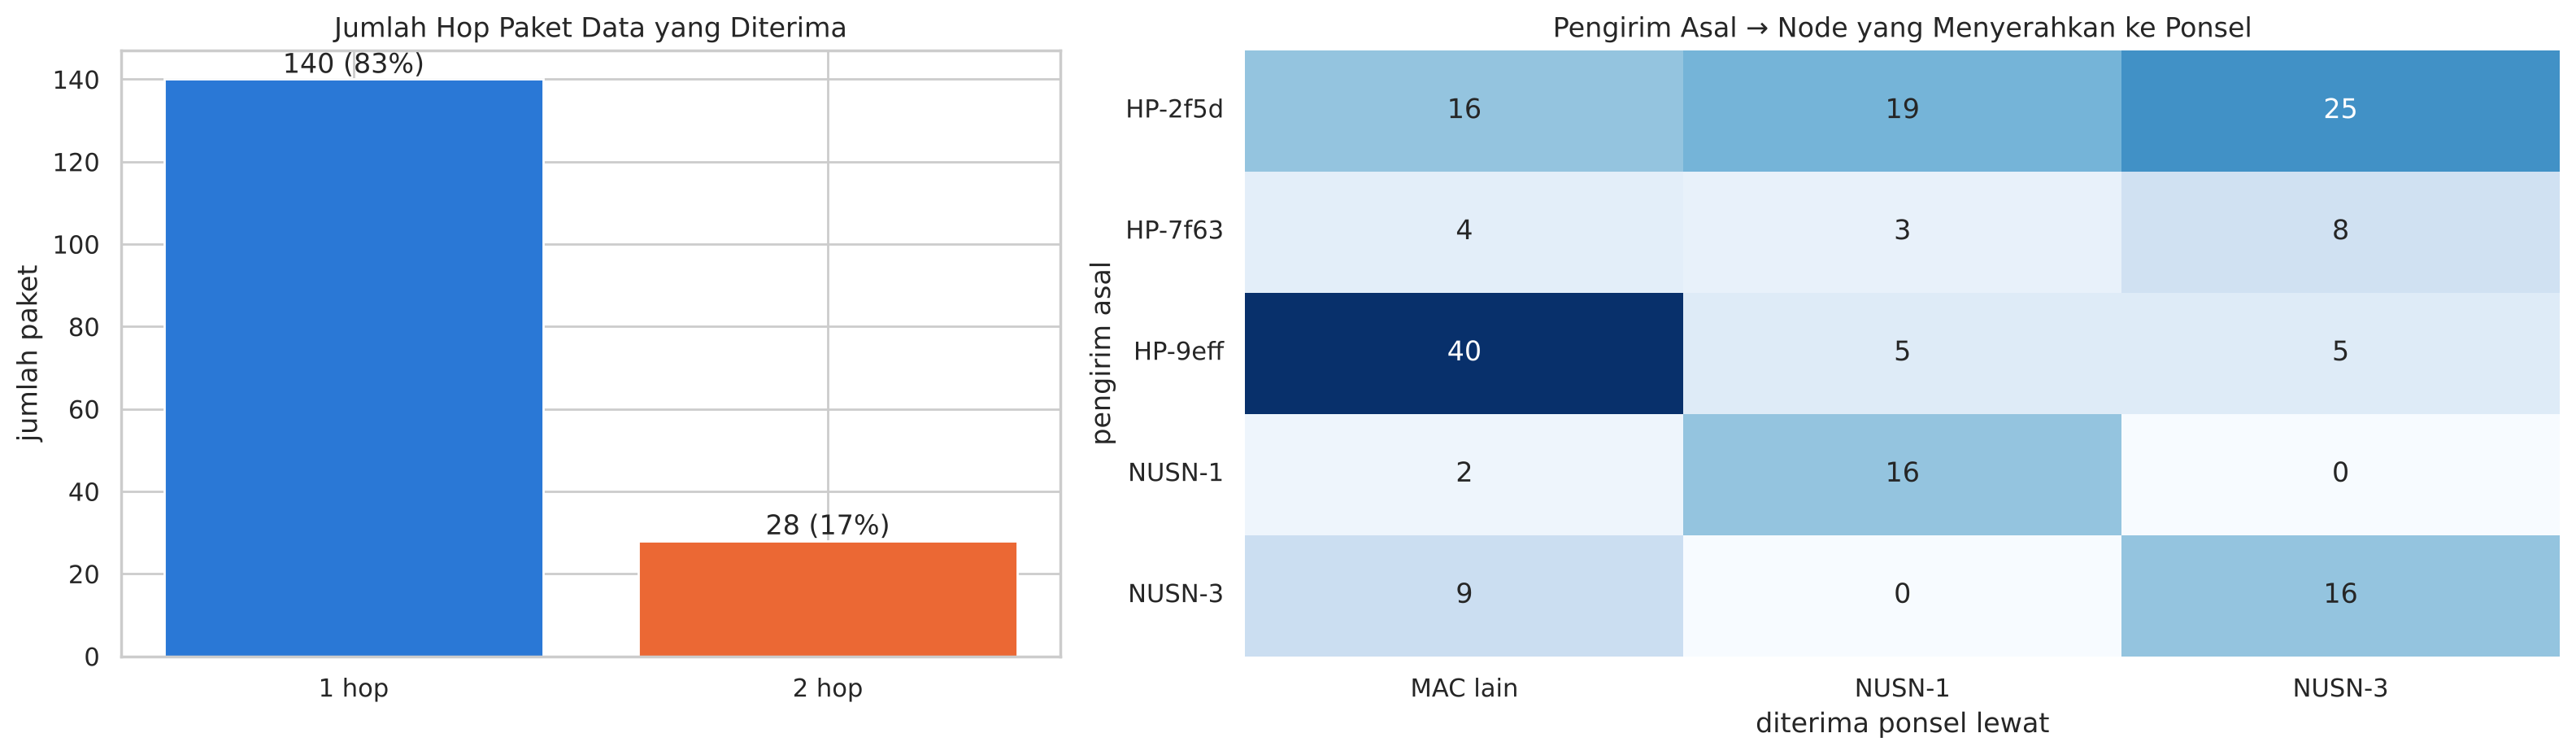

In [72]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={'width_ratios': [1, 1.4]})

hop_hitung = paket_data['hop'].value_counts().sort_index()
b = axes[0].bar([f'{h} hop' for h in hop_hitung.index], hop_hitung.values, color=['#2a78d6', '#eb6834', '#1baf7a'][:len(hop_hitung)])
axes[0].bar_label(b, labels=[f'{v} ({v / hop_hitung.sum() * 100:.0f}%)' for v in hop_hitung.values])
axes[0].set_title('Jumlah Hop Paket Data yang Diterima'); axes[0].set_ylabel('jumlah paket')

matriks = pd.crosstab(paket_data['pengirim'], paket_data['diterima_lewat'])
sns.heatmap(matriks, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[1])
axes[1].set_title('Pengirim Asal → Node yang Menyerahkan ke Ponsel')
axes[1].set_xlabel('diterima ponsel lewat'); axes[1].set_ylabel('pengirim asal')
axes[1].tick_params(axis='y', rotation=0)
plt.tight_layout(); plt.show()

**Interpretasi:**
- Dari 168 paket data, **140 (83%) diterima langsung (1 hop)** dan **28 (17%) lewat satu node perantara (2 hop)**. Jadi mekanisme penerusan mesh **sudah berjalan**. Tidak ada paket 3 hop.
- Heatmap menunjukkan pesan dari pengguna lain (HP-xxxx) sampai ke ponsel ini lewat NUSN-1, NUSN-3, maupun **MAC lain**. Pengirim HP-9eff paling banyak lewat MAC lain (40 paket). MAC lain adalah alamat BLE yang tidak bisa dipetakan ke node mana pun. Hal ini menjadi salah satu saran logging (ID node yang konsisten).
- **Pesan tampil satu kali: terpenuhi.** 83 paket duplikat dan 36 paket milik sendiri berhasil disaring. 26 pesan yang tampil di aplikasi semuanya punya `message_id` unik (**0 pesan tampil dobel**).
- **Keterbatasan:** hop ditaksir dari TTL, dan skenario A→B→C tidak dibuat dengan sengaja. Jadi PDR dan delay 1 hop vs 2 hop belum bisa dibandingkan.

## 9.4 Airtime dan Duty Cycle

CD-2 membatasi waktu pancar tiap perangkat **5% selama pengujian (≈180 s/jam)** dan **1% pada penggunaan sebenarnya (36 s/jam)**. Node tidak merekam airtime per frame, sehingga (sesuai CD-2) airtime dihitung dari **jumlah frame yang dipancarkan × airtime per frame**.

Jumlah frame diambil dari kenaikan counter `tx` pada `NODE_HEALTH`. Ukuran frame yang dipancarkan tiap node tidak tercatat, jadi airtime per frame ditaksir dengan tiga skenario dari ukuran paket mesh yang teramati:
- **Rendah**: semua frame berupa beacon (62 byte).
- **Tengah**: campuran beacon dan data seperti yang teramati di jaringan (rata-rata ToA semua paket diterima).
- **Tinggi**: semua frame berupa paket data (rata-rata ToA paket non-beacon).

In [73]:
ukuran_paket = df.loc[df['event'] == 'RX_PACKET', ['type', 'bytes']].dropna().astype(float)
toa_skenario = {
    'rendah (beacon)': time_on_air_ms(62),
    'tengah (campuran)': ukuran_paket['bytes'].map(time_on_air_ms).mean(),
    'tinggi (data)': ukuran_paket.loc[ukuran_paket['type'] != 24, 'bytes'].map(time_on_air_ms).mean(),
}
print('Airtime per frame (ms):', {k: round(v, 1) for k, v in toa_skenario.items()})

amati = health.groupby('node').agg(frame_tx=('tambah_tx', 'sum'), lama_amat_s=('jeda_detik', 'sum'))
for k, v in toa_skenario.items():
    amati[f'duty_{k} (%)'] = (amati['frame_tx'] * v / 1000 / amati['lama_amat_s'] * 100).round(2)
amati['airtime_per_jam_tengah (s)'] = (amati['duty_tengah (campuran) (%)'] / 100 * 3600).round(1)
amati['budget_terendah_ms'] = health.groupby('node')['budget_ms'].min()
duty_cycle = amati
duty_cycle

Airtime per frame (ms): {'rendah (beacon)': np.float64(118.0), 'tengah (campuran)': np.float64(168.8), 'tinggi (data)': np.float64(252.5)}


,frame_tx,lama_amat_s,duty_rendah (beacon) (%),duty_tengah (campuran) (%),duty_tinggi (data) (%),airtime_per_jam_tengah (s),budget_terendah_ms
node,,,,,,,
NUSN-1,193.0,1412.815,1.61,2.31,3.45,83.2,15.0
NUSN-3,194.0,694.291,3.30,4.72,7.05,169.9,20.0


**Yang dilakukan cell berikut:**
- `(a)` Duty cycle per node dengan rentang skenario
- `(b)` Sisa budget airtime yang dilaporkan node

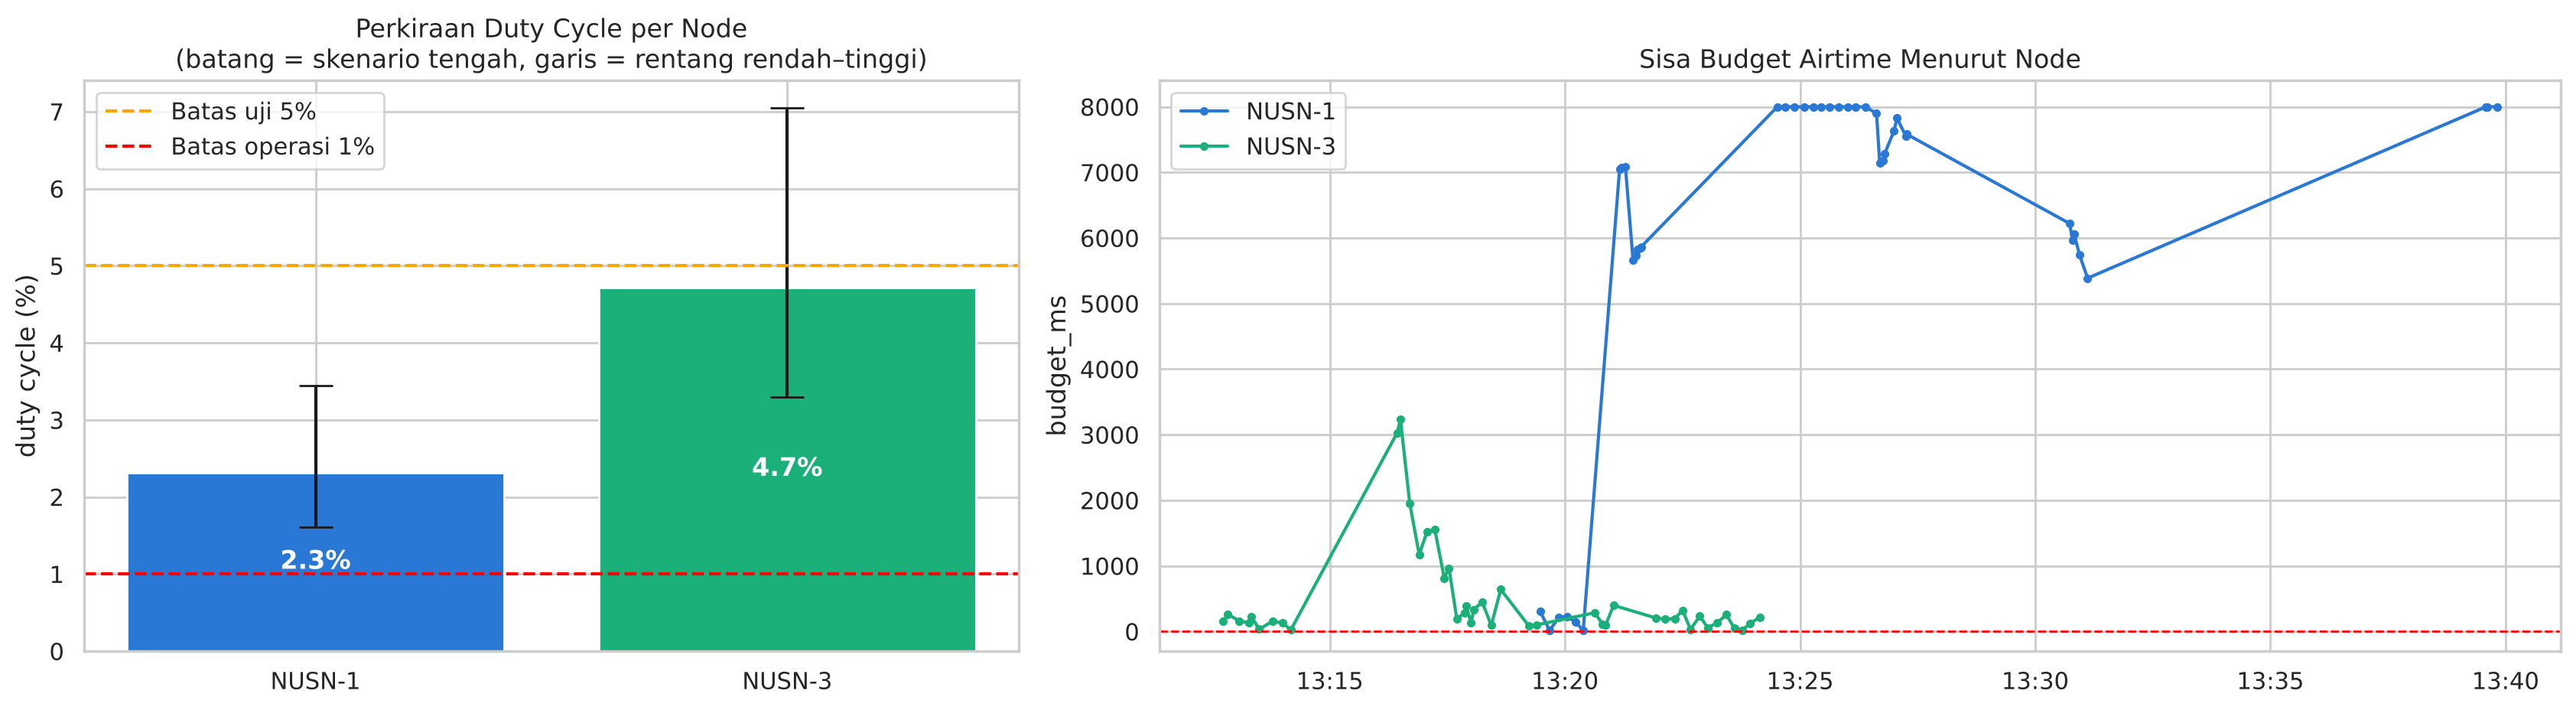

In [74]:
fig, axes = plt.subplots(1, 2, figsize=(17, 4.8), gridspec_kw={'width_ratios': [1, 1.5]})

d = duty_cycle[duty_cycle['frame_tx'] > 0]
tengah = d['duty_tengah (campuran) (%)']
err = [tengah - d['duty_rendah (beacon) (%)'], d['duty_tinggi (data) (%)'] - tengah]
b = axes[0].bar(d.index, tengah, yerr=err, capsize=8, color=[WARNA_NODE[n] for n in d.index])
axes[0].bar_label(b, labels=[f'{v:.1f}%' for v in tengah], label_type='center', color='white', fontweight='bold')
axes[0].axhline(5, color='orange', ls='--', label='Batas uji 5%')
axes[0].axhline(1, color='red', ls='--', label='Batas operasi 1%')
axes[0].set_ylabel('duty cycle (%)'); axes[0].legend()
axes[0].set_title('Perkiraan Duty Cycle per Node\n(batang = skenario tengah, garis = rentang rendah–tinggi)')

for n in sorted(health['node'].unique()):
    h = health[health['node'] == n]
    axes[1].plot(h['waktu'], h['budget_ms'], '-o', ms=3, color=WARNA_NODE[n], label=n)
axes[1].axhline(0, color='red', ls='--', lw=1)
axes[1].set_ylim(bottom=-300)
axes[1].set_ylabel('budget_ms'); axes[1].xaxis.set_major_formatter(FORMAT_JAM)
axes[1].set_title('Sisa Budget Airtime Menurut Node'); axes[1].legend()
plt.tight_layout(); plt.show()

**Interpretasi:**
- Perkiraan duty cycle skenario tengah: **NUSN-1 ±2,3%** (±83 s/jam) dan **NUSN-3 ±4,7%** (±170 s/jam). Rentangnya 1,6–7,1% tergantung ukuran frame yang sebenarnya.
- Pada skenario tengah keduanya **masih di bawah batas uji 5%**, tetapi NUSN-3 sudah mepet dan bisa melewatinya di skenario tinggi (7,1%). Keduanya **jauh di atas batas operasi 1%** (36 s/jam).
- Budget airtime yang dihitung firmware **hampir habis** di kedua node (terendah 15 ms pada NUSN-1 dan 20 ms pada NUSN-3). NUSN-3 bertahan di bawah ±500 ms hampir sepanjang 13:12–13:24. Jadi pembatas airtime di node **benar-benar bekerja dan menahan kiriman**. Inilah penyebab antrean penuh dan frame dibuang (bagian 7.4).
- **Kesimpulan:** interval beacon dan laju relay perlu dikurangi agar memenuhi batas 1% dan agar budget tidak cepat habis. Firmware juga perlu mencatat airtime per frame supaya duty cycle bisa diukur pasti, bukan hanya diperkirakan.

## 9.5 Penggunaan Ponsel per Node dan Perpindahan Pengguna

CD-2: satu node melayani **tiga ponsel** bersamaan. Saat pengguna pindah node, identitas dan riwayat pesan tetap ada, dan dicatat **lama perpindahan** serta **pesan yang tertunda/gagal**.

- Jumlah pengguna per node diambil dari field `users` pada `MOBILITY_REGISTERED`/`MOBILITY_SUCCESS` (format `a/b`).
- Jendela handover = dari `waktu − duration_ms` sampai `MOBILITY_SUCCESS`.

In [75]:
mob = df[df['event'].isin(['MOBILITY_REGISTERED', 'MOBILITY_SUCCESS']) & df['users'].notna()].copy()
mob['node'] = mob['to'].apply(nama_node)
mob[['pengguna', 'kapasitas']] = mob['users'].str.split('/', expand=True).astype(int)
pengguna_node = mob.groupby('node').agg(laporan=('pengguna', 'size'), pengguna_maks=('pengguna', 'max'),
                                         nilai_b_maks=('kapasitas', 'max'))
pengguna_node['target_CD2'] = 3
pengguna_node

,laporan,pengguna_maks,nilai_b_maks,target_CD2
node,,,,
NUSN-1,9,2,3,3
NUSN-3,12,2,3,3


**Yang dilakukan cell berikut:**
- Pesan yang dikirim selama jendela handover

In [76]:
ho = handover.copy()
ho['mulai'] = ho['waktu'] - pd.to_timedelta(ho['duration_ms'].astype(float), unit='ms')
keluar = pesan[pesan['arah'] == 'keluar']
rekap = []
for _, r in ho.iterrows():
    dalam = keluar[(keluar['waktu_mulai'] >= r['mulai']) & (keluar['waktu_mulai'] <= r['waktu'])]
    rekap.append({'handover': f"{r['dari']} → {r['ke']}", 'lama_detik': r['lama_detik'],
                  'pesan_dikirim_saat_handover': len(dalam),
                  'gagal': int((dalam['status'] == 'gagal').sum())})
handover_pesan = pd.DataFrame(rekap)
handover_pesan

,handover,lama_detik,pesan_dikirim_saat_handover,gagal
0,(belum terhubung) → NUSN-3,1.174,0,0
1,NUSN-1 → NUSN-3,0.780,0,0
2,(belum terhubung) → NUSN-3,1.526,0,0
3,NUSN-3 → NUSN-1,3.431,0,0
4,NUSN-1 → NUSN-3,2.403,0,0
5,NUSN-1 → NUSN-3,1.013,0,0
6,NUSN-3 → NUSN-1,5.914,0,0
7,(belum terhubung) → NUSN-1,4.924,0,0


**Yang dilakukan cell berikut:**
- `(a)` Garis waktu node yang melayani ponsel
- `(b)` Lama handover

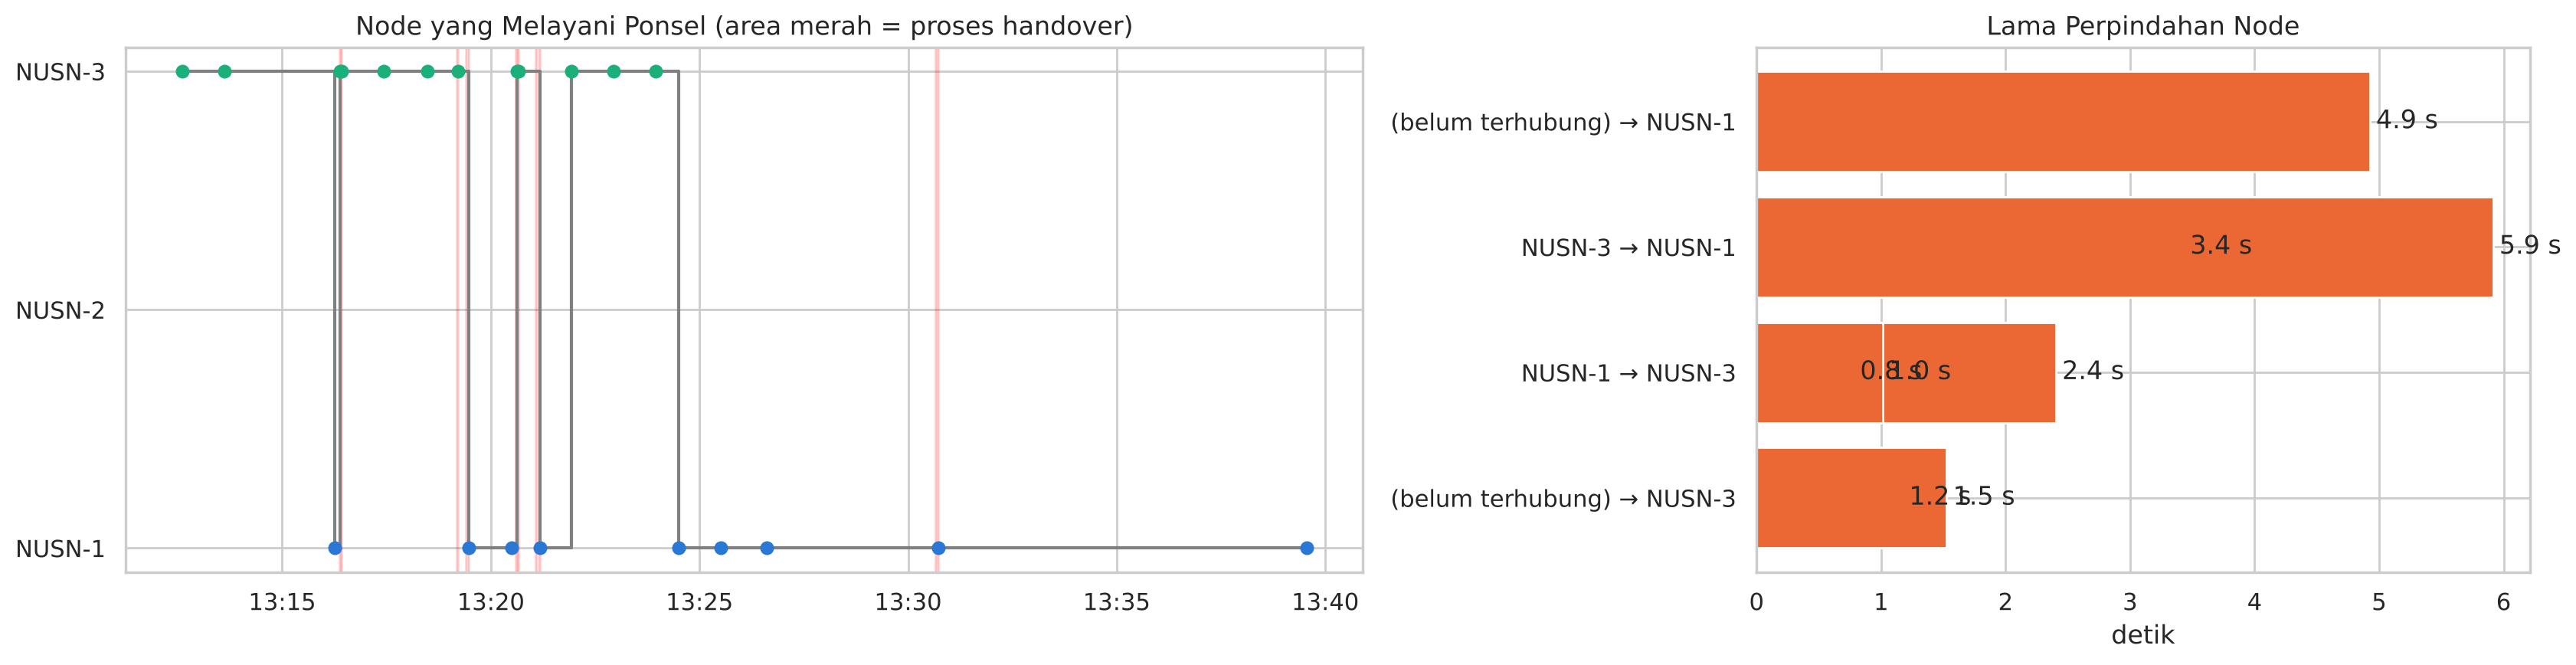

In [77]:
fig, axes = plt.subplots(1, 2, figsize=(17, 4.5), gridspec_kw={'width_ratios': [1.6, 1]})

layan = df[df['event'].isin(['MOBILITY_REGISTERED', 'MOBILITY_SUCCESS'])].copy()
layan['node'] = layan['to'].apply(nama_node)
layan = layan.dropna(subset=['node']).sort_values('waktu')
posisi = {n: i for i, n in enumerate(sorted(WARNA_NODE))}
axes[0].step(layan['waktu'], layan['node'].map(posisi), where='post', color='grey', lw=1.5)
for n in posisi:
    s = layan[layan['node'] == n]
    axes[0].scatter(s['waktu'], [posisi[n]] * len(s), color=WARNA_NODE[n], s=30, zorder=3)
for _, r in ho.iterrows():
    axes[0].axvspan(r['mulai'], r['waktu'], color='red', alpha=0.15)
axes[0].set_yticks(list(posisi.values()), list(posisi.keys()))
axes[0].xaxis.set_major_formatter(FORMAT_JAM)
axes[0].set_title('Node yang Melayani Ponsel (area merah = proses handover)')

b = axes[1].barh(handover_pesan['handover'], handover_pesan['lama_detik'], color='#eb6834')
axes[1].bar_label(b, labels=[f'{v:.1f} s' for v in handover_pesan['lama_detik']], padding=3)
axes[1].set_xlabel('detik'); axes[1].set_title('Lama Perpindahan Node')
plt.tight_layout(); plt.show()

**Interpretasi:**
- **Jumlah pengguna per node:** paling banyak **2 pengguna** (di NUSN-1 maupun NUSN-3). Skenario CD-2 **3 ponsel per node belum teruji**. Angka kedua pada `users=a/b` paling besar 3, kemungkinan kapasitas node, tetapi artinya belum terdokumentasi di logging.
- **Lama perpindahan node:** **0,8–5,9 detik** dari 8 kali handover. Yang paling lama adalah NUSN-3 → NUSN-1 pukul 13:21 (5,9 detik) dan sambungan ulang ke NUSN-1 pukul 13:30 (4,9 detik).
- **Pesan saat handover:** tidak ada pesan yang dikirim selama jendela handover, jadi tidak ada pesan yang tertunda/gagal karena handover.
- Garis waktu memperlihatkan ponsel dilayani NUSN-3 (13:12–13:16), lalu **bolak-balik NUSN-1 ↔ NUSN-3** (13:16–13:21), kembali ke NUSN-3 (13:21–13:24), lalu ke NUSN-1 sampai akhir sesi.
- **Keterbatasan:** `serving_rssi` selalu null, jadi RSSI BLE saat handover (yang diminta CD-2) tidak tercatat.

## 9.6 Jenis dan Ukuran Pesan

CD-2: pesan berupa **teks, rekaman suara ≤ 5 s, gambar ≤ 1.200 byte, dan lokasi**, dengan teks/SOS didahulukan. Log hanya membedakan **pesan** (`MESSAGE_*`) dan **file** (`FILE_*`). Jenis file (suara/gambar) dan pesan lokasi tidak tercatat, sehingga yang bisa dilihat adalah jumlah, ukuran, dan airtime-nya.

In [78]:
pesan_teks_keluar = pesan[(pesan['arah'] == 'keluar') & ~pesan.index.str.startswith('file-')]
file_keluar = df[df['event'] == 'FILE_SUBMITTED']
tabel_jenis = pd.DataFrame({
    'jumlah': [len(pesan_teks_keluar), len(pesan_masuk), len(file_keluar),
               len(df[df['event'] == 'FILE_RECEIVED'])],
    'ukuran_rata2_byte': [np.nan, pesan_masuk['bytes'].astype(float).mean(),
                          file_keluar['bytes'].astype(float).mean(),
                          df.loc[df['event'] == 'REASSEMBLED', 'bytes'].astype(float).mean()],
}, index=['Teks keluar', 'Teks masuk', 'File keluar', 'File masuk']).round(1)
print('Permintaan fragmen ulang (FRAGMENT_NACK_TX):', len(df[df['event'] == 'FRAGMENT_NACK_TX']),
      '| total fragmen hilang yang diminta:', int(df.loc[df['event'] == 'FRAGMENT_NACK_TX', 'detail']
                                                  .str.extract(r'missing=(\d+)')[0].astype(float).sum()))
tabel_jenis

Permintaan fragmen ulang (FRAGMENT_NACK_TX): 8 | total fragmen hilang yang diminta: 24


,jumlah,ukuran_rata2_byte
Teks keluar,56,NaN
Teks masuk,26,123.1
File keluar,7,1486.3
File masuk,3,2037.0


**Yang dilakukan cell berikut:**
- `(a)` Ukuran pesan masuk vs batas
- `(b)` Tipe paket mesh yang beredar

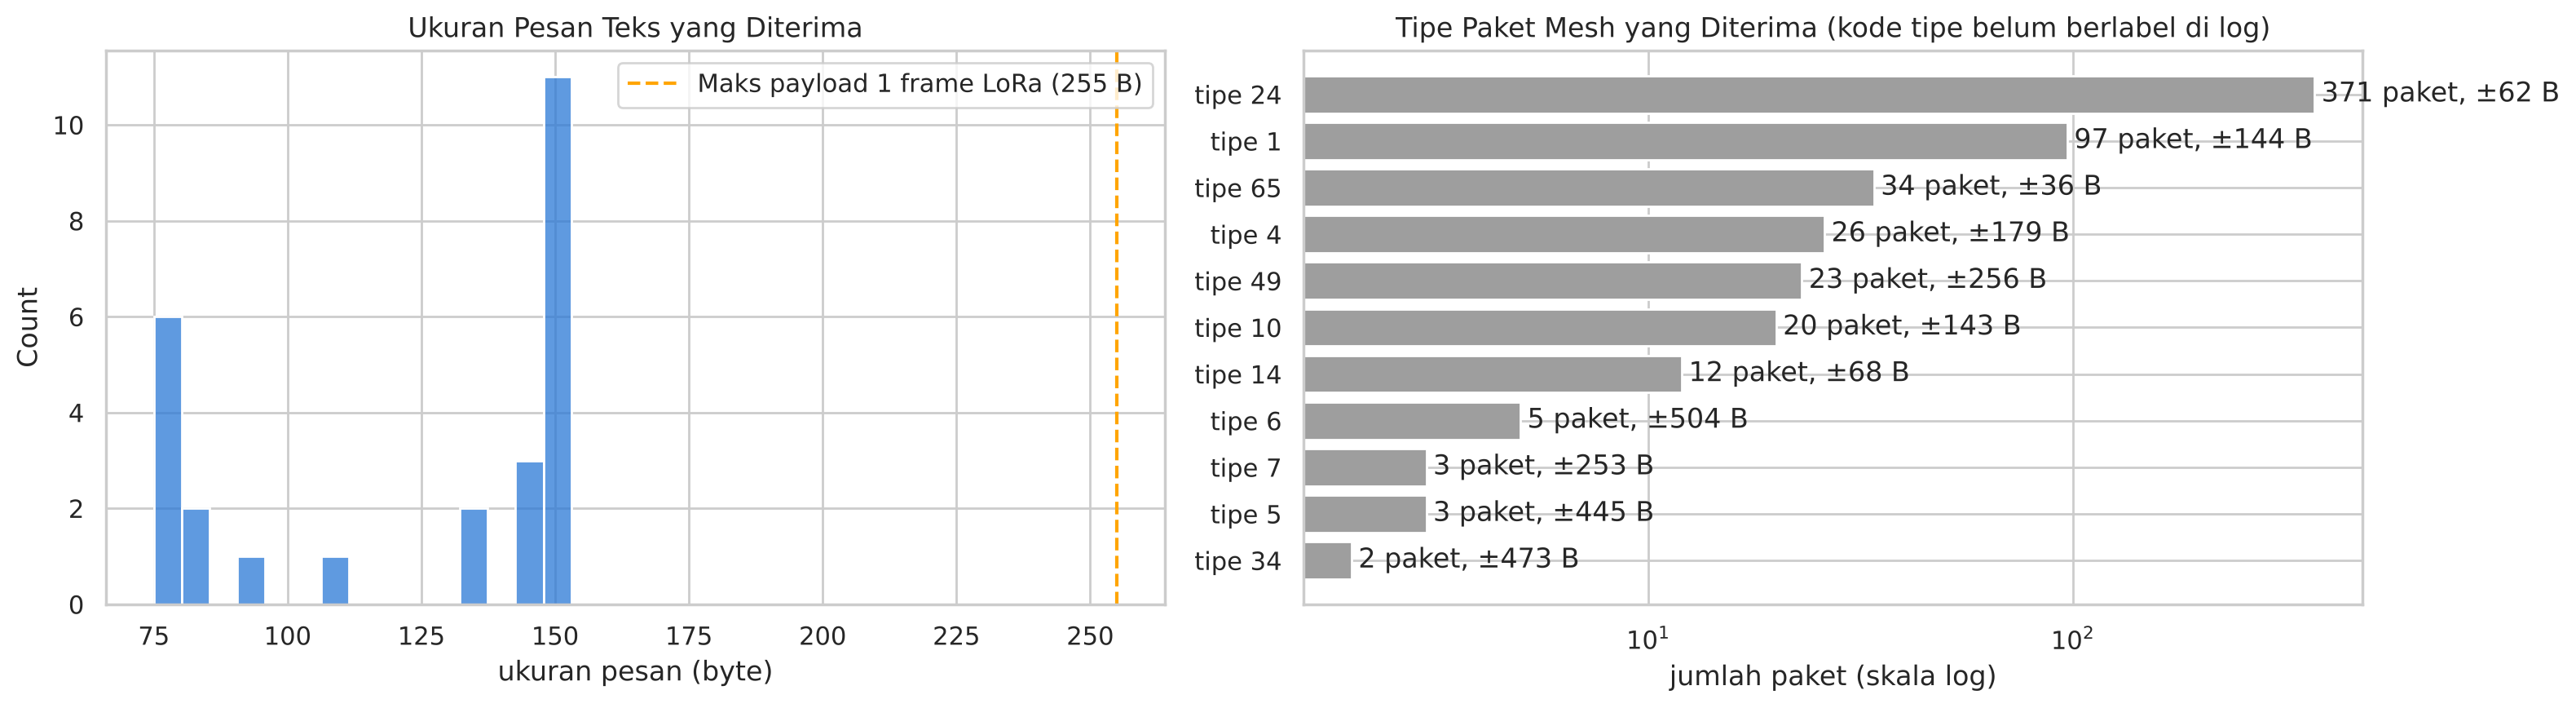

In [79]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))

sns.histplot(pesan_masuk['bytes'].astype(float), bins=15, color='#2a78d6', ax=axes[0])
axes[0].axvline(255, color='orange', ls='--', label='Maks payload 1 frame LoRa (255 B)')
axes[0].set_xlabel('ukuran pesan (byte)'); axes[0].set_title('Ukuran Pesan Teks yang Diterima')
axes[0].legend()

tipe = df[df['event'] == 'RX_PACKET'].groupby('type').agg(jumlah=('bytes', 'size'), ukuran=('bytes', 'mean'))
tipe.index = [f'tipe {int(t)}' for t in tipe.index]
tipe = tipe.sort_values('jumlah')
b = axes[1].barh(tipe.index, tipe['jumlah'], color='#9e9e9e')
axes[1].bar_label(b, labels=[f'{j} paket, ±{u:.0f} B' for j, u in zip(tipe['jumlah'], tipe['ukuran'])], padding=3)
axes[1].set_xscale('log'); axes[1].set_xlabel('jumlah paket (skala log)')
axes[1].set_title('Tipe Paket Mesh yang Diterima (kode tipe belum berlabel di log)')
plt.tight_layout(); plt.show()

**Interpretasi:**
- Teks masuk berukuran **75–153 byte** (rata-rata 123 byte). Semuanya di bawah 255 byte, jadi **satu pesan teks = satu frame LoRa**.
- Ukuran teks keluar tidak bisa dihitung karena `TX_START` selalu mencatat 256 byte (ukuran frame BLE, bukan isi pesan).
- **File keluar (7 file)** berukuran 270–618 byte, **kecuali satu file berukuran 7.926 byte** (13:17:50) yang **di atas batas gambar CD-2 (1.200 byte)** dan statusnya tidak selesai. File masuk berukuran 360–1.986 byte. Satu file yang dirakit dari fragmen berukuran 2.037 byte, juga di atas 1.200 byte.
- Transfer file membutuhkan **8 permintaan ulang fragmen (24 fragmen hilang)**. Transfer data besar di mesh LoRa memang rawan, seperti yang disebut di CD-2.
- Paket mesh didominasi **beacon (tipe 24, 371 paket)**. Muncul kode tipe baru (**tipe 34**, 2 paket, ±473 byte). Kode tipe belum punya label di log, jadi jenis suara/gambar/lokasi dan prioritas teks belum bisa dinilai.

## 9.7 Konfigurasi Radio vs Spesifikasi CD-2

Pemeriksaan konfigurasi radio (Tabel 1.4, baris *Frekuensi dan daya pancar*) dicocokkan dengan nilai yang tercatat di log.

In [80]:
sf_log = sorted(df['sf'].dropna().astype(int).unique().tolist())
bw_log = sorted(df['detail'].str.extract(r'bw_khz=([\d.]+)')[0].dropna().astype(float).unique().tolist())
mtu_log = sorted(df['detail'].str.extract(r'mtu=(\d+)')[0].dropna().astype(int).unique().tolist())
dual = df['dual_radio'].dropna().astype(str).str.lower().unique().tolist()
dc_maks = duty_cycle['duty_tengah (campuran) (%)'].max()

konfigurasi = pd.DataFrame([
    ['Frekuensi', '921,0 MHz (920–923 MHz)', 'tidak tercatat', 'tidak bisa dicek'],
    ['Lebar pita', '125 kHz', f'{bw_log} kHz', 'sesuai' if bw_log == [125.0] else 'cek'],
    ['Spreading factor', 'SF7', f'SF{sf_log}', 'sesuai' if sf_log == [7] else 'cek'],
    ['Daya pancar radio', '14 dBm', 'tidak tercatat', 'tidak bisa dicek'],
    ['EIRP', '≤ 20 dBm', 'tidak tercatat (butuh daya + gain antena)', 'tidak bisa dicek'],
    ['Duty cycle uji', '≤ 5%', f'±{dc_maks:.1f}% (perkiraan, node tersibuk)', 'sesuai' if dc_maks <= 5 else 'melebihi'],
    ['Media transmisi', 'half duplex', f'dual_radio = {dual}', 'sesuai' if dual == ['false'] else 'cek'],
    ['BLE MTU', '-', f'{mtu_log} byte', 'info'],
], columns=['item', 'spesifikasi CD-2', 'nilai di log', 'status'])
konfigurasi

,item,spesifikasi CD-2,nilai di log,status
0,Frekuensi,"921,0 MHz (920–923 MHz)",tidak tercatat,tidak bisa dicek
1,Lebar pita,125 kHz,[125.0] kHz,sesuai
2,Spreading factor,SF7,SF[7],sesuai
3,Daya pancar radio,14 dBm,tidak tercatat,tidak bisa dicek
4,EIRP,≤ 20 dBm,tidak tercatat (butuh daya + gain antena),tidak bisa dicek
5,Duty cycle uji,≤ 5%,"±4.7% (perkiraan, node tersibuk)",sesuai
6,Media transmisi,half duplex,dual_radio = ['false'],sesuai
7,BLE MTU,-,[517] byte,info


**Interpretasi:**
- **Sesuai spesifikasi:** SF7, lebar pita 125 kHz, mode half duplex (`dual_radio=false`), dan perkiraan duty cycle node tersibuk **±4,7%**, masih di bawah batas uji 5%. Catatan: angka duty cycle ini masih perkiraan (lihat 9.4).
- **Tidak bisa dicek dari log:** frekuensi (921 MHz), daya pancar (14 dBm), dan EIRP (≤ 20 dBm). Ketiganya harus dicatat firmware saat boot atau diperiksa manual dengan alat ukur.
- BLE MTU tercatat **517 byte**.

## 9.8 Matriks Status Parameter CD-2

Rekap semua parameter Tabel 1.3/1.4: mana yang **terukur penuh**, **terukur sebagian/pendekatan**, dan **tidak ada di log**.

In [81]:
STATUS = {2: 'Terukur', 1: 'Sebagian / pendekatan', 0: 'Tidak ada di log'}
matriks_cd2 = pd.DataFrame([
    ['RSSI LoRa', 1, 'rata-rata/min/maks ada, tapi tanpa jarak', '9.1'],
    ['RSSI BLE', 2, 'dari RSSI_SCAN per node', '9.1'],
    ['SNR', 1, 'ada, tapi tanpa jarak & kondisi penghalang', '9.1'],
    ['PDR / PLR', 1, 'per lapisan dari sisi pengirim, belum paket uji bernomor', '9.2'],
    ['Throughput BLE & LoRa', 1, 'ada, tapi bukan dari log penerima', '8.2'],
    ['Delay end-to-end', 1, 'hanya delay sisi pengirim, jam belum sinkron', '8.4'],
    ['Airtime & duty cycle', 1, 'ditaksir dari jumlah frame × ukuran rata-rata', '9.4'],
    ['Penerusan 1 hop vs 2 hop', 1, 'hop ditaksir dari TTL, skenario A→B→C tidak terkontrol', '9.3'],
    ['Pesan tampil satu kali', 2, 'dicek dari message_id pesan masuk', '9.3'],
    ['Lama perpindahan node', 2, 'dari MOBILITY_SUCCESS', '9.5'],
    ['Pesan tertunda saat handover', 1, 'dari jendela handover', '9.5'],
    ['3 ponsel per node', 1, 'baru teramati 2 pengguna', '9.5'],
    ['Jenis pesan & prioritas', 1, 'teks vs file saja, prioritas tidak tercatat', '9.6'],
    ['Frekuensi, daya, EIRP', 0, 'hanya SF & BW yang tercatat', '9.7'],
    ['Jarak komunikasi', 0, 'tidak dicatat', '-'],
    ['Kondisi penghalang', 0, 'tidak dicatat', '-'],
    ['Waktu pengolahan Codec 2 / AI', 0, 'tidak dicatat', '-'],
    ['Kualitas suara / gambar (penilai)', 0, 'penilaian manual', '-'],
    ['Akurasi koordinat GPS', 0, 'tidak dicatat', '-'],
    ['Daya, energi, baterai, panel surya', 0, 'butuh alat ukur eksternal', '-'],
], columns=['parameter', 'skor', 'keterangan', 'bagian'])
matriks_cd2['status'] = matriks_cd2['skor'].map(STATUS)
matriks_cd2[['parameter', 'status', 'keterangan', 'bagian']]

,parameter,status,keterangan,bagian
0,RSSI LoRa,Sebagian / pendekatan,"rata-rata/min/maks ada, tapi tanpa jarak",9.1
1,RSSI BLE,Terukur,dari RSSI_SCAN per node,9.1
2,SNR,Sebagian / pendekatan,"ada, tapi tanpa jarak & kondisi penghalang",9.1
3,PDR / PLR,Sebagian / pendekatan,"per lapisan dari sisi pengirim, belum paket uj...",9.2
4,Throughput BLE & LoRa,Sebagian / pendekatan,"ada, tapi bukan dari log penerima",8.2
5,Delay end-to-end,Sebagian / pendekatan,"hanya delay sisi pengirim, jam belum sinkron",8.4
6,Airtime & duty cycle,Sebagian / pendekatan,ditaksir dari jumlah frame × ukuran rata-rata,9.4
7,Penerusan 1 hop vs 2 hop,Sebagian / pendekatan,"hop ditaksir dari TTL, skenario A→B→C tidak te...",9.3
8,Pesan tampil satu kali,Terukur,dicek dari message_id pesan masuk,9.3
9,Lama perpindahan node,Terukur,dari MOBILITY_SUCCESS,9.5


**Yang dilakukan cell berikut:**
- `(a)` Peta status per parameter
- `(b)` Proporsi

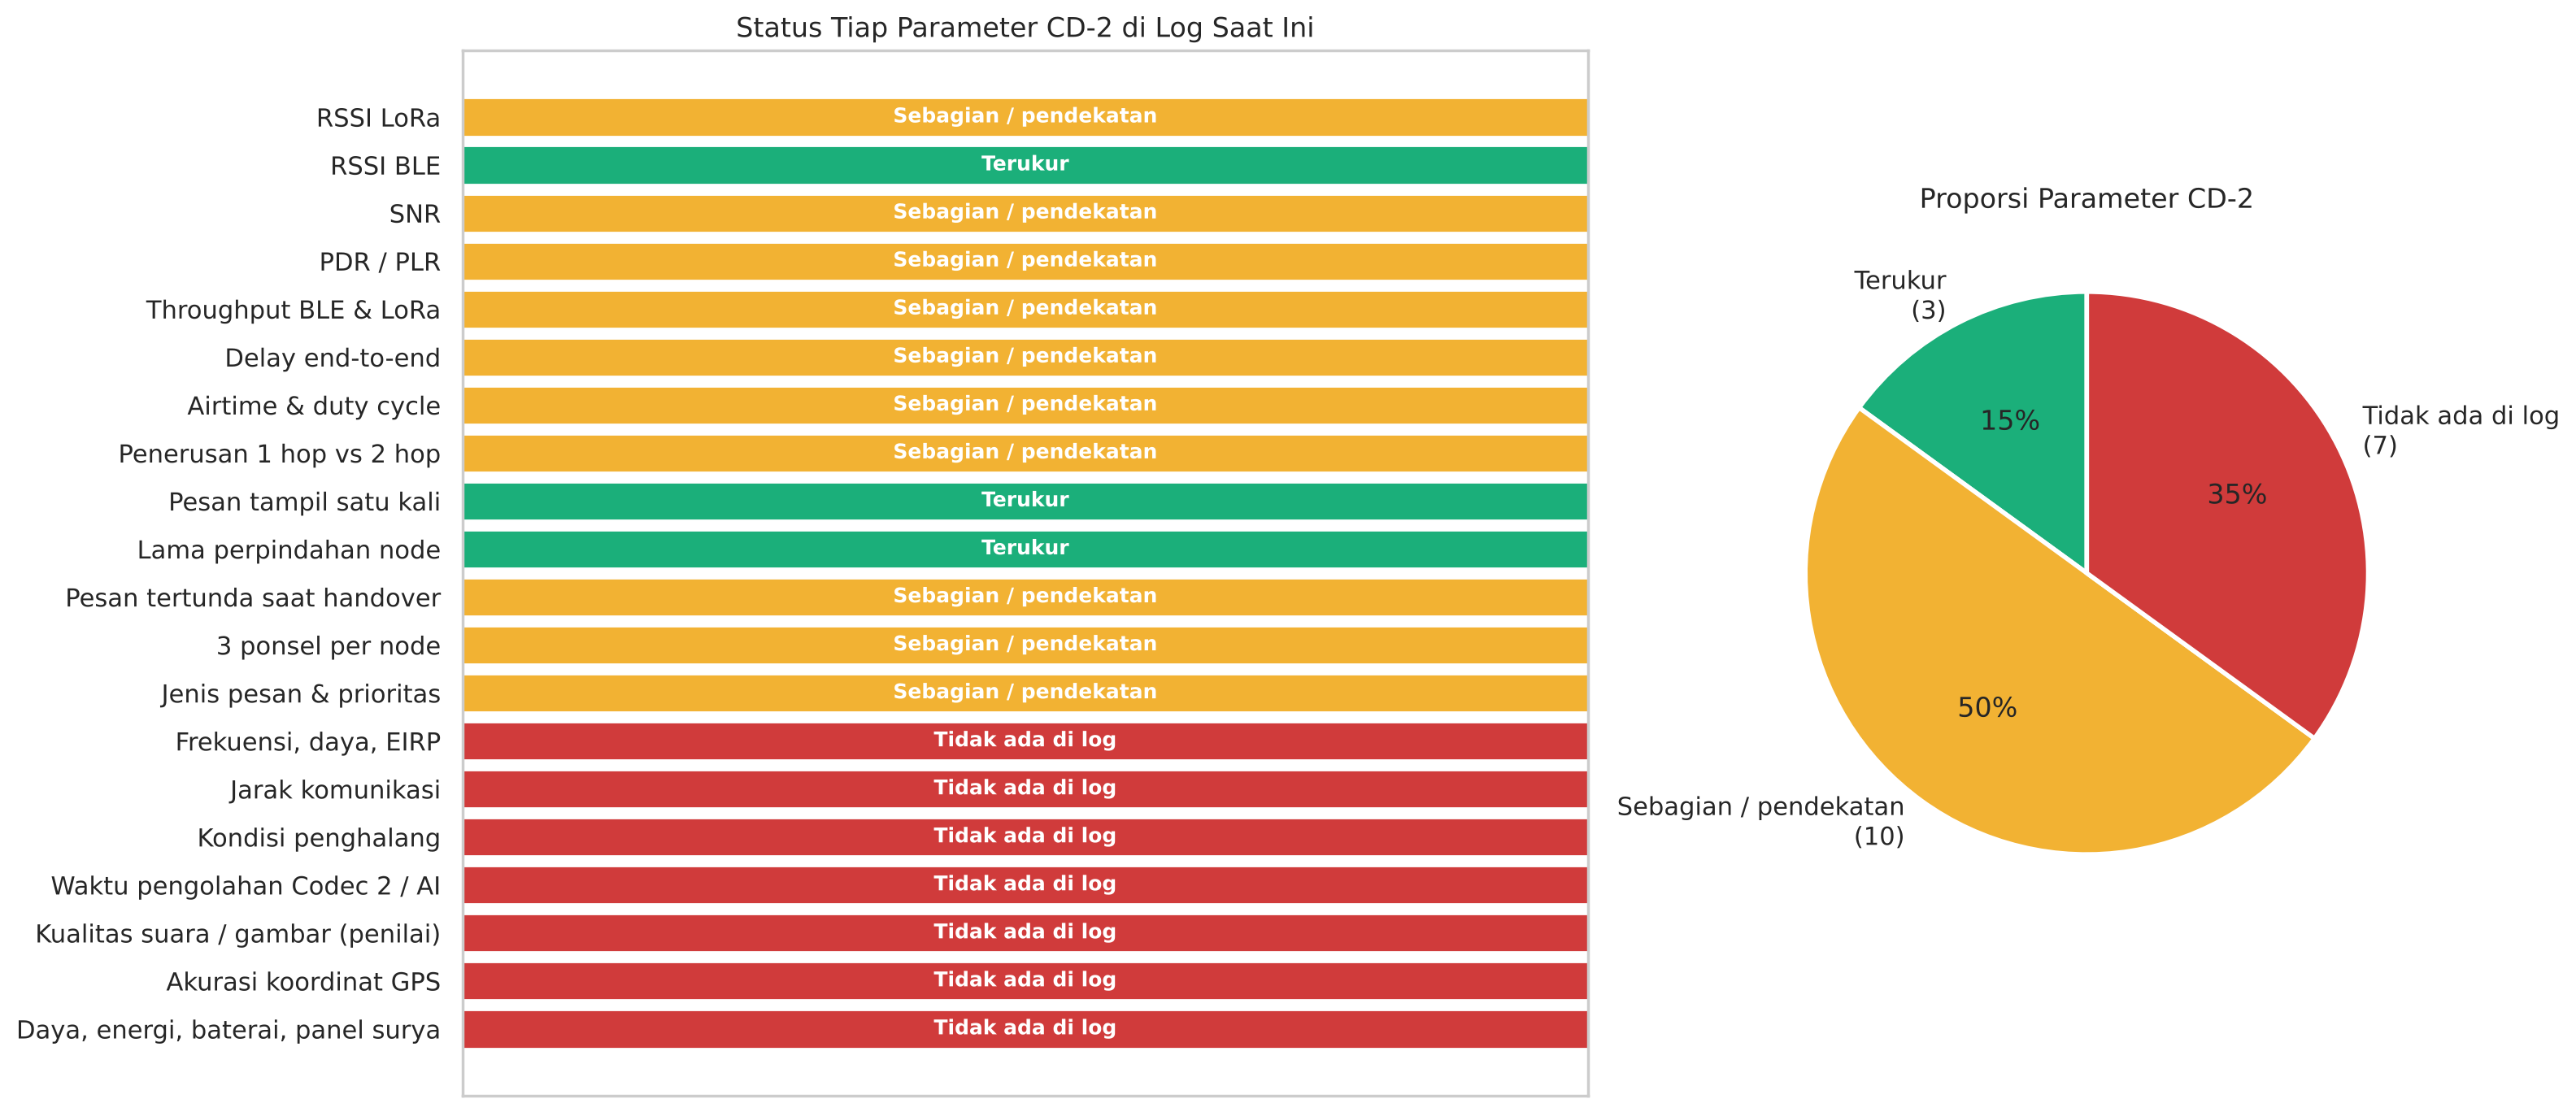

In [82]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={'width_ratios': [1.6, 1]})
warna_status = {2: '#1baf7a', 1: '#f2b233', 0: '#d03b3b'}

m = matriks_cd2.iloc[::-1]
axes[0].barh(m['parameter'], [1] * len(m), color=m['skor'].map(warna_status))
for i, s in enumerate(m['status']):
    axes[0].text(0.5, i, s, ha='center', va='center', color='white', fontweight='bold', fontsize=9)
axes[0].set_xticks([]); axes[0].set_xlim(0, 1)
axes[0].set_title('Status Tiap Parameter CD-2 di Log Saat Ini')

jumlah = matriks_cd2['skor'].value_counts().reindex([2, 1, 0]).fillna(0)
axes[1].pie(jumlah, labels=[f'{STATUS[k]}\n({int(v)})' for k, v in jumlah.items()],
            colors=[warna_status[k] for k in jumlah.index], autopct='%1.0f%%', startangle=90,
            wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[1].set_title('Proporsi Parameter CD-2')
plt.tight_layout(); plt.show()

**Interpretasi:**
- Dari **20 parameter/pemeriksaan CD-2**, hanya **3 (15%) yang terukur penuh** dari log: RSSI BLE, pesan tampil satu kali, dan lama perpindahan node.
- **10 (50%) terukur sebagian/pendekatan.** Data dasarnya ada, tetapi metodenya belum sesuai CD-2 (tanpa jarak, tanpa paket bernomor, tanpa log penerima, dan baru 2 pengguna per node).
- **7 (35%) tidak ada di log sama sekali.** Sebagian karena memang diukur manual (daya, kualitas suara/gambar), sebagian karena aplikasi belum mencatatnya (jarak, waktu pengolahan, konfigurasi radio, GPS).
- **Kesimpulan:** log sesi ini cukup untuk **uji fungsional** sistem, tetapi belum cukup untuk **verifikasi spesifikasi** CD-2. Bagian 10 menjelaskan apa yang perlu ditambahkan.

# **10. Evaluasi Kualitas Log dan Saran Peningkatan Logging**

Log 12 November ini adalah sesi logging NusaMesh tanggal 12 November 2026. Bagian ini mengukur kekurangan log secara langsung dari data, lalu menyusun saran apa yang perlu ditambahkan di aplikasi dan firmware supaya semua parameter CD-2 bisa diukur.

## 10.1 Mengukur Kekurangan Log

In [83]:
mentah = pd.concat([pd.read_csv(f, dtype=str) for f in daftar_file], ignore_index=True)
kosong = (mentah.replace(['', 'null', 'NULL', 'NaN', 'None'], np.nan).isna().mean() * 100).round(1)

kualitas_log = pd.Series({
    'Baris mentah (semua file)': len(mentah),
    'Baris duplikat antar file': int(mentah.duplicated(['session_id', 'sequence']).sum()),
    'Jumlah sesi': mentah['session_id'].nunique(),
    'Nilai test_mode = true': int(df['test_mode'].astype(str).str.lower().eq('true').sum()),
    'Format device_id berbeda (node hex / MAC / ID pengguna)': int(df['device_id'].dropna().map(
        lambda x: 'mac' if ':' in str(x) else ('node' if str(x).startswith('4e55534e') else 'lain')).nunique()),
    'MAC BLE yang tidak bisa dipetakan ke node': int(df.loc[df['device_id'].astype(str).str.contains(':'), 'device_id']
                                                      .map(mac_ke_node).isna().groupby(df['device_id']).any().sum()),
    'Kunci berbeda di kolom detail (teks bebas)': int(df['detail'].dropna().str.findall(r'([a-z_ ]+)=').explode().str.strip().nunique()),
    'Laporan NODE_HEALTH berjarak < 1 detik': int((health['jeda_detik'] < 1).sum()),
    'serving_rssi bernilai null saat handover': int(df.loc[df['event'].str.startswith('MOBILITY'), 'detail']
                                                    .str.contains('serving_rssi=null').sum()),
}, name='nilai').to_frame()
kualitas_log

,nilai
Baris mentah (semua file),3872
Baris duplikat antar file,0
Jumlah sesi,1
Nilai test_mode = true,0
Format device_id berbeda (node hex / MAC / ID pengguna),3
MAC BLE yang tidak bisa dipetakan ke node,8
Kunci berbeda di kolom detail (teks bebas),38
Laporan NODE_HEALTH berjarak < 1 detik,2
serving_rssi bernilai null saat handover,105


**Yang dilakukan cell berikut:**
- `(a)` Persentase kosong per kolom
- `(b)` Jarak antar laporan NODE_HEALTH

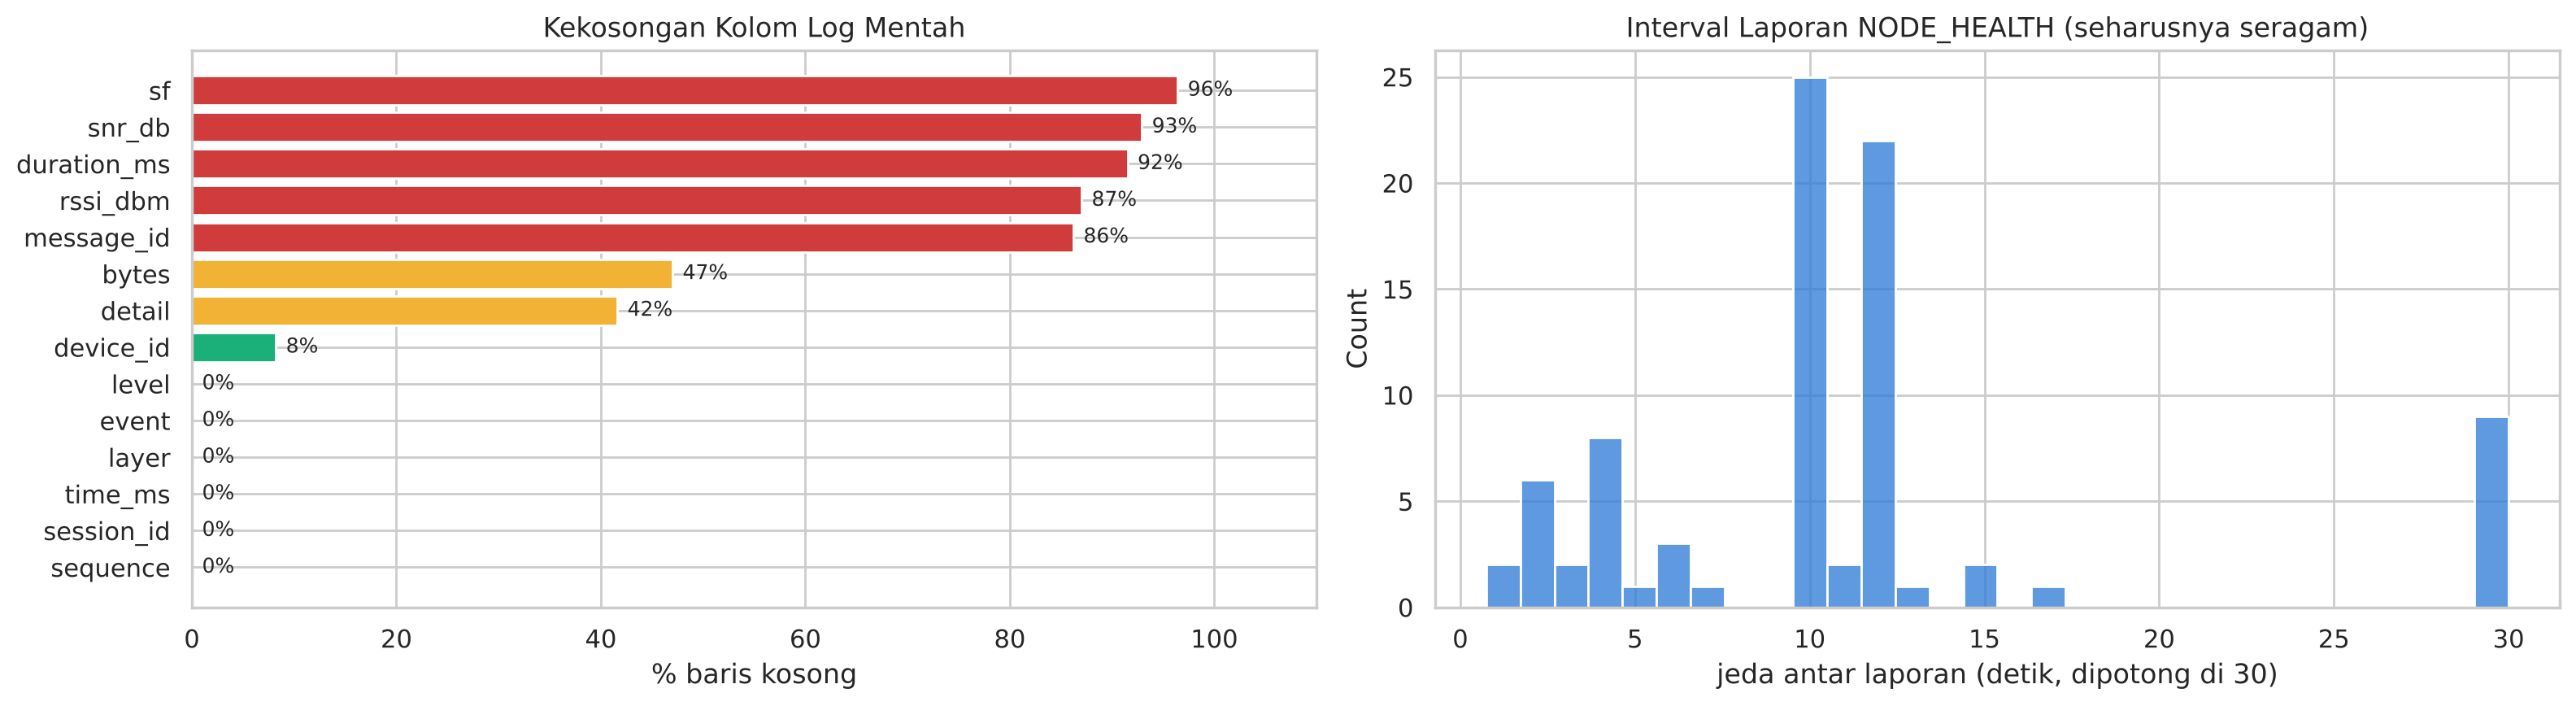

In [84]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))

k = kosong.sort_values()
axes[0].barh(k.index, k.values, color=['#d03b3b' if v > 80 else '#f2b233' if v > 20 else '#1baf7a' for v in k.values])
for i, v in enumerate(k.values):
    axes[0].text(v + 1, i, f'{v:.0f}%', va='center', fontsize=9)
axes[0].set_xlim(0, 110); axes[0].set_xlabel('% baris kosong')
axes[0].set_title('Kekosongan Kolom Log Mentah')

sns.histplot(health['jeda_detik'].dropna().clip(upper=30), bins=30, color='#2a78d6', ax=axes[1])
axes[1].set_xlabel('jeda antar laporan (detik, dipotong di 30)')
axes[1].set_title('Interval Laporan NODE_HEALTH (seharusnya seragam)')
plt.tight_layout(); plt.show()

**Interpretasi:**
- **Tidak ada baris dobel (0)** karena sesi ini hanya punya satu file log.
- **`test_mode` tidak pernah `true`**: sesi ini bukan sesi uji QoS.
- Kolom `device_id` berisi **3 format berbeda** (ID node hex, MAC BLE, ID pengguna), dan **8 MAC tidak bisa dipetakan** ke node.
- Kolom `detail` berisi **38 kunci berbeda** dalam teks bebas, sehingga semuanya harus di-parse manual.
- Kolom `sf`, `snr_db`, `duration_ms`, dan `rssi_dbm` kosong di **87–96%** baris. Kosongnya wajar (hanya diisi event tertentu), tapi artinya informasi radio hanya ada di sedikit baris.
- Interval `NODE_HEALTH` tersebar dari **0,7 detik sampai 508 detik** (median ±10 detik), padahal seharusnya seragam. Ada 2 laporan berjarak < 1 detik, dan jeda panjang muncul saat HP tidak terhubung ke node.
- `serving_rssi` bernilai **null di semua 105 event mobilitas**.

## 10.2 Masalah Log yang Ditemukan dan Perbaikannya

| No | Masalah di log sekarang | Bukti | Dampak ke analisis | Saran perbaikan |
|---|---|---|---|---|
| 1 | **Tidak ada sesi uji** | `test_mode` selalu `false` | PDR, throughput, dan delay versi CD-2 tidak bisa dihitung | Jalankan Menu Uji QoS dengan `test_mode=true` dan simpan `test_id` di setiap baris |
| 2 | **Hanya log sisi pengirim** | satu `session_id`, satu ponsel | Delay end-to-end dan PDR di penerima tidak ada | Ekspor log dari **semua** ponsel (pengirim & penerima), gabungkan berdasarkan `message_id` |
| 3 | **Tidak ada jarak & kondisi** | tidak ada kolom jarak | Grafik RSSI/PDR vs jarak tidak bisa dibuat | Tambah metadata sesi: `jarak_m`, `kondisi` (LOS/terhalang), `tinggi_antena_m`, koordinat GPS kedua node |
| 4 | **ID perangkat campur aduk** | node hex, MAC BLE, dan ID pengguna di satu kolom; beberapa MAC tidak bisa dipetakan | Butuh pemetaan manual lewat beacon | Pisahkan kolom `node_id`, `ble_mac`, `user_id`; log tabel MAC↔node saat terhubung |
| 5 | **Kolom `detail` berupa teks bebas** | puluhan kunci berbeda, campur kalimat ("Antrean radio penuh") | Harus di-parse manual, rawan salah | Simpan sebagai kolom terstruktur atau JSON; pisahkan `reason_code` dari pesan teks |
| 6 | **Hop tidak tercatat** | hop ditaksir dari TTL | Uji 1 hop vs 2 hop tidak pasti | Log `hop_count`, `ttl_awal`, `ttl_sisa`, dan `relay_path` di setiap paket diterima |
| 7 | **Airtime per frame tidak tercatat** | hanya counter `tx` dan `budget_ms` | Duty cycle hanya perkiraan (rentang lebar) | Log `airtime_ms` setiap frame TX dan total airtime per jam per node; jelaskan panjang jendela `budget_ms` |
| 8 | **Konfigurasi radio tidak lengkap** | frekuensi & daya TX tidak ada | Pemeriksaan EIRP & regulasi tidak bisa | Log `freq_mhz`, `tx_power_dbm`, `bw_khz`, `sf`, `cr`, `gain_antena_dbi` saat boot & saat diubah |
| 9 | **Jenis pesan tidak dibedakan** | hanya pesan vs file; kode `type` tanpa label | Suara/gambar/lokasi & prioritas tidak bisa dinilai | Field `jenis` = teks/SOS/suara/gambar/lokasi dan `prioritas`; dokumentasikan arti kode `type` |
| 10 | **Waktu pengolahan tidak dicatat** | tidak ada event encode/upscale | Parameter waktu pengolahan CD-2 kosong | Event `CODEC2_ENCODE`, `CODEC2_DECODE`, `IMG_DOWNSCALE`, `IMG_UPSCALE` + `duration_ms` + model yang dipakai |
| 11 | **RSSI BLE saat handover null** | `serving_rssi=null` | Kualitas BLE saat pindah node tidak terukur | Isi `serving_rssi` dan `target_rssi` saat handover |
| 12 | **File terpecah & duplikat** | sesi ini sudah satu file (0 baris dobel); sesi 11 November sempat terpecah 2 file | Kalau terpecah, harus dedup dulu | Pertahankan satu file ekspor per sesi, nama file berisi `session_id` |
| 13 | **Interval health tidak seragam** | jeda 0,7–508 detik, ada 2 laporan berjarak < 1 detik | Laju per detik bisa melonjak palsu | Kirim `NODE_HEALTH` dengan interval tetap (mis. 5 s) + counter delta, bukan hanya kumulatif |
| 14 | **Jam belum disinkronkan** | tidak ada info offset jam | Delay antar ponsel tidak valid | Catat `clock_offset_ms` (sinkron NTP/GPS sebelum Wi-Fi mati) di awal sesi |
| 15 | **Data daya tidak ada** | node hanya baca tegangan | Parameter daya/baterai kosong | Log `battery_mv` periodik di node + gabungkan dengan logger V/I eksternal berdasarkan timestamp |

## 10.3 Usulan Skema Log Uji (Menu Uji QoS)

Supaya setiap parameter Tabel 1.3 bisa dihitung langsung, **ponsel penerima** sebaiknya mengekspor satu baris per paket uji dengan kolom berikut:

| Kolom | Contoh | Dipakai untuk parameter |
|---|---|---|
| `test_id` | `uji-500m-los-01` | pengelompokan sesi |
| `skenario` | `1hop` / `2hop` / `handover` | penerusan pesan |
| `jarak_m`, `kondisi` | `500`, `LOS` | jangkauan, RSSI vs jarak |
| `seq`, `total_rencana` | `37`, `100` | **PDR/PLR** |
| `jenis`, `ukuran_byte` | `teks`, `48` | jenis pesan, throughput |
| `waktu_kirim_ms` (dari payload) | `1794387770595` | **delay end-to-end** |
| `waktu_terima_ms` | `1794387771013` | delay, throughput |
| `rssi_dbm`, `snr_db` | `-92`, `7.5` | RSSI, SNR |
| `hop_count`, `relay_path` | `2`, `NUSN-3>NUSN-2` | hop |
| `node_pengirim`, `node_penerima` | `NUSN-1`, `NUSN-2` | koneksi antarnode |
| `airtime_ms` | `97.5` | airtime, duty cycle |
| `freq_mhz`, `sf`, `bw_khz`, `tx_power_dbm` | `921.0`, `7`, `125`, `14` | konfigurasi radio |
| `clock_offset_ms` | `+12` | koreksi delay |

Contoh baris CSV:
```
test_id,skenario,jarak_m,kondisi,seq,total_rencana,jenis,ukuran_byte,waktu_kirim_ms,waktu_terima_ms,rssi_dbm,snr_db,hop_count,relay_path,node_pengirim,node_penerima,airtime_ms,freq_mhz,sf,bw_khz,tx_power_dbm,clock_offset_ms
uji-500m-los-01,1hop,500,LOS,37,100,teks,48,1794387770595,1794387771013,-92,7.5,1,,NUSN-1,NUSN-2,97.5,921.0,7,125,14,12
```

Dengan skema ini, rumus PDR, throughput, dan delay CD-2 bisa langsung dihitung:

$$PDR = \frac{\text{jumlah } seq \text{ unik diterima}}{total\_rencana} \times 100\% \qquad D = t_{terima} - t_{kirim} - \Delta_{jam}$$

$$\text{Throughput} = \frac{\sum ukuran\_byte \times 8}{t_{terima,akhir} - t_{terima,awal}}$$

# **11. Kesimpulan**

**A. Kualitas layanan (QoS, standar TIPHON)**

| Parameter | Keseluruhan | Fase 1 (gangguan awal) | Fase 2 (relatif stabil) | Fase 3 (koneksi putus) |
|---|---|---|---|---|
| Throughput (efisiensi) | 81,0% (3) | 69,3% (2) | **94,0% (3)** | 36,4% (1) |
| Packet loss (aplikasi) | 32,8% (1) | 15,0% (2) | **16,7% (2)** | 76,5% (1) |
| Delay jaringan (rata-rata) | 551 ms (1) | 518 ms (1) | **407 ms (2)** | 1.150 ms (1) |
| Jitter jaringan | 340 ms (1) | 399 ms (1) | **108 ms (2)** | 947 ms (1) |
| **Indeks QoS jaringan** | 1,50 Jelek | 1,50 Jelek | **2,25 Kurang memuaskan** | 1,00 Jelek |
| **Indeks QoS pengguna** (termasuk antrean) | 1,50 Jelek | 1,50 Jelek | 1,75 Jelek | 1,00 Jelek |

**B. Temuan dan rekomendasi**

| No | Temuan | Bukti | Rekomendasi |
|---|---|---|---|
| 1 | **Airtime node hampir selalu habis** | sisa budget NUSN-3 median ±200 ms dari 8.000 ms; terpakai maks 93–95%; 121 frame dibuang (loss antrean 23,8%) | Perjarang beacon, batasi relay dan duplikat, serta tahan pengiriman dari aplikasi sebelum budget habis |
| 2 | **Koneksi BLE HP ↔ node tidak stabil** | 93 error BLE: NUSN-3 di awal sesi (25 GATT error), NUSN-1 di akhir sesi (21 gagal connect); RSSI BLE NUSN-1 median −90 dBm | Dekatkan HP ke node atau naikkan daya TX BLE node; tambah reconnect otomatis yang lebih cepat |
| 3 | **Fase 3: HP tidak bisa terhubung ke node** | 13 dari 20 pesan gagal terjadi setelah 13:28; loss aplikasi 76,5% | Cek NUSN-3 (berhenti aktif setelah 13:24–13:29) dan posisi HP terhadap NUSN-1 |
| 4 | **Radio NUSN-1 sempat tidak siap** | `radio_ready=false` 13:24:31–13:26:23 (radio siap 73,2%) | Cek firmware/power radio NUSN-1 saat terjadi reset |
| 5 | **Sinyal LoRa umumnya sehat, tetapi NUSN-3 sempat jatuh** | ±78% frame SNR ≥ 5 dB; NUSN-3 turun ke −130 dBm / SNR −9 dB pada 13:22–13:23 | Cek posisi/antena NUSN-3 dan penghalang di sekitarnya |
| 6 | **Masalah dipicu beban trafik dan sinyal lemah** | Mann-Whitney: RSSI p = 0,009, beban kirim p = 0,013, SNR p = 0,33 | Atur laju kirim dan tambahkan jeda acak (*backoff*); pastikan posisi node baik |
| 7 | **Handover bolak-balik (ping-pong)** | 6 handover NUSN-1 ↔ NUSN-3 dalam 5 menit (13:16–13:21) | Tambahkan histeresis RSSI/waktu tunggu minimum sebelum pindah node |
| 8 | **Penerusan mesh berjalan, duplikat tersaring** | 17% paket data lewat 2 hop; 0 pesan tampil dobel; tetapi duplikat 13,9% | Kurangi relay ganda; uji skenario A→B→C terkontrol untuk membandingkan 1 vs 2 hop |
| 9 | **Satu file melebihi batas gambar CD-2** | 7.926 byte (batas 1.200 byte), status tidak selesai; 24 fragmen hilang | Perketat kompresi gambar; uji transfer media terpisah |
| 10 | **Skenario 3 ponsel per node belum teruji** | maksimal 2 pengguna per node | Jalankan skenario 3 pengguna sesuai Tabel 1.4 |

**C. Status parameter CD-2 di log ini** (detail di 9.8)

| Terukur penuh | Sebagian / pendekatan | Tidak ada di log |
|---|---|---|
| 3 (15%) | 10 (50%) | 7 (35%) |

Log sesi ini cukup sebagai **uji fungsional**, tetapi belum cukup untuk **verifikasi spesifikasi CD-2**. Prioritas perbaikan logging (bagian 10.2):
1. Sesi uji bernomor (`test_mode`, `seq`, `total_rencana`) dan log dari ponsel penerima, untuk PDR dan delay end-to-end.
2. Metadata jarak dan kondisi penghalang, untuk RSSI/SNR/PDR vs jarak.
3. Hop count, airtime per frame, dan konfigurasi radio (frekuensi, daya TX).
4. Jenis pesan, waktu pengolahan Codec 2 / AI, dan ID perangkat yang konsisten.

Catatan: data hanya dari **satu sesi sekitar 27 menit** dengan 2 node aktif (NUSN-1 dan NUSN-3), jadi temuan ini perlu dikonfirmasi dengan sesi uji tambahan. ACK rate rendah belum bisa disebut kegagalan sebelum dicocokkan dengan log di sisi penerima.

# **12. Mengekspor Data**
Simpan tabel hasil cleaning, tabel analisis, dan dataset ML ke file CSV, lalu kompres jadi satu zip.

**Yang dilakukan cell berikut:**
- Tabel analisis QoS dan parameter CD-2

In [85]:
df.to_csv(os.path.join(OUT_DIR, 'nusamesh_bersih.csv'), index=False)
health.to_csv(os.path.join(OUT_DIR, 'tabel_kesehatan_node.csv'), index=False)
sinyal.to_csv(os.path.join(OUT_DIR, 'tabel_sinyal_lora.csv'), index=False)
pesan.to_csv(os.path.join(OUT_DIR, 'tabel_pesan.csv'))
fitur.to_csv(os.path.join(OUT_DIR, 'dataset_ml_window.csv'))
X_train_scaled.assign(y=y_train).to_csv(os.path.join(OUT_DIR, 'dataset_ml_train_scaled.csv'))
X_test_scaled.assign(y=y_test).to_csv(os.path.join(OUT_DIR, 'dataset_ml_test_scaled.csv'))

tabel_qos.to_csv(os.path.join(OUT_DIR, 'tabel_qos_tiphon.csv'))
pdr.to_csv(os.path.join(OUT_DIR, 'tabel_pdr_per_lapisan.csv'))
tabel_rssi_snr.to_csv(os.path.join(OUT_DIR, 'tabel_rssi_snr.csv'))
tabel_rssi_ble.to_csv(os.path.join(OUT_DIR, 'tabel_rssi_ble.csv'))
paket_data.to_csv(os.path.join(OUT_DIR, 'tabel_hop_paket.csv'), index=False)
duty_cycle.to_csv(os.path.join(OUT_DIR, 'tabel_duty_cycle.csv'))
matriks_cd2.to_csv(os.path.join(OUT_DIR, 'matriks_parameter_cd2.csv'), index=False)

os.listdir(OUT_DIR)

['tabel_sinyal_lora.csv',
 'tabel_pdr_per_lapisan.csv',
 'tabel_kesehatan_node.csv',
 'dataset_ml_train_scaled.csv',
 'dataset_ml_window.csv',
 'nusamesh_bersih.csv',
 'dataset_ml_test_scaled.csv',
 'tabel_rssi_snr.csv',
 'tabel_rssi_ble.csv',
 'tabel_qos_tiphon.csv',
 'tabel_pesan.csv',
 'matriks_parameter_cd2.csv',
 'tabel_hop_paket.csv',
 'tabel_duty_cycle.csv']

In [86]:
import shutil
zip_path = shutil.make_archive(os.path.join(DATA_DIR, 'nusamesh_output'), 'zip', OUT_DIR)

try:
    from google.colab import files
    files.download(zip_path)
except ImportError:
    print('File zip tersimpan di:', zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>